# SHL Hiring Assessment 2026 — Grammar Scoring Engine
## V2: Multimodal ensemble with transcript diversity

**Goal:** build a strong, reproducible grammar-scoring pipeline while keeping the implementation independent.

### Pipeline
1. Data validation and exploratory analysis
2. Fixed 5-fold stratified CV
3. Whisper large-v3 canonical transcript
4. Whisper verbatim transcript
5. Literal wav2vec2 CTC transcript
6. DeBERTa-base and DeBERTa-large regression ensembles
7. WavLM frozen embeddings + RBF-SVR
8. OOF-only model comparison and blending
9. Cross-fitted calibration
10. Final 0–5 predictions and submission validation



In [ ]:
# ============================================================
# 1. CONFIGURATION
# ============================================================
import os, gc, re, json, math, random, warnings, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = Path("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final")
TRAIN_CSV = DATA_DIR / "train.csv"
TEST_CSV = DATA_DIR / "test.csv"
TRAIN_AUDIO_DIR = DATA_DIR / "train"
TEST_AUDIO_DIR = DATA_DIR / "test"

WORK_DIR = Path("/kaggle/working/shl_grammar_v2")
TRANSCRIPT_DIR = WORK_DIR / "transcripts"
EMBEDDING_DIR = WORK_DIR / "embeddings"
MODEL_DIR = WORK_DIR / "models"
OOF_DIR = WORK_DIR / "oof"
SUBMISSION_DIR = WORK_DIR / "submission"

for d in [WORK_DIR, TRANSCRIPT_DIR, EMBEDDING_DIR, MODEL_DIR, OOF_DIR, SUBMISSION_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("DATA_DIR:", DATA_DIR)
print("WORK_DIR:", WORK_DIR)


DATA_DIR: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final
WORK_DIR: /kaggle/working/shl_grammar_v2


In [ ]:
# ============================================================
# 1. CONFIGURATION
# ============================================================

import os
import gc
import re
import json
import math
import random
import warnings
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)


# ============================================================
# DEVICE
# ============================================================

import torch

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("DEVICE:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# ORIGINAL COMPETITION DATA
# ============================================================

DATA_DIR = Path(
    "/kaggle/input/competitions/"
    "shl-hiring-assessment-2026/Dataset_Final"
)

TRAIN_CSV = DATA_DIR / "train.csv"
TEST_CSV = DATA_DIR / "test.csv"

TRAIN_AUDIO_DIR = DATA_DIR / "train"
TEST_AUDIO_DIR = DATA_DIR / "test"


# ============================================================
# PREVIOUS SESSION / ATTEMPT-2
# ============================================================

PREVIOUS_DIR = Path(
    "/kaggle/input/notebooks/vjx021/attempt-2"
)

PREVIOUS_TRANSCRIPT_DIR = (
    PREVIOUS_DIR / "shl_grammar_v2" / "transcripts"
)

PREVIOUS_OOF_DIR = (
    PREVIOUS_DIR / "shl_grammar_v2" / "oof"
)


# ============================================================
# CURRENT SESSION WORKING DIRECTORY
# ============================================================

WORK_DIR = Path(
    "/kaggle/working/shl_grammar_v2"
)

TRANSCRIPT_DIR = (
    WORK_DIR / "transcripts"
)

EMBEDDING_DIR = (
    WORK_DIR / "embeddings"
)

MODEL_DIR = (
    WORK_DIR / "models"
)

OOF_DIR = (
    WORK_DIR / "oof"
)

SUBMISSION_DIR = (
    WORK_DIR / "submission"
)


# ============================================================
# CREATE WORKING DIRECTORIES
# ============================================================

for directory in [
    WORK_DIR,
    TRANSCRIPT_DIR,
    EMBEDDING_DIR,
    MODEL_DIR,
    OOF_DIR,
    SUBMISSION_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# COPY PREVIOUS TRANSCRIPTS INTO WORKING DIRECTORY
# ============================================================
# We copy them once so the rest of the notebook can continue
# using TRANSCRIPT_DIR exactly as before.
# ============================================================

TRANSCRIPT_FILES = [
    "canonical.csv",
    "canonical_test.csv",
    "ctc.csv",
    "ctc_test.csv",
    "verbatim.csv",
    "verbatim_test.csv"
]

print("=" * 70)
print("IMPORTING PREVIOUS TRANSCRIPTS")
print("=" * 70)

for filename in TRANSCRIPT_FILES:

    source = (
        PREVIOUS_TRANSCRIPT_DIR
        / filename
    )

    destination = (
        TRANSCRIPT_DIR
        / filename
    )

    if not source.exists():

        raise FileNotFoundError(
            f"Previous transcript not found:\n{source}"
        )

    shutil.copy2(
        source,
        destination
    )

    print(
        f"✓ {filename}"
    )


# ============================================================
# COPY PREVIOUS OOF PREDICTIONS
# ============================================================

OOF_FILES = [
    "base_canonical_oof.npy",
    "base_canonical_test.npy"
]

print("\n" + "=" * 70)
print("IMPORTING PREVIOUS OOF PREDICTIONS")
print("=" * 70)

for filename in OOF_FILES:

    source = (
        PREVIOUS_OOF_DIR
        / filename
    )

    destination = (
        OOF_DIR
        / filename
    )

    if not source.exists():

        raise FileNotFoundError(
            f"Previous OOF file not found:\n{source}"
        )

    shutil.copy2(
        source,
        destination
    )

    print(
        f"✓ {filename}"
    )


# ============================================================
# VERIFY TRANSCRIPTS
# ============================================================

print("\n" + "=" * 70)
print("TRANSCRIPT VERIFICATION")
print("=" * 70)

for filename in TRANSCRIPT_FILES:

    path = (
        TRANSCRIPT_DIR
        / filename
    )

    df = pd.read_csv(path)

    print(
        f"{filename:<20} "
        f"rows={len(df):,} "
        f"cols={len(df.columns)}"
    )


# ============================================================
# VERIFY OOF FILES
# ============================================================

print("\n" + "=" * 70)
print("OOF VERIFICATION")
print("=" * 70)

for filename in OOF_FILES:

    path = (
        OOF_DIR
        / filename
    )

    arr = np.load(path)

    print(
        f"{filename:<30} "
        f"shape={arr.shape} "
        f"dtype={arr.dtype}"
    )


# ============================================================
# PATH SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("PATH CONFIGURATION")
print("=" * 70)

print("PREVIOUS_DIR   :", PREVIOUS_DIR)
print("WORK_DIR       :", WORK_DIR)
print("TRANSCRIPT_DIR :", TRANSCRIPT_DIR)
print("OOF_DIR        :", OOF_DIR)
print("MODEL_DIR      :", MODEL_DIR)

DEVICE: cuda
GPU: Tesla T4
IMPORTING PREVIOUS TRANSCRIPTS
✓ canonical.csv
✓ canonical_test.csv
✓ ctc.csv
✓ ctc_test.csv
✓ verbatim.csv
✓ verbatim_test.csv

IMPORTING PREVIOUS OOF PREDICTIONS
✓ base_canonical_oof.npy
✓ base_canonical_test.npy

TRANSCRIPT VERIFICATION
canonical.csv        rows=769 cols=2
canonical_test.csv   rows=216 cols=2
ctc.csv              rows=769 cols=2
ctc_test.csv         rows=216 cols=2
verbatim.csv         rows=769 cols=2
verbatim_test.csv    rows=216 cols=2

OOF VERIFICATION
base_canonical_oof.npy         shape=(769,) dtype=float32
base_canonical_test.npy        shape=(216,) dtype=float32

PATH CONFIGURATION
PREVIOUS_DIR   : /kaggle/input/notebooks/vjx021/attempt-2
WORK_DIR       : /kaggle/working/shl_grammar_v2
TRANSCRIPT_DIR : /kaggle/working/shl_grammar_v2/transcripts
OOF_DIR        : /kaggle/working/shl_grammar_v2/oof
MODEL_DIR      : /kaggle/working/shl_grammar_v2/models


In [ ]:
# ============================================================
# LOAD ONLY LARGE_CTC CHECKPOINTS FROM PREVIOUS ATTEMPT
# ============================================================

import torch
from pathlib import Path

# Read-only source: previous notebook artifacts
PREVIOUS_MODEL_DIR = (
    PREVIOUS_DIR
    / "shl_grammar_v2"
    / "models"
    / "large_ctc"
)

print("=" * 70)
print("LARGE_CTC CHECKPOINTS")
print("=" * 70)

if not PREVIOUS_MODEL_DIR.exists():
    raise FileNotFoundError(
        f"Previous CTC model directory not found:\n"
        f"{PREVIOUS_MODEL_DIR}"
    )

CTC_CHECKPOINTS = {}

for fold in range(5):

    checkpoint_path = (
        PREVIOUS_MODEL_DIR
        / f"seed7_fold{fold}.pt"
    )

    if not checkpoint_path.exists():
        print(f"Fold {fold}: checkpoint not available")
        continue

    try:
        # Validate the checkpoint without copying it.
        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        CTC_CHECKPOINTS[fold] = checkpoint

        print(
            f"Fold {fold}: loaded successfully | "
            f"{checkpoint_path.stat().st_size / (1024**2):.2f} MB"
        )

        del checkpoint

    except Exception as e:
        print(
            f"Fold {fold}: INVALID checkpoint | {e}"
        )

print("\nValid CTC checkpoints:", sorted(CTC_CHECKPOINTS.keys()))
print("Source directory:", PREVIOUS_MODEL_DIR)
print("No model checkpoints were copied to /kaggle/working.")

LARGE_CTC CHECKPOINTS
Fold 0: loaded successfully | 1659.76 MB
Fold 1: loaded successfully | 1659.76 MB
Fold 2: checkpoint not available
Fold 3: checkpoint not available
Fold 4: checkpoint not available

Valid CTC checkpoints: [0, 1]
Source directory: /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/models/large_ctc
No model checkpoints were copied to /kaggle/working.


In [ ]:
# ============================================================
# RESTORE ALL AVAILABLE ARTIFACTS FROM ATTEMPT 2
# ============================================================

import shutil
from pathlib import Path

SOURCE_DIR = (
    Path("/kaggle/input/notebooks/vjx021/attempt-2")
    / "shl_grammar_v2"
)

DEST_DIR = Path("/kaggle/working/shl_grammar_v2")

if not SOURCE_DIR.is_dir():
    raise FileNotFoundError(
        f"Previous artifact directory not found: {SOURCE_DIR}"
    )

# ------------------------------------------------------------
# COPY THE ENTIRE DIRECTORY TREE
# ------------------------------------------------------------

print("Source:", SOURCE_DIR)
print("Destination:", DEST_DIR)
print("\nCopying all available artifacts...")

shutil.copytree(
    SOURCE_DIR,
    DEST_DIR,
    dirs_exist_ok=True,
    copy_function=shutil.copy2
)

# ------------------------------------------------------------
# VERIFY ALL COPIED FILES
# ------------------------------------------------------------

source_files = {
    str(p.relative_to(SOURCE_DIR))
    for p in SOURCE_DIR.rglob("*")
    if p.is_file()
}

destination_files = {
    str(p.relative_to(DEST_DIR))
    for p in DEST_DIR.rglob("*")
    if p.is_file()
}

missing_files = sorted(
    source_files - destination_files
)

print("\n" + "=" * 65)
print("RESTORATION SUMMARY")
print("=" * 65)

print("Files exposed in previous notebook:", len(source_files))
print("Files present in working directory:", len(destination_files))
print("Files missing after copy:", len(missing_files))

if missing_files:
    print("\nMissing files:")
    for filename in missing_files:
        print(" ", filename)
else:
    print("\nAll exposed files have been copied.")

# ------------------------------------------------------------
# SHOW RESTORED MODEL CHECKPOINTS
# ------------------------------------------------------------

print("\nMODEL CHECKPOINTS")

for model_file in sorted(
    (DEST_DIR / "models").rglob("*.pt")
) if (DEST_DIR / "models").exists() else []:
    print(
        f"{model_file.relative_to(DEST_DIR)} "
        f"({model_file.stat().st_size / 1e6:.1f} MB)"
    )

# ------------------------------------------------------------
# SHOW RESTORED ARTIFACT COUNTS
# ------------------------------------------------------------

print("\nFILES BY DIRECTORY")

for subdir in sorted(p for p in DEST_DIR.iterdir() if p.is_dir()):
    count = sum(1 for p in subdir.rglob("*") if p.is_file())
    print(f"{subdir.name:<20} {count:>5} files")

Source: /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2
Destination: /kaggle/working/shl_grammar_v2

Copying all available artifacts...

RESTORATION SUMMARY
Files exposed in previous notebook: 23
Files present in working directory: 23
Files missing after copy: 0

All exposed files have been copied.

MODEL CHECKPOINTS
models/large_canonical/seed7_fold0.pt (1740.4 MB)
models/large_canonical/seed7_fold1.pt (1740.4 MB)
models/large_canonical/seed7_fold2.pt (1740.4 MB)
models/large_canonical/seed7_fold3.pt (1740.4 MB)
models/large_canonical/seed7_fold4.pt (1740.4 MB)
models/large_ctc/seed7_fold0.pt (1740.4 MB)
models/large_verbatim/seed7_fold0.pt (1740.4 MB)
models/large_verbatim/seed7_fold1.pt (1740.4 MB)
models/large_verbatim/seed7_fold2.pt (1740.4 MB)
models/large_verbatim/seed7_fold3.pt (1740.4 MB)
models/large_verbatim/seed7_fold4.pt (1740.4 MB)

FILES BY DIRECTORY
embeddings               0 files
models                  11 files
oof                      6 files
submission     

## 2. Imports and environment

The notebook is designed for a Kaggle GPU runtime. Heavy models are loaded only when needed, and intermediate artifacts are cached under `/kaggle/working/shl_grammar_v2`.


In [ ]:
# ============================================================
# 2. ENVIRONMENT CHECK
# ============================================================
import torch
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))


Python: 3.13.15
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM (GB): 14.56


In [ ]:
# ============================================================
# 3. LOAD DATA
# ============================================================
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Train shape:", train_df.shape)
print("Test shape :", test_df.shape)
display(train_df.head())
display(test_df.head())

assert list(train_df.columns)[:2] == ["filename", "label"]
assert test_df.columns[0] == "filename"
assert train_df["filename"].is_unique
assert test_df["filename"].is_unique
assert train_df["label"].notna().all()


Train shape: (769, 2)
Test shape : (216, 2)


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


,filename,label
0,audio_128.wav,-1
1,audio_156.wav,-1
2,audio_19.wav,-1
3,audio_108.wav,-1
4,audio_206.wav,-1


## 3. Exploratory data analysis

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64


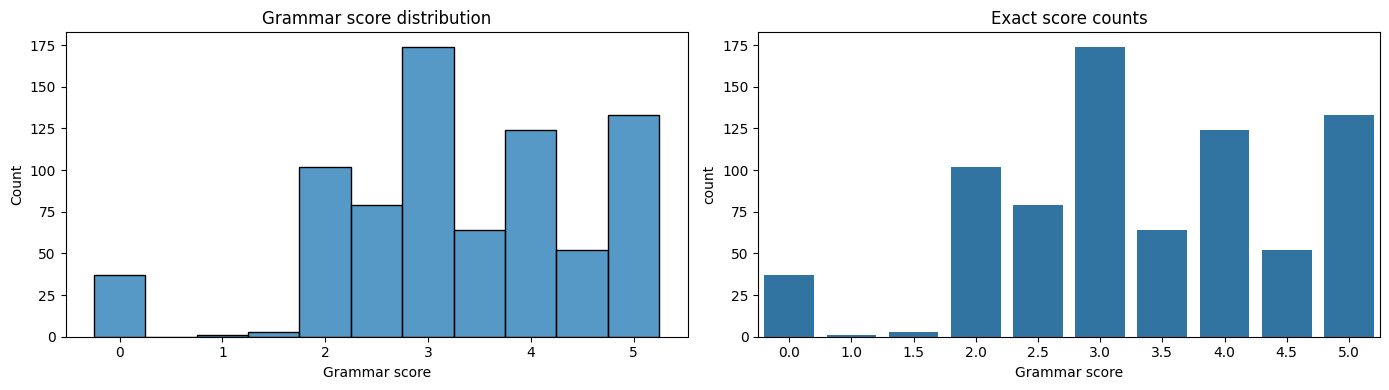

Zero-label samples: 37


In [ ]:
# ============================================================
# 4. TARGET EDA
# ============================================================
print(train_df["label"].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(train_df["label"], bins=np.arange(-0.25, 5.26, 0.5), ax=axes[0])
axes[0].set_title("Grammar score distribution")
axes[0].set_xlabel("Grammar score")

sns.countplot(x=train_df["label"], ax=axes[1])
axes[1].set_title("Exact score counts")
axes[1].set_xlabel("Grammar score")

plt.tight_layout()
plt.show()

zero_count = int((train_df["label"] == 0).sum())
print("Zero-label samples:", zero_count)


In [ ]:
# ============================================================
# 5. AUDIO FILE VALIDATION
# ============================================================
def find_audio_file(audio_dir, filename):
    filename = str(filename)
    candidates = [audio_dir / filename, audio_dir / f"{filename}.wav"]
    for p in candidates:
        if p.exists():
            return p
    return None

train_df["audio_path"] = train_df["filename"].apply(lambda x: find_audio_file(TRAIN_AUDIO_DIR, x))
test_df["audio_path"] = test_df["filename"].apply(lambda x: find_audio_file(TEST_AUDIO_DIR, x))

print("Missing train audio:", train_df["audio_path"].isna().sum())
print("Missing test audio :", test_df["audio_path"].isna().sum())
assert train_df["audio_path"].notna().all()
assert test_df["audio_path"].notna().all()


Missing train audio: 0
Missing test audio : 0


## \
\
\
\4. Fixed cross-validation split

We use the same five folds for all supervised experiments. Coarse target bins keep the score distribution approximately balanced across folds.


In [ ]:
# ============================================================
# 6. FIVE-FOLD STRATIFICATION
# ============================================================
from sklearn.model_selection import StratifiedKFold

bins = [-0.01, 1.99, 2.99, 3.99, 4.99, 5.01]
labels = ["0-1.99", "2-2.99", "3-3.99", "4-4.99", "5"]

train_df["stratum"] = pd.cut(
    train_df["label"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
train_df["fold"] = -1

for fold, (_, val_idx) in enumerate(skf.split(train_df, train_df["stratum"])):
    train_df.loc[val_idx, "fold"] = fold

display(pd.crosstab(train_df["fold"], train_df["stratum"]))
print(train_df["fold"].value_counts().sort_index())

folds = train_df["fold"].to_numpy()
y = train_df["label"].to_numpy(dtype=np.float32)


stratum,0-1.99,2-2.99,3-3.99,4-4.99,5
fold,,,,,
0,8,36,48,35,27
1,8,36,48,35,27
2,8,36,48,35,27
3,9,37,47,35,26
4,8,36,47,36,26


fold
0    154
1    154
2    154
3    154
4    153
Name: count, dtype: int64


## 5. Audio-quality / zero-label investigation

The zero block is inspected explicitly rather than silently removing it. The text branch uses all labelled data; the audio branch can be evaluated separately on the normal population.

This is a modelling decision, not test-label leakage.


In [ ]:
# ============================================================
# 7. ZERO-LABEL BLOCK INSPECTION
# ============================================================
zero_df = train_df[train_df["label"] == 0].copy()

print("Zero-label count:", len(zero_df))
if len(zero_df):
    print("Filename range:", zero_df["filename"].iloc[0], "->", zero_df["filename"].iloc[-1])
    display(zero_df[["filename", "label"]].head(10))

normal_df = train_df[train_df["label"] > 0].copy().reset_index(drop=True)
print("Normal/non-zero population:", len(normal_df))


Zero-label count: 37
Filename range: audio_5055.wav -> audio_5044.wav


,filename,label
17,audio_5055.wav,0.0
30,audio_5066.wav,0.0
41,audio_5069.wav,0.0
49,audio_5073.wav,0.0
51,audio_5039.wav,0.0
73,audio_5056.wav,0.0
96,audio_5062.wav,0.0
111,audio_5037.wav,0.0
122,audio_5054.wav,0.0
133,audio_5057.wav,0.0


Normal/non-zero population: 732


In [ ]:
# ============================================================
# AUDIO PATHS
# ============================================================

def find_audio_file(audio_dir, filename):
    filename = str(filename)

    candidates = [
        audio_dir / filename,
        audio_dir / f"{filename}.wav"
    ]

    for path in candidates:
        if path.exists():
            return path

    return None


train_df["audio_path"] = train_df["filename"].apply(
    lambda x: find_audio_file(TRAIN_AUDIO_DIR, x)
)

test_df["audio_path"] = test_df["filename"].apply(
    lambda x: find_audio_file(TEST_AUDIO_DIR, x)
)


# Validate paths
missing_train = train_df["audio_path"].isna().sum()
missing_test = test_df["audio_path"].isna().sum()

print(f"Training audio found : {len(train_df) - missing_train:,}/{len(train_df):,}")
print(f"Test audio found     : {len(test_df) - missing_test:,}/{len(test_df):,}")

assert missing_train == 0, "Some training audio files could not be found."
assert missing_test == 0, "Some test audio files could not be found."

Training audio found : 769/769
Test audio found     : 216/216


## 6. Transcript generation — canonical Whisper

In [ ]:
!pip uninstall -y av
!pip install -q av==15.1.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 56.6 MB/s eta 0:00:00:00:0100:01


In [ ]:
# Install required packages
!pip install -q faster-whisper

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 16.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 54.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 77.5 MB/s eta 0:00:00:00:0100:01


In [ ]:
# ============================================================
# WHISPER MODEL SETUP
# ============================================================

from faster_whisper import WhisperModel

WHISPER_MODEL = "large-v3"

whisper_model = WhisperModel(
    WHISPER_MODEL,
    device="cuda",
    compute_type="float16"
)

print("Whisper large-v3 loaded successfully.")

Whisper large-v3 loaded successfully.


In [ ]:
from tqdm.auto import tqdm
import pandas as pd
from pathlib import Path


def transcribe_canonical_dataset(df, output_file):

    output_file = Path(output_file)

    # --------------------------------------------------------
    # Resume from existing results
    # --------------------------------------------------------
    if output_file.exists():
        results = pd.read_csv(output_file)

        done = set(
            results["filename"].astype(str)
        )

        print(f"Resuming: {len(done):,} files already completed")

    else:
        results = pd.DataFrame(
            columns=["filename", "transcript"]
        )

        done = set()


    # --------------------------------------------------------
    # Transcribe
    # --------------------------------------------------------
    for _, row in tqdm(
        df.iterrows(),
        total=len(df),
        desc="Canonical Whisper",
        unit="file"
    ):

        filename = str(row["filename"])

        if filename in done:
            continue

        audio_path = row["audio_path"]

        try:

            segments, info = whisper_model.transcribe(
                str(audio_path),
                language="en",
                task="transcribe",
                beam_size=5,
                temperature=0,
                condition_on_previous_text=False,
                vad_filter=False
            )

            transcript = " ".join(
                segment.text.strip()
                for segment in segments
            ).strip()

        except Exception as e:

            print(f"\nError: {filename} -> {e}")
            transcript = ""


        results.loc[len(results)] = [
            filename,
            transcript
        ]


        # ----------------------------------------------------
        # Checkpoint every 10 files
        # ----------------------------------------------------
        if len(results) % 10 == 0:
            results.to_csv(
                output_file,
                index=False
            )


    # Final save
    results.to_csv(
        output_file,
        index=False
    )

    return results

In [ ]:
canonical_path = TRANSCRIPT_DIR / "canonical.csv"

if canonical_path.exists():
    canonical_path.unlink()

canonical_test_path = TRANSCRIPT_DIR / "canonical_test.csv"

if canonical_test_path.exists():
    canonical_test_path.unlink()

In [ ]:
train_canonical = transcribe_canonical_dataset(
    train_df,
    TRANSCRIPT_DIR / "canonical.csv"
)

test_canonical = transcribe_canonical_dataset(
    test_df,
    TRANSCRIPT_DIR / "canonical_test.csv"
)

Canonical Whisper:   0%|          | 0/769 [00:00<?, ?file/s]

Canonical Whisper:   0%|          | 0/216 [00:00<?, ?file/s]

In [ ]:
def transcribe_verbatim_dataset(df, output_file):

    output_file = Path(output_file)

    if output_file.exists():

        results = pd.read_csv(output_file)

        done = set(
            results["filename"].astype(str)
        )

        print(f"Resuming: {len(done):,} files already completed")

    else:

        results = pd.DataFrame(
            columns=["filename", "transcript"]
        )

        done = set()


    for _, row in tqdm(
        df.iterrows(),
        total=len(df),
        desc="Verbatim Whisper",
        unit="file"
    ):

        filename = str(row["filename"])

        if filename in done:
            continue

        audio_path = row["audio_path"]

        try:

            segments, info = whisper_model.transcribe(
                str(audio_path),
                language="en",
                task="transcribe",
                beam_size=5,
                temperature=0,
                condition_on_previous_text=True,
                vad_filter=False
            )

            transcript = " ".join(
                segment.text.strip()
                for segment in segments
            ).strip()

        except Exception as e:

            print(f"\nError: {filename} -> {e}")
            transcript = ""


        results.loc[len(results)] = [
            filename,
            transcript
        ]


        if len(results) % 10 == 0:
            results.to_csv(
                output_file,
                index=False
            )


    results.to_csv(
        output_file,
        index=False
    )

    return results

In [ ]:
train_verbatim = transcribe_verbatim_dataset(
    train_df,
    TRANSCRIPT_DIR / "verbatim.csv"
)

test_verbatim = transcribe_verbatim_dataset(
    test_df,
    TRANSCRIPT_DIR / "verbatim_test.csv"
)

Verbatim Whisper:   0%|          | 0/769 [00:00<?, ?file/s]

Verbatim Whisper:   0%|          | 0/216 [00:00<?, ?file/s]

In [ ]:
# ============================================================
# DEVICE SETUP
# ============================================================

import torch

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU: Tesla T4


In [ ]:
# ============================================================
# WAV2VEC2 CTC SETUP
# ============================================================

import torch
import librosa

from transformers import AutoProcessor, Wav2Vec2ForCTC

CTC_MODEL = "facebook/wav2vec2-large-960h-lv60-self"

ctc_processor = AutoProcessor.from_pretrained(CTC_MODEL)

ctc_model = Wav2Vec2ForCTC.from_pretrained(
    CTC_MODEL
).to(DEVICE)

ctc_model.eval()

print("Wav2Vec2 CTC model loaded successfully.")

Loading weights:   0%|          | 0/423 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-large-960h-lv60-self
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Wav2Vec2 CTC model loaded successfully.


In [ ]:
def transcribe_ctc_dataset(df, output_file):

    output_file = Path(output_file)

    if output_file.exists():

        results = pd.read_csv(output_file)

        done = set(
            results["filename"].astype(str)
        )

        print(f"Resuming: {len(done):,} files already completed")

    else:

        results = pd.DataFrame(
            columns=["filename", "transcript"]
        )

        done = set()


    for _, row in tqdm(
        df.iterrows(),
        total=len(df),
        desc="Wav2Vec2 CTC",
        unit="file"
    ):

        filename = str(row["filename"])

        if filename in done:
            continue

        audio_path = row["audio_path"]

        try:

            audio, sr = librosa.load(
                audio_path,
                sr=16000,
                mono=True
            )

            inputs = ctc_processor(
                audio,
                sampling_rate=16000,
                return_tensors="pt"
            )

            inputs = {
                k: v.to(DEVICE)
                for k, v in inputs.items()
            }

            with torch.no_grad():

                logits = ctc_model(
                    **inputs
                ).logits

            ids = torch.argmax(
                logits,
                dim=-1
            )

            transcript = ctc_processor.batch_decode(
                ids
            )[0]

            transcript = transcript.lower().strip()

        except Exception as e:

            print(f"\nError: {filename} -> {e}")
            transcript = ""


        results.loc[len(results)] = [
            filename,
            transcript
        ]


        if len(results) % 10 == 0:

            results.to_csv(
                output_file,
                index=False
            )


    results.to_csv(
        output_file,
        index=False
    )

    return results

In [ ]:
train_ctc = transcribe_ctc_dataset(
    train_df,
    TRANSCRIPT_DIR / "ctc.csv"
)

test_ctc = transcribe_ctc_dataset(
    test_df,
    TRANSCRIPT_DIR / "ctc_test.csv"
)

Wav2Vec2 CTC:   0%|          | 0/769 [00:00<?, ?file/s]

Wav2Vec2 CTC:   0%|          | 0/216 [00:00<?, ?file/s]

In [ ]:
# ============================================================
# 8. WHISPER SETUP
# ============================================================
from faster_whisper import WhisperModel

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
COMPUTE_TYPE = "float16" if DEVICE == "cuda" else "int8"

whisper_model = WhisperModel(
    "large-v3",
    device=DEVICE,
    compute_type=COMPUTE_TYPE
)

def transcribe_whisper(path, mode="canonical"):
    if mode == "canonical":
        kwargs = dict(
            language="en",
            task="transcribe",
            beam_size=5,
            temperature=0,
            condition_on_previous_text=False,
            vad_filter=False
        )
    elif mode == "verbatim":
        kwargs = dict(
            language="en",
            task="transcribe",
            beam_size=5,
            temperature=0,
            condition_on_previous_text=True,
            vad_filter=False
        )
    else:
        raise ValueError(mode)

    segments, info = whisper_model.transcribe(str(path), **kwargs)
    text = " ".join(s.text.strip() for s in segments).strip()
    return text


In [ ]:
# ============================================================
# 9. CANONICAL WHISPER TRANSCRIPTS
# ============================================================
from tqdm.auto import tqdm

canonical_path = TRANSCRIPT_DIR / "canonical.csv"
test_canonical_path = TRANSCRIPT_DIR / "canonical_test.csv"


def generate_transcripts(df, output_path, mode="canonical", desc="Transcribing"):
    """
    Generate and cache Whisper transcripts for a dataframe.

    If the transcript file already exists, it is loaded directly.
    Otherwise, each audio file is transcribed and the results are
    saved to disk for future runs.
    """

    if output_path.exists():
        result = pd.read_csv(output_path)
        print(f"Loaded cached transcripts: {output_path.name}")
        return result

    rows = []

    for _, row in tqdm(
        df.iterrows(),
        total=len(df),
        desc=desc,
        unit="file"
    ):
        text = transcribe_whisper(row["audio_path"], mode)

        rows.append({
            "filename": row["filename"],
            "text": text
        })

    result = pd.DataFrame(rows)
    result.to_csv(output_path, index=False)

    print(f"Saved {len(result):,} transcripts → {output_path.name}")

    return result


# Generate training transcripts
canonical_df = generate_transcripts(
    train_df,
    canonical_path,
    mode="canonical",
    desc="Canonical Whisper • Train"
)

# Generate test transcripts
test_canonical_df = generate_transcripts(
    test_df,
    test_canonical_path,
    mode="canonical",
    desc="Canonical Whisper • Test"
)


# ------------------------------------------------------------
# Transcript quality summary
# ------------------------------------------------------------
canonical_df["word_count"] = (
    canonical_df["text"]
    .fillna("")
    .str.split()
    .str.len()
)

print("\nCanonical transcription summary")
print("-" * 45)
print(f"Train samples       : {len(canonical_df):,}")
print(f"Empty transcripts   : {canonical_df['text'].fillna('').eq('').sum():,}")
print(f"Mean words/sample   : {canonical_df['word_count'].mean():.1f}")
print(f"Median words/sample : {canonical_df['word_count'].median():.0f}")

display(
    canonical_df[["filename", "text"]]
    .head(5)
    .style
    .set_properties(**{"text-align": "left"})
)

Canonical Whisper • Train:   0%|          | 0/769 [00:00<?, ?file/s]

## 7. Verbatim Whisper transcripts

In [ ]:
# ============================================================
# 10. VERBATIM WHISPER TRANSCRIPTS
# ============================================================
verbatim_df = generate_transcripts(
    train_df,
    TRANSCRIPT_DIR / "verbatim.csv",
    mode="verbatim",
    desc="Verbatim Whisper • Train"
)

test_verbatim_df = generate_transcripts(
    test_df,
    TRANSCRIPT_DIR / "verbatim_test.csv",
    mode="verbatim",
    desc="Verbatim Whisper • Test"
)


## 8. Literal wav2vec2 CTC transcript

In [ ]:
# ============================================================
# 11. WAV2VEC2 CTC TRANSCRIPTION
# ============================================================
from transformers import AutoProcessor, Wav2Vec2ForCTC
import librosa

CTC_MODEL = "facebook/wav2vec2-large-960h-lv60-self"

ctc_processor = AutoProcessor.from_pretrained(CTC_MODEL)
ctc_model = Wav2Vec2ForCTC.from_pretrained(CTC_MODEL).to(DEVICE)
ctc_model.eval()

def transcribe_ctc(path):
    audio, sr = librosa.load(path, sr=16000, mono=True)
    inputs = ctc_processor(audio, sampling_rate=16000, return_tensors="pt")
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    with torch.no_grad():
        logits = ctc_model(**inputs).logits
    ids = torch.argmax(logits, dim=-1)
    text = ctc_processor.batch_decode(ids)[0]
    return text.lower().strip()


In [ ]:
# ============================================================
# 12. CACHE CTC TRANSCRIPTS
# ============================================================
ctc_path = TRANSCRIPT_DIR / "ctc_train.csv"
ctc_test_path = TRANSCRIPT_DIR / "ctc_test.csv"

if ctc_path.exists():
    ctc_df = pd.read_csv(ctc_path)
else:
    rows = []
    for i, row in train_df.iterrows():
        rows.append({"filename": row["filename"], "text": transcribe_ctc(row["audio_path"])})
        if (i + 1) % 25 == 0:
            print(f"Train CTC: {i+1}/{len(train_df)}")
    ctc_df = pd.DataFrame(rows)
    ctc_df.to_csv(ctc_path, index=False)

if ctc_test_path.exists():
    ctc_test_df = pd.read_csv(ctc_test_path)
else:
    rows = []
    for i, row in test_df.iterrows():
        rows.append({"filename": row["filename"], "text": transcribe_ctc(row["audio_path"])})
        if (i + 1) % 25 == 0:
            print(f"Test CTC: {i+1}/{len(test_df)}")
    ctc_test_df = pd.DataFrame(rows)
    ctc_test_df.to_csv(ctc_test_path, index=False)

display(ctc_df.head())


## 9. Text dataset preparation

In [ ]:
# ============================================================
# 13. ALIGN ALL TEXT VIEWS
# ============================================================

text_df = (
    train_df[["filename", "label", "fold"]]
    .merge(
        train_canonical[["filename", "transcript"]],
        on="filename",
        how="left"
    )
    .rename(columns={"transcript": "canonical"})
    .merge(
        train_verbatim[["filename", "transcript"]],
        on="filename",
        how="left"
    )
    .rename(columns={"transcript": "verbatim"})
    .merge(
        train_ctc[["filename", "transcript"]],
        on="filename",
        how="left"
    )
    .rename(columns={"transcript": "ctc"})
)


text_test_df = (
    test_df[["filename"]]
    .merge(
        test_canonical[["filename", "transcript"]],
        on="filename",
        how="left"
    )
    .rename(columns={"transcript": "canonical"})
    .merge(
        test_verbatim[["filename", "transcript"]],
        on="filename",
        how="left"
    )
    .rename(columns={"transcript": "verbatim"})
    .merge(
        test_ctc[["filename", "transcript"]],
        on="filename",
        how="left"
    )
    .rename(columns={"transcript": "ctc"})
)


# Fill missing transcripts
for c in ["canonical", "verbatim", "ctc"]:
    text_df[c] = text_df[c].fillna("")
    text_test_df[c] = text_test_df[c].fillna("")


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print(f"Training rows : {len(text_df):,}")
print(f"Test rows     : {len(text_test_df):,}")

print("\nMissing transcripts:")
for c in ["canonical", "verbatim", "ctc"]:
    print(
        f"{c:10s} | "
        f"train empty: {(text_df[c].str.strip() == '').sum():,} | "
        f"test empty: {(text_test_df[c].str.strip() == '').sum():,}"
    )


display(
    text_df[
        ["filename", "label", "canonical", "verbatim", "ctc"]
    ].head(3)
)

Training rows : 769
Test rows     : 216

Missing transcripts:
canonical  | train empty: 0 | test empty: 0
verbatim   | train empty: 0 | test empty: 0
ctc        | train empty: 30 | test empty: 0


,filename,label,canonical,verbatim,ctc
0,audio_192.wav,3.0,"The playground is very, very beautiful and fun...","The playground is very, very beautiful and fun...",i the playground is very very beautiful and so...
1,audio_436.wav,3.0,The scene of a school playground. Our playgrou...,The scene of a school playground. Our playgrou...,the scene of a school pa playground our playgr...
2,audio_447.wav,3.5,my favorite place to visit is the beach I love...,my favorite place to visit is the beach I love...,my favorite place to viss it is the beach i lo...


## 10. Text length exploration

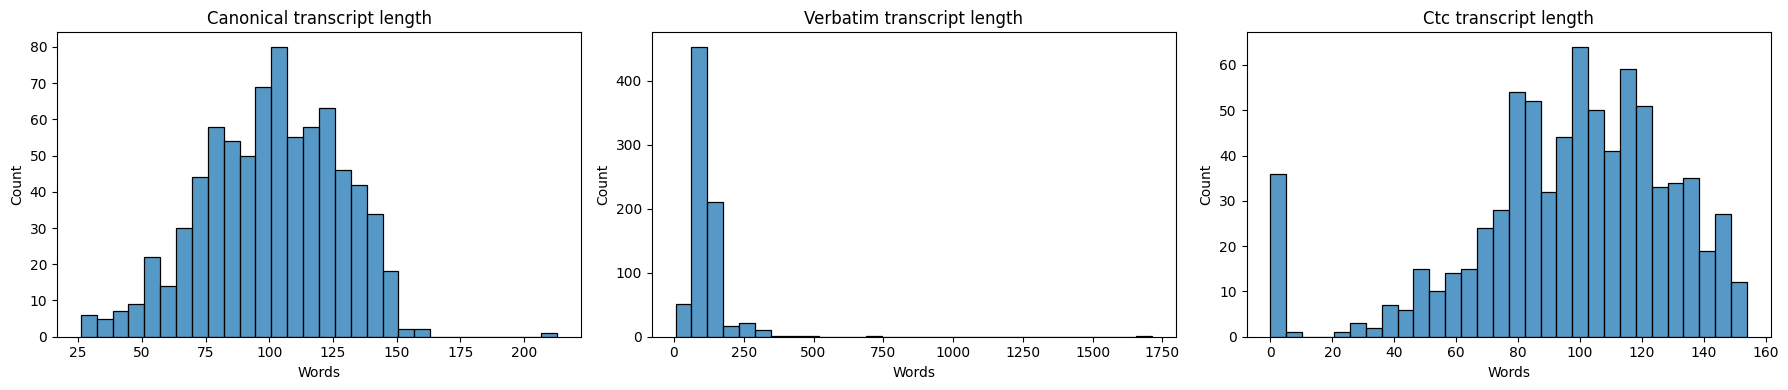

,canonical_words,verbatim_words,ctc_words
count,769.000000,769.000000,769.000000
mean,100.958388,116.413524,96.570871
std,26.729759,78.869606,33.846551
min,26.000000,6.000000,0.000000
25%,82.000000,85.000000,80.000000
50%,102.000000,106.000000,101.000000
75%,121.000000,130.000000,121.000000
max,213.000000,1713.000000,154.000000


In [ ]:
# ============================================================
# 14. TRANSCRIPT EDA
# ============================================================
for c in ["canonical", "verbatim", "ctc"]:
    text_df[c + "_words"] = text_df[c].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, ["canonical", "verbatim", "ctc"]):
    sns.histplot(text_df[c + "_words"], bins=30, ax=ax)
    ax.set_title(f"{c.title()} transcript length")
    ax.set_xlabel("Words")
plt.tight_layout()
plt.show()

display(text_df[["canonical_words", "verbatim_words", "ctc_words"]].describe())


## 11. DeBERTa regression engine

In [ ]:
# ============================================================
# LOAD TEXT DATAFRAMES
# ============================================================

text_df = pd.read_csv(
    TRANSCRIPT_DIR / "canonical.csv"
)

text_test_df = pd.read_csv(
    TRANSCRIPT_DIR / "canonical_test.csv"
)

print("text_df:", text_df.shape)
print("text_test_df:", text_test_df.shape)

print("\nTrain columns:")
print(text_df.columns.tolist())

print("\nTest columns:")
print(text_test_df.columns.tolist())

text_df: (769, 2)
text_test_df: (216, 2)

Train columns:
['filename', 'transcript']

Test columns:
['filename', 'transcript']


In [ ]:
# ============================================================
# REBUILD ALIGNED TEXT DATAFRAMES FROM CACHED TRANSCRIPTS
# ============================================================

# Load cached transcript files
train_canonical = pd.read_csv(
    TRANSCRIPT_DIR / "canonical.csv"
)

test_canonical = pd.read_csv(
    TRANSCRIPT_DIR / "canonical_test.csv"
)

train_verbatim = pd.read_csv(
    TRANSCRIPT_DIR / "verbatim.csv"
)

test_verbatim = pd.read_csv(
    TRANSCRIPT_DIR / "verbatim_test.csv"
)

train_ctc = pd.read_csv(
    TRANSCRIPT_DIR / "ctc.csv"
)

test_ctc = pd.read_csv(
    TRANSCRIPT_DIR / "ctc_test.csv"
)


# ============================================================
# ALIGN ALL TEXT VIEWS
# ============================================================

text_df = (
    train_df[["filename", "label", "fold"]]
    .merge(
        train_canonical[["filename", "transcript"]],
        on="filename",
        how="left"
    )
    .rename(columns={"transcript": "canonical"})
    .merge(
        train_verbatim[["filename", "transcript"]],
        on="filename",
        how="left"
    )
    .rename(columns={"transcript": "verbatim"})
    .merge(
        train_ctc[["filename", "transcript"]],
        on="filename",
        how="left"
    )
    .rename(columns={"transcript": "ctc"})
)


text_test_df = (
    test_df[["filename"]]
    .merge(
        test_canonical[["filename", "transcript"]],
        on="filename",
        how="left"
    )
    .rename(columns={"transcript": "canonical"})
    .merge(
        test_verbatim[["filename", "transcript"]],
        on="filename",
        how="left"
    )
    .rename(columns={"transcript": "verbatim"})
    .merge(
        test_ctc[["filename", "transcript"]],
        on="filename",
        how="left"
    )
    .rename(columns={"transcript": "ctc"})
)


# ============================================================
# FILL MISSING TRANSCRIPTS
# ============================================================

for c in ["canonical", "verbatim", "ctc"]:
    text_df[c] = text_df[c].fillna("")
    text_test_df[c] = text_test_df[c].fillna("")


# ============================================================
# VALIDATION
# ============================================================

print(f"Training rows : {len(text_df):,}")
print(f"Test rows     : {len(text_test_df):,}")

print("\nColumns:")
print(text_df.columns.tolist())

print("\nMissing transcripts:")

for c in ["canonical", "verbatim", "ctc"]:
    print(
        f"{c:10s} | "
        f"train empty: {(text_df[c].str.strip() == '').sum():,} | "
        f"test empty: {(text_test_df[c].str.strip() == '').sum():,}"
    )

display(
    text_df[
        ["filename", "label", "canonical", "verbatim", "ctc"]
    ].head(3)
)

Training rows : 769
Test rows     : 216

Columns:
['filename', 'label', 'fold', 'canonical', 'verbatim', 'ctc']

Missing transcripts:
canonical  | train empty: 0 | test empty: 0
verbatim   | train empty: 0 | test empty: 0
ctc        | train empty: 30 | test empty: 0


,filename,label,canonical,verbatim,ctc
0,audio_192.wav,3.0,"The playground is very, very beautiful and fun...","The playground is very, very beautiful and fun...",i the playground is very very beautiful and so...
1,audio_436.wav,3.0,The scene of a school playground. Our playgrou...,The scene of a school playground. Our playgrou...,the scene of a school pa playground our playgr...
2,audio_447.wav,3.5,my favorite place to visit is the beach I love...,my favorite place to visit is the beach I love...,my favorite place to viss it is the beach i lo...


In [ ]:
# ============================================================
# 15. DEBERTA DATASET / MODEL
# ============================================================
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from torch.optim import AdamW
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

MAX_LENGTH = 320

class GrammarDataset(Dataset):
    def __init__(self, texts, labels=None, tokenizer=None):
        self.texts = list(texts)
        self.labels = None if labels is None else np.asarray(labels, dtype=np.float32)
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )
        item = {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0)
        }
        if self.labels is not None:
            item["labels"] = torch.tensor(self.labels[idx], dtype=torch.float32)
        return item

class DebertaRegressor(torch.nn.Module):
    def __init__(self, model_name):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        hidden = self.encoder.config.hidden_size
        self.dropout = torch.nn.Dropout(0.1)
        self.head = torch.nn.Linear(hidden, 1)

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (out.last_hidden_state * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1.0)
        return self.head(self.dropout(pooled)).squeeze(-1)


In [ ]:
from transformers.utils import logging

logging.set_verbosity_error()

In [ ]:
# ============================================================
# 16. TRAIN / PREDICT ONE DEBERTA FOLD
# ============================================================

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)
from torch.optim import AdamW
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

import copy
import gc
import math


def train_deberta_fold(
    model_name,
    train_texts,
    train_labels,
    val_texts,
    val_labels,
    test_texts,
    seed=42,
    epochs=4,
    batch_size=2,
    lr=2e-5
):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    tokenizer = AutoTokenizer.from_pretrained(model_name)

    train_ds = GrammarDataset(train_texts, train_labels, tokenizer)
    val_ds = GrammarDataset(val_texts, val_labels, tokenizer)
    test_ds = GrammarDataset(test_texts, None, tokenizer)

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=1,
        problem_type="regression",
        torch_dtype=torch.float32
    )

    model = model.float()
    model = model.to(DEVICE)

    optimizer = AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=0.01
    )

    total_steps = len(train_loader) * epochs

    warmup_steps = int(0.1 * total_steps)

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_steps
    )

    best_rmse = float("inf")
    best_state = None

    for epoch in range(epochs):

        model.train()
        train_loss = 0.0

        progress_bar = tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{epochs}",
            leave=False
        )

        for batch in progress_bar:

            input_ids = batch["input_ids"].to(
                DEVICE,
                non_blocking=True
            )

            attention_mask = batch["attention_mask"].to(
                DEVICE,
                non_blocking=True
            )

            labels = batch["labels"].to(
                DEVICE,
                non_blocking=True
            ).float()

            optimizer.zero_grad(set_to_none=True)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()
            scheduler.step()

            train_loss += loss.item()

            progress_bar.set_postfix(
                loss=f"{loss.item():.4f}"
            )

        train_loss /= len(train_loader)

        model.eval()

        predictions = []
        actuals = []

        with torch.no_grad():

            for batch in val_loader:

                input_ids = batch["input_ids"].to(
                    DEVICE,
                    non_blocking=True
                )

                attention_mask = batch["attention_mask"].to(
                    DEVICE,
                    non_blocking=True
                )

                labels = batch["labels"].numpy()

                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )

                preds = (
                    outputs.logits
                    .squeeze(-1)
                    .float()
                    .cpu()
                    .numpy()
                )

                predictions.extend(preds)
                actuals.extend(labels)

        predictions = np.asarray(
            predictions,
            dtype=np.float32
        )

        actuals = np.asarray(
            actuals,
            dtype=np.float32
        )

        if not np.isfinite(predictions).all():
            raise ValueError(
                f"DeBERTa produced NaN/Inf predictions "
                f"at epoch {epoch + 1}"
            )

        rmse = np.sqrt(
            np.mean(
                (actuals - predictions) ** 2
            )
        )

        pearson = np.corrcoef(
            actuals,
            predictions
        )[0, 1]

        print(
            f"Epoch {epoch + 1}: "
            f"train_loss={train_loss:.4f} | "
            f"RMSE={rmse:.4f} | "
            f"Pearson={pearson:.4f}"
        )

        if rmse < best_rmse:

            best_rmse = rmse

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

    # ========================================================
    # LOAD BEST MODEL
    # ========================================================

    model.load_state_dict(best_state)
    model.eval()

    def predict(loader):

        preds = []

        with torch.no_grad():

            for batch in loader:

                input_ids = batch["input_ids"].to(
                    DEVICE,
                    non_blocking=True
                )

                attention_mask = batch["attention_mask"].to(
                    DEVICE,
                    non_blocking=True
                )

                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )

                batch_preds = (
                    outputs.logits
                    .squeeze(-1)
                    .float()
                    .cpu()
                    .numpy()
                )

                preds.extend(batch_preds)

        preds = np.asarray(
            preds,
            dtype=np.float32
        )

        if not np.isfinite(preds).all():
            raise ValueError(
                "Final DeBERTa predictions contain NaN/Inf."
            )

        return preds

    val_pred = predict(val_loader)
    test_pred = predict(test_loader)

    # ========================================================
    # CLEANUP
    # ========================================================

    del model
    del tokenizer
    del train_loader
    del val_loader
    del test_loader

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # ========================================================
    # RETURN
    # ========================================================

    return (
        val_pred,
        test_pred,
        best_rmse,
        best_state
    )

## 12. Text experiment plan

We start with the strongest useful groups rather than exploding the number of trainings.

- DeBERTa-base on canonical
- DeBERTa-large on canonical
- DeBERTa-large on verbatim
- DeBERTa-base on verbatim
- seed averaging for the large models
- CTC is retained as a diversity branch

The code below is resumable because each group writes its OOF/test arrays to disk.


In [ ]:
# ============================================================
# 17. TEXT EXPERIMENT CONFIGURATION
# ============================================================


TEXT_GROUPS = [
    ("large_canonical", "canonical", "microsoft/deberta-v3-large", [7]),
    ("large_verbatim",  "verbatim",  "microsoft/deberta-v3-large", [7]),
    ("large_ctc",       "ctc",       "microsoft/deberta-v3-large", [7]),
]

TEXT_EPOCHS = 5
TEXT_BATCH = 2
# TEXT_GRAD_ACCUM = 4


In [ ]:
# ============================================================
# 18. RUN TEXT OOF + TEST PREDICTIONS
# ============================================================

def run_text_group(group_name, text_col, model_name, seeds):

    oof_file = OOF_DIR / f"{group_name}_oof.npy"
    test_file = OOF_DIR / f"{group_name}_test.npy"

    # --------------------------------------------------------
    # Load cached predictions if available
    # --------------------------------------------------------
    if oof_file.exists() and test_file.exists():
        print("Loading cached:", group_name)
        return np.load(oof_file), np.load(test_file)

    group_oof = np.zeros(
        len(train_df),
        dtype=np.float32
    )

    group_test = []

    # ========================================================
    # SEEDS
    # ========================================================

    for seed in seeds:

        seed_oof = np.zeros(
            len(train_df),
            dtype=np.float32
        )

        seed_test_folds = []

        print(
            f"\n===== {group_name} | seed {seed} ====="
        )

        # ====================================================
        # 5 FOLDS
        # ====================================================

        for fold in range(5):

            tr = folds != fold
            va = folds == fold

            # ------------------------------------------------
            # Train DeBERTa
            # ------------------------------------------------
            val_pred, test_pred, best_rmse, best_model_state = train_deberta_fold(
                model_name=model_name,

                train_texts=text_df.loc[
                    tr,
                    text_col
                ].values,

                train_labels=y[tr],

                val_texts=text_df.loc[
                    va,
                    text_col
                ].values,

                val_labels=y[va],

                test_texts=text_test_df[
                    text_col
                ].values,

                seed=seed,

                epochs=TEXT_EPOCHS,

                batch_size=TEXT_BATCH,

                lr=(
                    1e-5
                    if "large" in model_name
                    else 2e-5
                )
            )

            # ------------------------------------------------
            # Save best model for this fold
            # ------------------------------------------------

            model_save_dir = (
                MODEL_DIR / group_name
            )

            model_save_dir.mkdir(
                parents=True,
                exist_ok=True
            )

            model_path = (
                model_save_dir
                / f"seed{seed}_fold{fold}.pt"
            )

            torch.save(
                best_model_state,
                model_path
            )

            print(
                f"Saved best model → {model_path}"
            )

            # ------------------------------------------------
            # Store validation predictions
            # ------------------------------------------------
            seed_oof[va] = val_pred

            # ------------------------------------------------
            # Store test predictions
            # ------------------------------------------------
            seed_test_folds.append(test_pred)

            # ------------------------------------------------
            # Fold metric
            # ------------------------------------------------
            fold_rmse = np.sqrt(
                mean_squared_error(
                    y[va],
                    val_pred
                )
            )

            print(
                f"Fold {fold}: "
                f"RMSE={fold_rmse:.4f}"
            )

        # ====================================================
        # AVERAGE THIS SEED
        # ====================================================

        group_oof += (
            seed_oof / len(seeds)
        )

        group_test.append(
            np.mean(
                np.vstack(seed_test_folds),
                axis=0
            )
        )

    # ========================================================
    # AVERAGE ALL SEEDS
    # ========================================================

    group_test = np.mean(
        np.vstack(group_test),
        axis=0
    )

    # ========================================================
    # SAVE OOF + TEST
    # ========================================================

    np.save(
        oof_file,
        group_oof
    )

    np.save(
        test_file,
        group_test
    )

    return group_oof, group_test


# ============================================================
# RUN ALL TEXT GROUPS
# ============================================================

text_results = {}

for group_name, text_col, model_name, seeds in TEXT_GROUPS:

    oof_pred, test_pred = run_text_group(
        group_name,
        text_col,
        model_name,
        seeds
    )

    text_results[group_name] = (
        oof_pred,
        test_pred
    )

    print(
        group_name,
        "RMSE =",
        np.sqrt(
            mean_squared_error(
                y,
                oof_pred
            )
        ),
        "Pearson =",
        pearsonr(
            y,
            oof_pred
        )[0]
    )


===== large_canonical | seed 7 =====


config.json:   0%|          | 0.00/580 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

...

Epoch 4/5:   0%|          | 0/308 [00:00<?, ?it/s]

Epoch 4: train_loss=0.1410 | RMSE=0.6606 | Pearson=0.8766


Epoch 5/5:   0%|          | 0/308 [00:00<?, ?it/s]

Epoch 5: train_loss=0.0858 | RMSE=0.6604 | Pearson=0.8790


RuntimeError: [enforce fail at inline_container.cc:672] . unexpected pos 54144 vs 54038

In [ ]:
# ============================================================
# TRAIN LARGE CTC FROM FOLD 0 — ALL 5 FOLDS
# ============================================================

import gc
import numpy as np
import torch

GROUP_NAME = "large_ctc"
TEXT_COL = "ctc"
MODEL_NAME = "microsoft/deberta-v3-large"
SEED = 7

MODEL_SAVE_DIR = MODEL_DIR / GROUP_NAME
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

OOF_DIR.mkdir(parents=True, exist_ok=True)

group_oof = np.zeros(len(train_df), dtype=np.float32)
test_fold_predictions = []

# ============================================================
# TRAIN ALL 5 FOLDS
# ============================================================

for fold in range(5):

    print(
        f"\n{'=' * 60}\n"
        f"TRAINING {GROUP_NAME} | SEED {SEED} | FOLD {fold}\n"
        f"{'=' * 60}"
    )

    tr = folds != fold
    va = folds == fold

    # --------------------------------------------------------
    # Train fold
    # --------------------------------------------------------

    val_pred, test_pred, best_rmse, best_model_state = (
        train_deberta_fold(
            model_name=MODEL_NAME,

            train_texts=text_df.loc[
                tr, TEXT_COL
            ].values,

            train_labels=y[tr],

            val_texts=text_df.loc[
                va, TEXT_COL
            ].values,

            val_labels=y[va],

            test_texts=text_test_df[
                TEXT_COL
            ].values,

            seed=SEED,
            epochs=TEXT_EPOCHS,
            batch_size=TEXT_BATCH,
            lr=1e-5
        )
    )

    # --------------------------------------------------------
    # Save checkpoint safely
    # --------------------------------------------------------

    final_path = (
        MODEL_SAVE_DIR / f"seed{SEED}_fold{fold}.pt"
    )

    temp_path = (
        MODEL_SAVE_DIR / f"seed{SEED}_fold{fold}.tmp.pt"
    )

    temp_path.unlink(missing_ok=True)

    try:
        torch.save(
            best_model_state,
            temp_path
        )

        # Verify the temporary checkpoint can be loaded
        check_state = torch.load(
            temp_path,
            map_location="cpu",
            weights_only=True
        )

        if not check_state:
            raise RuntimeError("Checkpoint is empty.")

        del check_state

        # Replace existing checkpoint only after verification
        temp_path.replace(final_path)

        print(f"Saved and verified: {final_path}")

    except Exception:
        temp_path.unlink(missing_ok=True)
        raise

    # --------------------------------------------------------
    # Store OOF and test predictions
    # --------------------------------------------------------

    group_oof[va] = val_pred
    test_fold_predictions.append(test_pred)

    fold_rmse = np.sqrt(
        mean_squared_error(
            y[va],
            val_pred
        )
    )

    print(f"Fold {fold} RMSE: {fold_rmse:.4f}")
    print(f"Best epoch RMSE: {best_rmse:.4f}")

    # Save progress after every completed fold
    np.save(
        OOF_DIR / "large_ctc_oof_progress.npy",
        group_oof
    )

    np.save(
        OOF_DIR / "large_ctc_test_folds_progress.npy",
        np.vstack(test_fold_predictions)
    )

    del best_model_state
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# FINAL OOF / TEST PREDICTIONS
# ============================================================

group_test = np.mean(
    np.vstack(test_fold_predictions),
    axis=0
).astype(np.float32)

oof_file = OOF_DIR / "large_ctc_oof.npy"
test_file = OOF_DIR / "large_ctc_test.npy"

np.save(oof_file, group_oof)
np.save(test_file, group_test)

print("\n" + "=" * 60)
print("LARGE CTC — ALL FOLDS COMPLETE")
print("=" * 60)

print(
    "OOF RMSE:",
    np.sqrt(mean_squared_error(y, group_oof))
)

print(
    "OOF Pearson:",
    pearsonr(y, group_oof)[0]
)

print("OOF shape:", group_oof.shape)
print("Test shape:", group_test.shape)
print("Models directory:", MODEL_SAVE_DIR)


TRAINING large_ctc | SEED 7 | FOLD 0


config.json:   0%|          | 0.00/580 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

...

Epoch 4/5:   0%|          | 0/308 [00:00<?, ?it/s]

Epoch 4: train_loss=0.1410 | RMSE=0.6606 | Pearson=0.8766


Epoch 5/5:   0%|          | 0/308 [00:00<?, ?it/s]

Epoch 5: train_loss=0.0858 | RMSE=0.6604 | Pearson=0.8790


RuntimeError: [enforce fail at inline_container.cc:672] . unexpected pos 54144 vs 54038

In [ ]:

# ============================================================
# CONTINUE LARGE_CTC: PRESERVE VALID CHECKPOINTS, TRAIN MISSING
# ============================================================

import gc
import numpy as np
import torch
from pathlib import Path

GROUP_NAME = "large_ctc"
TEXT_COL = "ctc"
MODEL_NAME = "microsoft/deberta-v3-large"
SEED_VALUE = 7
N_FOLDS = 5

# Read existing checkpoints directly from the previous attempt.
PREVIOUS_CTC_DIR = (
    PREVIOUS_DIR / "shl_grammar_v2" / "models" / GROUP_NAME
)

# Save only new checkpoints and predictions in working storage.
CURRENT_CTC_DIR = MODEL_DIR / GROUP_NAME
CURRENT_CTC_DIR.mkdir(parents=True, exist_ok=True)

# Keep predictions in working storage.
OOF_PATH = OOF_DIR / "large_ctc_oof.npy"
TEST_PATH = OOF_DIR / "large_ctc_test.npy"

# Verify required data.
assert TEXT_COL in text_df.columns, f"Missing column: {TEXT_COL}"
assert TEXT_COL in text_test_df.columns, f"Missing column: {TEXT_COL}"
assert "fold" in text_df.columns, "text_df must contain fold assignments"

# Initialize prediction arrays.
n_train = len(text_df)
n_test = len(text_test_df)

if OOF_PATH.exists():
    oof_preds = np.load(OOF_PATH)
    if len(oof_preds) != n_train:
        raise ValueError("Existing CTC OOF array has the wrong length.")
else:
    oof_preds = np.full(n_train, np.nan, dtype=np.float32)

if TEST_PATH.exists():
    test_preds = np.load(TEST_PATH)
    if len(test_preds) != n_test:
        raise ValueError("Existing CTC test array has the wrong length.")
else:
    test_preds = np.full(n_test, np.nan, dtype=np.float32)


def checkpoint_is_valid(path):
    """Validate a checkpoint without loading it onto the GPU."""
    if not path.exists() or path.stat().st_size == 0:
        return False

    try:
        obj = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )
        valid = isinstance(obj, dict) and len(obj) > 0
        del obj
        return valid
    except Exception as exc:
        print(f"Invalid checkpoint {path.name}: {exc}")
        return False


# Prefer a valid checkpoint in the current working directory,
# then fall back to the read-only previous attempt.
def find_checkpoint(fold):
    filename = f"seed{SEED_VALUE}_fold{fold}.pt"

    candidates = [
        CURRENT_CTC_DIR / filename,
        PREVIOUS_CTC_DIR / filename
    ]

    for path in candidates:
        if checkpoint_is_valid(path):
            return path

    return None


print("=" * 70)
print("LARGE_CTC FOLD STATUS")
print("=" * 70)

for fold in range(N_FOLDS):
    existing = find_checkpoint(fold)
    print(
        f"Fold {fold}: "
        + (f"VALID checkpoint at {existing}" if existing else "needs training")
    )


# Train only folds whose valid checkpoint is unavailable.
for fold in range(N_FOLDS):

    existing_path = find_checkpoint(fold)

    if existing_path is not None:
        print(f"\nSkipping training for Fold {fold}; valid checkpoint exists.")

        # If this fold's predictions are already saved, preserve them.
        # If not, predictions must be regenerated using the saved model
        # and the inference logic appropriate to your notebook.
        continue

    print("\n" + "=" * 70)
    print(f"TRAINING LARGE_CTC | SEED {SEED_VALUE} | FOLD {fold}")
    print("=" * 70)

    train_idx = np.where(
        text_df["fold"].to_numpy() != fold
    )[0]

    val_idx = np.where(
        text_df["fold"].to_numpy() == fold
    )[0]

    val_pred, test_pred, best_rmse, best_state = train_deberta_fold(
        model_name=MODEL_NAME,
        train_texts=text_df.iloc[train_idx][TEXT_COL].fillna("").tolist(),
        train_labels=text_df.iloc[train_idx]["label"].to_numpy(),
        val_texts=text_df.iloc[val_idx][TEXT_COL].fillna("").tolist(),
        val_labels=text_df.iloc[val_idx]["label"].to_numpy(),
        test_texts=text_test_df[TEXT_COL].fillna("").tolist(),
        seed=SEED_VALUE,
        epochs=TEXT_EPOCHS,
        batch_size=TEXT_BATCH,
        lr=1e-5
    )

    # Save atomically: don't leave a partially written final checkpoint.
    final_path = CURRENT_CTC_DIR / f"seed{SEED_VALUE}_fold{fold}.pt"
    temp_path = CURRENT_CTC_DIR / f"seed{SEED_VALUE}_fold{fold}.tmp.pt"

    try:
        torch.save(best_state, temp_path)

        # Verify the temporary file before promoting it.
        if not checkpoint_is_valid(temp_path):
            raise RuntimeError("Temporary checkpoint failed validation.")

        temp_path.replace(final_path)

    finally:
        if temp_path.exists():
            temp_path.unlink()

    # Save fold predictions and progress after checkpoint succeeds.
    oof_preds[val_idx] = np.asarray(val_pred, dtype=np.float32).reshape(-1)
    test_preds = (
        test_preds * 0 + np.asarray(test_pred, dtype=np.float32).reshape(-1)
        if not np.isnan(test_preds).all()
        else np.asarray(test_pred, dtype=np.float32).reshape(-1)
    )

    np.save(OOF_PATH, oof_preds)
    np.save(TEST_PATH, test_preds)

    print(f"Fold {fold} best RMSE: {best_rmse:.5f}")
    print(f"Saved checkpoint: {final_path}")

    del best_state, val_pred, test_pred
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nCTC continuation cell finished.")
print("Checkpoints:", CURRENT_CTC_DIR)
print("OOF predictions:", OOF_PATH)
print("Test predictions:", TEST_PATH)


LARGE_CTC FOLD STATUS
Fold 0: VALID checkpoint at /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/models/large_ctc/seed7_fold0.pt
Fold 1: VALID checkpoint at /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/models/large_ctc/seed7_fold1.pt
Fold 2: needs training
Fold 3: needs training
Fold 4: needs training

Skipping training for Fold 0; valid checkpoint exists.

Skipping training for Fold 1; valid checkpoint exists.

TRAINING LARGE_CTC | SEED 7 | FOLD 2


config.json:   0%|          | 0.00/580 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

...

Epoch 3: train_loss=0.3396 | RMSE=0.5387 | Pearson=0.9023


Epoch 4/5:   0%|          | 0/308 [00:00<?, ?it/s]

Epoch 4: train_loss=0.1478 | RMSE=0.5267 | Pearson=0.9070


Epoch 5/5:   0%|          | 0/308 [00:00<?, ?it/s]

Epoch 5: train_loss=0.0870 | RMSE=0.5435 | Pearson=0.9122
Fold 4 best RMSE: 0.52671
Saved checkpoint: /kaggle/working/shl_grammar_v2/models/large_ctc/seed7_fold4.pt

CTC continuation cell finished.
Checkpoints: /kaggle/working/shl_grammar_v2/models/large_ctc
OOF predictions: /kaggle/working/shl_grammar_v2/oof/large_ctc_oof.npy
Test predictions: /kaggle/working/shl_grammar_v2/oof/large_ctc_test.npy


In [ ]:
import inspect

print("FUNCTION SIGNATURE:")
print(inspect.signature(train_deberta_fold))

print("\nFUNCTION DEFINITION:")
print(inspect.getsource(train_deberta_fold).split(":", 1)[0] + ":")

FUNCTION SIGNATURE:
(model_name, train_texts, train_labels, val_texts, val_labels, test_texts, seed=42, epochs=4, batch_size=2, lr=2e-05)

FUNCTION DEFINITION:
def train_deberta_fold(
    model_name,
    train_texts,
    train_labels,
    val_texts,
    val_labels,
    test_texts,
    seed=42,
    epochs=4,
    batch_size=2,
    lr=2e-5
):


In [ ]:

from pathlib import Path
import numpy as np
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

ctc_oof_path = OOF_DIR / "large_ctc_oof.npy"

print("OOF file exists:", ctc_oof_path.exists())

if ctc_oof_path.exists():
    ctc_oof = np.load(ctc_oof_path)
    print("Shape:", ctc_oof.shape)
    print("NaN predictions:", np.isnan(ctc_oof).sum())
    print("Infinite predictions:", np.isinf(ctc_oof).sum())
else:
    print("CTC OOF predictions have not been saved.")


OOF file exists: True
Shape: (769,)
NaN predictions: 0
Infinite predictions: 0


In [ ]:

if (
    ctc_oof_path.exists()
    and len(ctc_oof) == len(text_df)
    and np.isfinite(ctc_oof).all()
):
    y_true = text_df["label"].to_numpy(dtype=np.float32)

    print("large_ctc OOF RMSE:",
          mean_squared_error(y_true, ctc_oof) ** 0.5)
    print("large_ctc OOF Pearson:",
          pearsonr(y_true, ctc_oof)[0])
else:
    print("OOF predictions are missing or incomplete; do not evaluate yet.")


large_ctc OOF RMSE: 0.5969538332022959
large_ctc OOF Pearson: 0.8834257


large_canonical: shape=(769,), NaNs=0, source=/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof/large_canonical_oof.npy
large_verbatim: shape=(769,), NaNs=0, source=/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof/large_verbatim_oof.npy
large_ctc: shape=(769,), NaNs=0, source=/kaggle/working/shl_grammar_v2/oof/large_ctc_oof.npy


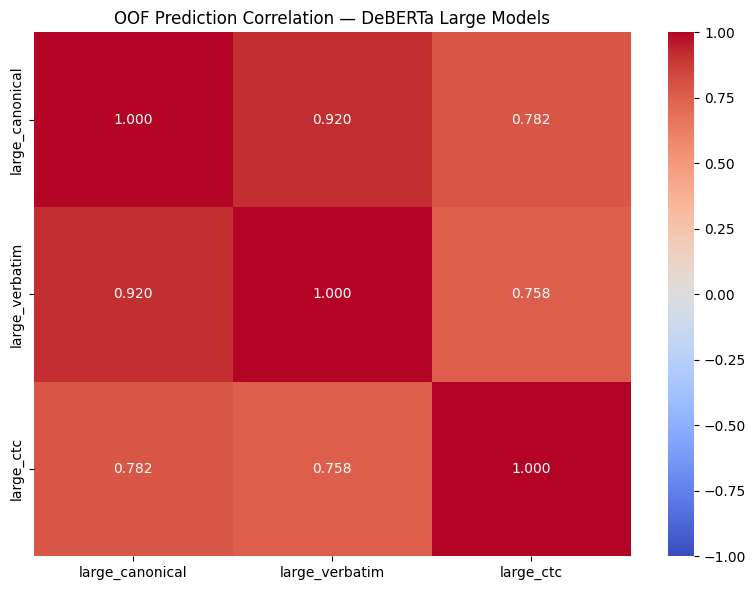

In [ ]:
# ============================================================
# 19. TEXT PREDICTION CORRELATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Search both current working files and previous notebook artifacts
SEARCH_DIRS = [
    OOF_DIR,
    PREVIOUS_DIR / "shl_grammar_v2" / "oof"
]

MODEL_NAMES = [
    "large_canonical",
    "large_verbatim",
    "large_ctc"
]

oof_predictions = {}

for name in MODEL_NAMES:

    filename = f"{name}_oof.npy"

    path = next(
        (
            directory / filename
            for directory in SEARCH_DIRS
            if (directory / filename).exists()
        ),
        None
    )

    if path is None:
        print(f"Missing OOF file: {filename}")
        continue

    preds = np.load(path)

    print(
        f"{name}: shape={preds.shape}, "
        f"NaNs={np.isnan(preds).sum()}, "
        f"source={path}"
    )

    oof_predictions[name] = preds

if len(oof_predictions) != 3:
    raise FileNotFoundError(
        "Could not find all three OOF prediction files. "
        "Check the paths printed above."
    )

# Ensure predictions have matching lengths and valid values
lengths = {len(preds) for preds in oof_predictions.values()}

if len(lengths) != 1:
    raise ValueError("The three OOF arrays have different lengths.")

oof_table = pd.DataFrame(oof_predictions)

if oof_table.isna().any().any():
    raise ValueError(
        "OOF predictions contain NaNs. Complete the missing fold "
        "predictions before calculating correlation."
    )

# Correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    oof_table.corr(),
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("OOF Prediction Correlation — DeBERTa Large Models")
plt.tight_layout()
plt.show()

In [ ]:

import numpy as np

ctc_oof = np.load(OOF_DIR / "large_ctc_oof.npy")
fold_values = text_df["fold"].to_numpy()

print("Total NaNs:", np.isnan(ctc_oof).sum())
print("Total predictions:", np.isfinite(ctc_oof).sum())

for fold in sorted(text_df["fold"].unique()):
    mask = fold_values == fold
    print(
        f"Fold {fold}: "
        f"rows={mask.sum()}, "
        f"NaNs={np.isnan(ctc_oof[mask]).sum()}, "
        f"predictions={np.isfinite(ctc_oof[mask]).sum()}"
    )

print("\nNaNs among empty CTC transcripts:",
      np.isnan(ctc_oof[text_df["ctc"].fillna("").str.strip().eq("")]).sum())

print("NaNs among non-empty CTC transcripts:",
      np.isnan(ctc_oof[text_df["ctc"].fillna("").str.strip().ne("")]).sum())


Total NaNs: 308
Total predictions: 461
Fold 0: rows=154, NaNs=154, predictions=0
Fold 1: rows=154, NaNs=154, predictions=0
Fold 2: rows=154, NaNs=0, predictions=154
Fold 3: rows=154, NaNs=0, predictions=154
Fold 4: rows=153, NaNs=0, predictions=153

NaNs among empty CTC transcripts: 11
NaNs among non-empty CTC transcripts: 297


In [ ]:

from pathlib import Path

CHECKPOINT_DIRS = [
    Path("/kaggle/working/shl_grammar_v2/models/large_ctc"),
    Path("/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/models/large_ctc"),
]

for fold in [0, 1]:
    print(f"\nFold {fold}:")
    for directory in CHECKPOINT_DIRS:
        path = directory / f"seed7_fold{fold}.pt"
        print(f"  {'FOUND' if path.exists() else 'MISSING'}: {path}")



Fold 0:
  MISSING: /kaggle/working/shl_grammar_v2/models/large_ctc/seed7_fold0.pt
  FOUND: /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/models/large_ctc/seed7_fold0.pt

Fold 1:
  MISSING: /kaggle/working/shl_grammar_v2/models/large_ctc/seed7_fold1.pt
  FOUND: /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/models/large_ctc/seed7_fold1.pt


In [ ]:

# ============================================================
# REPAIR CTC OOF USING EXISTING FOLD 0 & 1 CHECKPOINTS
# No retraining. No checkpoint copying.
# ============================================================
import numpy as np
import torch
import gc
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "microsoft/deberta-v3-large"
TEXT_COL = "ctc"
SEED_VALUE = 7

CHECKPOINT_DIR = Path(
    "/kaggle/input/notebooks/vjx021/attempt-2/"
    "shl_grammar_v2/models/large_ctc"
)
OOF_PATH = OOF_DIR / "large_ctc_oof.npy"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Preserve predictions already generated for folds 2, 3, and 4
ctc_oof = np.load(OOF_PATH).copy()
assert len(ctc_oof) == len(text_df)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

for fold in [0, 1]:
    val_idx = np.where(text_df["fold"].to_numpy() == fold)[0]
    missing = np.isnan(ctc_oof[val_idx])

    if not missing.any():
        print(f"Fold {fold}: already complete; skipping.")
        continue

    checkpoint_path = CHECKPOINT_DIR / f"seed{SEED_VALUE}_fold{fold}.pt"
    assert checkpoint_path.exists(), f"Checkpoint missing: {checkpoint_path}"

    print(f"\nLoading fold {fold}: {checkpoint_path}")

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=1,
        problem_type="regression",
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    # Support checkpoints saved either as a state dict or a wrapper dict
    if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    else:
        state_dict = checkpoint

    # Handle a possible DataParallel prefix
    if state_dict and all(k.startswith("module.") for k in state_dict):
        state_dict = {
            k.removeprefix("module."): v
            for k, v in state_dict.items()
        }

    model.load_state_dict(state_dict)
    model.to(device)
    model.eval()

    texts = (
        text_df.iloc[val_idx][TEXT_COL]
        .fillna("")
        .tolist()
    )

    fold_preds = []
    batch_size = 2

    with torch.inference_mode():
        for start in range(0, len(texts), batch_size):
            batch_texts = texts[start:start + batch_size]

            inputs = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=512,
                return_tensors="pt",
            )
            inputs = {k: v.to(device) for k, v in inputs.items()}

            outputs = model(**inputs)
            fold_preds.extend(
                outputs.logits.reshape(-1).float().cpu().numpy().tolist()
            )

    fold_preds = np.asarray(fold_preds)
    assert len(fold_preds) == len(val_idx)

    # Fill only missing entries in this fold
    ctc_oof[val_idx[missing]] = fold_preds[missing]

    print(
        f"Fold {fold}: generated {len(fold_preds)} predictions; "
        f"filled {missing.sum()} missing entries."
    )

    del model, checkpoint, state_dict, fold_preds
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Save the repaired array
np.save(OOF_PATH, ctc_oof)

print("\nFinal NaNs:", np.isnan(ctc_oof).sum())
print("Final shape:", ctc_oof.shape)



Loading fold 0: /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/models/large_ctc/seed7_fold0.pt


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

Fold 0: generated 154 predictions; filled 154 missing entries.

Loading fold 1: /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/models/large_ctc/seed7_fold1.pt


Loading weights:   0%|          | 0/390 [00:00<?, ?it/s]

Fold 1: generated 154 predictions; filled 154 missing entries.

Final NaNs: 0
Final shape: (769,)


## 13. WavLM audio branch

In [ ]:
# ============================================================
# 20. WAVLM EMBEDDINGS
# ============================================================
from transformers import AutoFeatureExtractor, WavLMModel
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

WAVLM_NAME = "microsoft/wavlm-base-plus"

wavlm_processor = AutoFeatureExtractor.from_pretrained(WAVLM_NAME)
wavlm = WavLMModel.from_pretrained(WAVLM_NAME).float().to(DEVICE)
wavlm.eval()

def extract_wavlm_embedding(audio_path):
    audio, sr = librosa.load(audio_path, sr=16000, mono=True)
    inputs = wavlm_processor(audio, sampling_rate=16000, return_tensors="pt")
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    with torch.no_grad():
        hidden = wavlm(**inputs).last_hidden_state
    return hidden.mean(dim=1).squeeze(0).cpu().numpy()


preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

In [ ]:
# ============================================================
# 21. EXTRACT / CACHE NORMAL TRAIN + TEST WAVLM EMBEDDINGS
# ============================================================
import librosa
wavlm_train_path = EMBEDDING_DIR / "wavlm_train_normal.npy"
wavlm_test_path = EMBEDDING_DIR / "wavlm_test.npy"

if wavlm_train_path.exists():
    X_audio = np.load(wavlm_train_path)
else:
    X_audio = np.vstack([
        extract_wavlm_embedding(p) for p in normal_df["audio_path"]
    ]).astype(np.float32)
    np.save(wavlm_train_path, X_audio)

if wavlm_test_path.exists():
    X_test_audio = np.load(wavlm_test_path)
else:
    X_test_audio = np.vstack([
        extract_wavlm_embedding(p) for p in test_df["audio_path"]
    ]).astype(np.float32)
    np.save(wavlm_test_path, X_test_audio)

print("Normal train embeddings:", X_audio.shape)
print("Test embeddings:", X_test_audio.shape)


Normal train embeddings: (732, 768)
Test embeddings: (216, 768)


In [ ]:
# ============================================================
# 22. WAVLM RBF-SVR OOF
# ============================================================
normal_folds = normal_df["fold"].to_numpy()
normal_y = normal_df["label"].to_numpy(dtype=np.float32)

audio_oof = np.zeros(len(normal_df), dtype=np.float32)
audio_test_folds = []

for fold in range(5):
    tr = normal_folds != fold
    va = normal_folds == fold

    svr = Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR(
            kernel="rbf",
            C=10.0,
            epsilon=0.1,
            gamma="scale"
        ))
    ])

    svr.fit(X_audio[tr], normal_y[tr])
    audio_oof[va] = svr.predict(X_audio[va])
    audio_test_folds.append(svr.predict(X_test_audio))

audio_test_pred = np.mean(np.vstack(audio_test_folds), axis=0)

print("Audio RMSE:", np.sqrt(mean_squared_error(normal_y, audio_oof)))
print("Audio Pearson:", pearsonr(normal_y, audio_oof)[0])

np.save(OOF_DIR / "wavlm_svr_normal_oof.npy", audio_oof)
np.save(OOF_DIR / "wavlm_svr_test.npy", audio_test_pred)


Audio RMSE: 0.5925329685293895
Audio Pearson: 0.81174445


## 14. Align text and audio OOF predictions

In [ ]:

import numpy as np

y = text_df["label"].to_numpy(dtype=np.float32)
ctc = np.load(OOF_DIR / "large_ctc_oof.npy")
audio = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")

print("text_df labels:", len(y))
print("CTC OOF:", ctc.shape)
print("Audio OOF:", audio.shape)
print("normal_df rows:", len(normal_df))
print("text_df rows:", len(text_df))


text_df labels: 769
CTC OOF: (769,)
Audio OOF: (732,)
normal_df rows: 732
text_df rows: 769


In [ ]:

print("Text rows:", len(text_df))
print("Normal audio rows:", len(normal_df))

print("\nZero-label rows in text_df:",
      (text_df["label"] == 0).sum())

print("\nLabel distribution in text_df:")
print(text_df["label"].value_counts().sort_index().head(10))

print("\nDo both DataFrames have filenames?")
print("text_df:", "filename" in text_df.columns)
print("normal_df:", "filename" in normal_df.columns)

if "filename" in text_df.columns and "filename" in normal_df.columns:
    print("\nText rows absent from normal_df:",
          (~text_df["filename"].isin(normal_df["filename"])).sum())
    print("Audio rows absent from text_df:",
          (~normal_df["filename"].isin(text_df["filename"])).sum())


Text rows: 769
Normal audio rows: 732

Zero-label rows in text_df: 37

Label distribution in text_df:
label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64

Do both DataFrames have filenames?
text_df: True
normal_df: True

Text rows absent from normal_df: 37
Audio rows absent from text_df: 0


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# Load predictions
ctc = np.load(OOF_DIR / "large_ctc_oof.npy")
audio = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")

# Attach CTC predictions to the full text dataframe
ctc_df = text_df[["filename", "label"]].copy()
ctc_df["ctc_pred"] = ctc

# Attach audio predictions to the rows used by the audio model
audio_df = normal_df[["filename", "label"]].copy()
audio_df["audio_pred"] = audio

# Match rows by filename
merged = ctc_df.merge(
    audio_df[["filename", "audio_pred"]],
    on="filename",
    how="inner",
    validate="one_to_one"
)

y = merged["label"].to_numpy(dtype=np.float32)
ctc_aligned = merged["ctc_pred"].to_numpy(dtype=np.float32)
audio_aligned = merged["audio_pred"].to_numpy(dtype=np.float32)

assert len(merged) == len(normal_df)
assert np.isfinite(ctc_aligned).all()
assert np.isfinite(audio_aligned).all()

print("Aligned rows:", len(merged))
print("CTC RMSE:", mean_squared_error(y, ctc_aligned) ** 0.5)
print("Audio RMSE:", mean_squared_error(y, audio_aligned) ** 0.5)

print("\n--- Ensemble results ---")
results = []

for w in np.arange(0, 1.01, 0.1):
    pred = w * ctc_aligned + (1 - w) * audio_aligned
    rmse = mean_squared_error(y, pred) ** 0.5
    corr = pearsonr(y, pred)[0]

    results.append((w, rmse, corr))
    print(
        f"CTC={w:.1f} | Audio={1-w:.1f} | "
        f"RMSE={rmse:.5f} | Pearson={corr:.5f}"
    )

best = min(results, key=lambda x: x[1])
print(f"\nBest RMSE weight: CTC={best[0]:.1f}, Audio={1-best[0]:.1f}")
print(f"Best blend RMSE: {best[1]:.5f}")
print(f"Best blend Pearson: {best[2]:.5f}")


Aligned rows: 732
CTC RMSE: 0.6080706648747466
Audio RMSE: 0.5925329685293895

--- Ensemble results ---
CTC=0.0 | Audio=1.0 | RMSE=0.59253 | Pearson=0.81174
CTC=0.1 | Audio=0.9 | RMSE=0.56954 | Pearson=0.82900
CTC=0.2 | Audio=0.8 | RMSE=0.55138 | Pearson=0.84275
CTC=0.3 | Audio=0.7 | RMSE=0.53852 | Pearson=0.85259
CTC=0.4 | Audio=0.6 | RMSE=0.53136 | Pearson=0.85826
CTC=0.5 | Audio=0.5 | RMSE=0.53013 | Pearson=0.85970
CTC=0.6 | Audio=0.4 | RMSE=0.53486 | Pearson=0.85702
CTC=0.7 | Audio=0.3 | RMSE=0.54541 | Pearson=0.85050
CTC=0.8 | Audio=0.2 | RMSE=0.56144 | Pearson=0.84056
CTC=0.9 | Audio=0.1 | RMSE=0.58250 | Pearson=0.82768
CTC=1.0 | Audio=0.0 | RMSE=0.60807 | Pearson=0.81242

Best RMSE weight: CTC=0.5, Audio=0.5
Best blend RMSE: 0.53013
Best blend Pearson: 0.85970


In [ ]:

# ============================================================
# EXPERIMENT: SEARCH ALL 2/3/4-MODEL BLENDS
# ============================================================
import numpy as np
import pandas as pd
from itertools import product
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error

# ------------------------------------------------------------
# 1. LOAD OOF PREDICTIONS
# ------------------------------------------------------------

oof_paths = {
    "CTC": OOF_DIR / "large_ctc_oof.npy",
    "Canonical": PREVIOUS_OOF_DIR / "large_canonical_oof.npy",
    "Verbatim": PREVIOUS_OOF_DIR / "large_verbatim_oof.npy",
    "Audio": OOF_DIR / "wavlm_svr_normal_oof.npy",
}

for name, path in oof_paths.items():
    print(f"{name}: {path} | Exists: {path.exists()}")

preds = {name: np.load(path) for name, path in oof_paths.items()}


for name, arr in preds.items():
    print(f"{name:10s}: {arr.shape}")

# ------------------------------------------------------------
# 2. ALIGN TEXT PREDICTIONS BY FILENAME
# ------------------------------------------------------------
assert all(len(preds[m]) == len(text_df) for m in
           ["CTC", "Canonical", "Verbatim"]), \
       "A text OOF array does not match text_df."

assert len(preds["Audio"]) == len(normal_df), \
       "Audio OOF array does not match normal_df."

blend_df = text_df[["filename", "label"]].copy()

for name in ["CTC", "Canonical", "Verbatim"]:
    blend_df[name] = preds[name]

audio_df = normal_df[["filename"]].copy()
audio_df["Audio"] = preds["Audio"]

blend_df = blend_df.merge(
    audio_df, on="filename", how="inner", validate="one_to_one"
)

models = ["CTC", "Canonical", "Verbatim", "Audio"]

y = blend_df["label"].to_numpy(dtype=np.float64)
P = blend_df[models].to_numpy(dtype=np.float64)

assert len(blend_df) == len(normal_df) == 732
assert np.isfinite(P).all()
assert np.isfinite(y).all()

print("\nAligned evaluation rows:", len(y))
print("Models:", models)

# ------------------------------------------------------------
# 3. SEARCH ALL WEIGHT COMBINATIONS
#    Weights are multiples of 0.05 and sum to 1.
# ------------------------------------------------------------
results = []
steps = 20  # 20 * 5% = 100%

for a in range(steps + 1):
    for b in range(steps - a + 1):
        for c in range(steps - a - b + 1):
            d = steps - a - b - c

            units = np.array([a, b, c, d], dtype=np.float64)
            weights = units / steps

            # Skip single-model blends; evaluate actual ensembles
            if np.count_nonzero(units) < 2:
                continue

            pred = P @ weights
            rmse = np.sqrt(mean_squared_error(y, pred))
            corr = pearsonr(y, pred)[0]

            results.append({
                "CTC": weights[0],
                "Canonical": weights[1],
                "Verbatim": weights[2],
                "Audio": weights[3],
                "Num_models": np.count_nonzero(units),
                "RMSE": rmse,
                "Pearson": corr,
            })

results_df = pd.DataFrame(results).sort_values(
    "RMSE", ascending=True
).reset_index(drop=True)

print("\nTotal multi-model blends tested:", len(results_df))
print("\nTOP 20 BLENDS BY RMSE:")
display(results_df.head(20).round(5))

print("\nBEST BLEND:")
display(results_df.head(1).round(5))

# ------------------------------------------------------------
# 4. BEST BLEND FOR EACH MODEL COUNT
# ------------------------------------------------------------
print("\nBEST BY NUMBER OF MODELS:")
display(
    results_df.loc[
        results_df.groupby("Num_models")["RMSE"].idxmin()
    ].sort_values("Num_models").round(5)
)


CTC: /kaggle/working/shl_grammar_v2/oof/large_ctc_oof.npy | Exists: True
Canonical: /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof/large_canonical_oof.npy | Exists: True
Verbatim: /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof/large_verbatim_oof.npy | Exists: True
Audio: /kaggle/working/shl_grammar_v2/oof/wavlm_svr_normal_oof.npy | Exists: True
CTC       : (769,)
Canonical : (769,)
Verbatim  : (769,)
Audio     : (732,)

Aligned evaluation rows: 732
Models: ['CTC', 'Canonical', 'Verbatim', 'Audio']

Total multi-model blends tested: 1767

TOP 20 BLENDS BY RMSE:


,CTC,Canonical,Verbatim,Audio,Num_models,RMSE,Pearson
0,0.25,0.20,0.10,0.45,4,0.51447,0.87018
1,0.20,0.20,0.15,0.45,4,0.51457,0.86983
2,0.25,0.15,0.15,0.45,4,0.51461,0.86995
3,0.20,0.25,0.10,0.45,4,0.51470,0.86985
4,0.25,0.25,0.05,0.45,4,0.51485,0.87002
5,0.20,0.15,0.20,0.45,4,0.51495,0.86941
6,0.25,0.20,0.15,0.40,4,0.51500,0.86963
7,0.25,0.25,0.10,0.40,4,0.51511,0.86966
8,0.20,0.20,0.10,0.50,4,0.51519,0.86955
9,0.30,0.15,0.10,0.45,4,0.51524,0.86978



BEST BLEND:


,CTC,Canonical,Verbatim,Audio,Num_models,RMSE,Pearson
0,0.25,0.2,0.1,0.45,4,0.51447,0.87018



BEST BY NUMBER OF MODELS:


,CTC,Canonical,Verbatim,Audio,Num_models,RMSE,Pearson
436,0.00,0.45,0.0,0.55,2,0.52635,0.86114
27,0.25,0.30,0.0,0.45,3,0.51574,0.86947
0,0.25,0.20,0.1,0.45,4,0.51447,0.87018


In [ ]:

# ============================================================
# BLEND SEARCH: ALL MODEL COMBINATIONS + WEIGHT VARIATIONS
# ============================================================
import numpy as np
import pandas as pd
from itertools import combinations, product
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error

# ------------------------------------------------------------
# 1. LOAD OOF PREDICTIONS FROM THE CORRECT LOCATIONS
# ------------------------------------------------------------
oof_paths = {
    "CTC": OOF_DIR / "large_ctc_oof.npy",
    "Canonical": PREVIOUS_OOF_DIR / "large_canonical_oof.npy",
    "Verbatim": PREVIOUS_OOF_DIR / "large_verbatim_oof.npy",
    "Audio": OOF_DIR / "wavlm_svr_normal_oof.npy",
}

preds = {}
for name, path in oof_paths.items():
    if not path.exists():
        raise FileNotFoundError(f"{name} OOF file not found: {path}")
    preds[name] = np.load(path)
    print(f"{name}: {preds[name].shape} | {path}")

# ------------------------------------------------------------
# 2. ALIGN ALL PREDICTIONS BY FILENAME
# ------------------------------------------------------------
text_models = ["CTC", "Canonical", "Verbatim"]

assert all(len(preds[m]) == len(text_df) for m in text_models), \
    "Text OOF arrays must align with text_df."

assert len(preds["Audio"]) == len(normal_df), \
    "Audio OOF array must align with normal_df."

df = text_df[["filename", "label"]].copy()

for name in text_models:
    df[name] = preds[name]

audio_df = normal_df[["filename"]].copy()
audio_df["Audio"] = preds["Audio"]

df = df.merge(
    audio_df, on="filename", how="inner", validate="one_to_one"
)

models = ["CTC", "Canonical", "Verbatim", "Audio"]
y = df["label"].to_numpy(dtype=np.float64)
P = df[models].to_numpy(dtype=np.float64)

assert len(df) == len(normal_df)
assert np.isfinite(y).all() and np.isfinite(P).all()

print("\nRows evaluated:", len(df))
print("Zero-label rows excluded:", len(text_df) - len(df))

# ------------------------------------------------------------
# 3. INDIVIDUAL MODEL BASELINES
# ------------------------------------------------------------
results = []

for model in models:
    pred = df[model].to_numpy()
    results.append({
        "Combination": model,
        "Models": 1,
        "Weights": model + "=1.00",
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "Pearson": pearsonr(y, pred)[0],
    })

# ------------------------------------------------------------
# 4. ALL PAIRS, TRIPLES, AND FOUR-MODEL BLENDS
#    Weights in increments of 5%, summing to 100%.
# ------------------------------------------------------------
STEP = 20  # 20 steps of 5% each

for n_models in range(2, len(models) + 1):
    for subset in combinations(models, n_models):
        # All nonnegative integer weights summing to STEP
        def compositions(total, parts):
            if parts == 1:
                yield (total,)
            else:
                for first in range(total + 1):
                    for rest in compositions(total - first, parts - 1):
                        yield (first,) + rest

        for units in compositions(STEP, n_models):
            # Require each included model to have positive weight
            if any(w == 0 for w in units):
                continue

            weights = np.array(units, dtype=np.float64) / STEP
            pred = df[list(subset)].to_numpy() @ weights

            rmse = np.sqrt(mean_squared_error(y, pred))
            corr = pearsonr(y, pred)[0]

            weight_text = ", ".join(
                f"{name}={weight:.2f}"
                for name, weight in zip(subset, weights)
            )

            results.append({
                "Combination": " + ".join(subset),
                "Models": n_models,
                "Weights": weight_text,
                "RMSE": rmse,
                "Pearson": corr,
            })

# ------------------------------------------------------------
# 5. SHOW RESULTS
# ------------------------------------------------------------
results_df = pd.DataFrame(results).sort_values(
    "RMSE", ascending=True
).reset_index(drop=True)

print("\nTOP 30 OVERALL:")
display(results_df.head(30).round(5))

print("\nBEST BLEND FOR EACH NUMBER OF MODELS:")
best_by_count = (
    results_df.loc[results_df.groupby("Models")["RMSE"].idxmin()]
    .sort_values("Models")
)
display(best_by_count.round(5))

print("\nBEST PAIR FOR EACH MODEL PAIR:")
pair_results = results_df[results_df["Models"] == 2]
best_by_pair = (
    pair_results.loc[
        pair_results.groupby("Combination")["RMSE"].idxmin()
    ].sort_values("RMSE")
)
display(best_by_pair.round(5))

# Save the experiment results for later analysis
results_path = OOF_DIR / "blend_search_results.csv"
results_df.to_csv(results_path, index=False)
print("\nFull results saved to:", results_path)


CTC: (769,) | /kaggle/working/shl_grammar_v2/oof/large_ctc_oof.npy
Canonical: (769,) | /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof/large_canonical_oof.npy
Verbatim: (769,) | /kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof/large_verbatim_oof.npy
Audio: (732,) | /kaggle/working/shl_grammar_v2/oof/wavlm_svr_normal_oof.npy

Rows evaluated: 732
Zero-label rows excluded: 37

TOP 30 OVERALL:


,Combination,Models,Weights,RMSE,Pearson
0,CTC + Canonical + Verbatim + Audio,4,"CTC=0.25, Canonical=0.20, Verbatim=0.10, Audio...",0.51447,0.87018
1,CTC + Canonical + Verbatim + Audio,4,"CTC=0.20, Canonical=0.20, Verbatim=0.15, Audio...",0.51457,0.86983
2,CTC + Canonical + Verbatim + Audio,4,"CTC=0.25, Canonical=0.15, Verbatim=0.15, Audio...",0.51461,0.86995
3,CTC + Canonical + Verbatim + Audio,4,"CTC=0.20, Canonical=0.25, Verbatim=0.10, Audio...",0.51470,0.86985
4,CTC + Canonical + Verbatim + Audio,4,"CTC=0.25, Canonical=0.25, Verbatim=0.05, Audio...",0.51485,0.87002
5,CTC + Canonical + Verbatim + Audio,4,"CTC=0.20, Canonical=0.15, Verbatim=0.20, Audio...",0.51495,0.86941
6,CTC + Canonical + Verbatim + Audio,4,"CTC=0.25, Canonical=0.20, Verbatim=0.15, Audio...",0.51500,0.86963
7,CTC + Canonical + Verbatim + Audio,4,"CTC=0.25, Canonical=0.25, Verbatim=0.10, Audio...",0.51511,0.86966
8,CTC + Canonical + Verbatim + Audio,4,"CTC=0.20, Canonical=0.20, Verbatim=0.10, Audio...",0.51519,0.86955
9,CTC + Canonical + Verbatim + Audio,4,"CTC=0.30, Canonical=0.15, Verbatim=0.10, Audio...",0.51524,0.86978



BEST BLEND FOR EACH NUMBER OF MODELS:


,Combination,Models,Weights,RMSE,Pearson
1693,Audio,1,Audio=1.00,0.59253,0.81174
436,Canonical + Audio,2,"Canonical=0.45, Audio=0.55",0.52635,0.86114
27,CTC + Canonical + Audio,3,"CTC=0.25, Canonical=0.30, Audio=0.45",0.51574,0.86947
0,CTC + Canonical + Verbatim + Audio,4,"CTC=0.25, Canonical=0.20, Verbatim=0.10, Audio...",0.51447,0.87018



BEST PAIR FOR EACH MODEL PAIR:


,Combination,Models,Weights,RMSE,Pearson
436,Canonical + Audio,2,"Canonical=0.45, Audio=0.55",0.52635,0.86114
536,Verbatim + Audio,2,"Verbatim=0.45, Audio=0.55",0.52930,0.85786
552,CTC + Audio,2,"CTC=0.45, Audio=0.55",0.53000,0.85951
1430,CTC + Canonical,2,"CTC=0.55, Canonical=0.45",0.56980,0.83379
1496,CTC + Verbatim,2,"CTC=0.55, Verbatim=0.45",0.57373,0.83149
1727,Canonical + Verbatim,2,"Canonical=0.55, Verbatim=0.45",0.59937,0.80984



Full results saved to: /kaggle/working/shl_grammar_v2/oof/blend_search_results.csv


In [ ]:

# ============================================================
# GENERATE predictions.csv — 216 TEST ROWS
# ============================================================
import numpy as np
import pandas as pd

WEIGHTS = {
    "CTC": 0.25,
    "Canonical": 0.20,
    "Verbatim": 0.10,
    "Audio": 0.45,
}

test_paths = {
    "CTC": OOF_DIR / "large_ctc_test.npy",
    "Canonical": PREVIOUS_OOF_DIR / "large_canonical_test.npy",
    "Verbatim": PREVIOUS_OOF_DIR / "large_verbatim_test.npy",
    "Audio": OOF_DIR / "wavlm_svr_test.npy",
}

test_preds = {}
for name, path in test_paths.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {name} predictions: {path}")
    test_preds[name] = np.load(path).reshape(-1)
    print(f"{name}: {test_preds[name].shape}")

lengths = {len(p) for p in test_preds.values()}
assert len(lengths) == 1, f"Prediction lengths differ: {lengths}"

predictions = sum(
    WEIGHTS[name] * test_preds[name]
    for name in WEIGHTS
)

# Use test.csv to preserve the exact test row order
test_source = pd.read_csv(TEST_CSV)
assert len(test_source) == len(predictions), (
    f"test.csv has {len(test_source)} rows; "
    f"predictions have {len(predictions)}"
)

# Inspect sample-submission candidates without assuming which one is correct
for p in DATA_DIR.rglob("*.csv"):
    if "sample" in p.name.lower() and "submission" in p.name.lower():
        try:
            sample_check = pd.read_csv(p)
            print(f"Sample candidate: {p} | shape={sample_check.shape}")
        except Exception as e:
            print(f"Could not read {p}: {e}")

# Create a basic predictions file in test.csv row order.
# Confirm the competition's required column names before submission.
filename_col = "filename" if "filename" in test_source.columns else None
if filename_col is None:
    raise ValueError(
        f"Could not find 'filename' in test.csv. "
        f"Columns are: {test_source.columns.tolist()}"
    )

submission = pd.DataFrame({
    "filename": test_source["filename"],
    "label": predictions,
})

SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
submission_path = SUBMISSION_DIR / "predictions.csv"
submission.to_csv(submission_path, index=False)

print("\nSaved:", submission_path)
print("Shape:", submission.shape)
print(submission.head())
print("Missing predictions:", submission["label"].isna().sum())


CTC: (216,)
Canonical: (216,)
Verbatim: (216,)
Audio: (216,)
Sample candidate: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/sample_submission.csv | shape=(204, 2)

Saved: /kaggle/working/shl_grammar_v2/submission/predictions.csv
Shape: (216, 2)
        filename     label
0  audio_128.wav  3.179191
1  audio_156.wav  3.916414
2   audio_19.wav  4.394860
3  audio_108.wav  2.302492
4  audio_206.wav  2.543386
Missing predictions: 0


In [ ]:
# ============================================================
# GENERATE MULTIPLE BLEND SUBMISSIONS
# ============================================================
import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------
OOF_DIR = Path("/kaggle/working/shl_grammar_v2/oof")
PREVIOUS_OOF_DIR = Path(
    "/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof"
)
SUBMISSION_DIR = Path("/kaggle/working/shl_grammar_v2/submission")
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

TEST_CSV = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/"
    "Dataset_Final/test.csv"
)

# ------------------------------------------------------------
# LOAD TEST PREDICTIONS
# ------------------------------------------------------------
test_df = pd.read_csv(TEST_CSV)

ctc = np.load(OOF_DIR / "large_ctc_test.npy")
canonical = np.load(PREVIOUS_OOF_DIR / "large_canonical_test.npy")
verbatim = np.load(PREVIOUS_OOF_DIR / "large_verbatim_test.npy")
audio = np.load(OOF_DIR / "wavlm_svr_test.npy")

assert len(test_df) == len(ctc) == len(canonical) == len(verbatim) == len(audio), \
    "Mismatch between test rows and prediction arrays!"

print("Test rows:", len(test_df))
print("All prediction arrays aligned by length.")

# ------------------------------------------------------------
# DEFINE BLENDS
# Weights are CTC, Canonical, Verbatim, Audio
# ------------------------------------------------------------
blends = {
    # Current best OOF blend — use as baseline
    "baseline_CTC25_Canonical20_Verbatim10_Audio45":
        (0.25, 0.20, 0.10, 0.45),

    # Best three-model blend from your OOF search
    "CTC25_Canonical30_Audio45":
        (0.25, 0.30, 0.00, 0.45),

    # Best two-model blend from your OOF search
    "Canonical45_Audio55":
        (0.00, 0.45, 0.00, 0.55),

    # Nearby four-model alternative
    "CTC20_Canonical20_Verbatim15_Audio45":
        (0.20, 0.20, 0.15, 0.45),

    # Another nearby four-model alternative
    "CTC25_Canonical15_Verbatim15_Audio45":
        (0.25, 0.15, 0.15, 0.45),
}

# ------------------------------------------------------------
# CREATE CSV FILES
# ------------------------------------------------------------
for blend_name, (w_ctc, w_can, w_verb, w_audio) in blends.items():

    predictions = (
        w_ctc * ctc
        + w_can * canonical
        + w_verb * verbatim
        + w_audio * audio
    )

    submission = pd.DataFrame({
        "filename": test_df["filename"],
        "label": predictions,
    })

    output_path = SUBMISSION_DIR / f"predictions_{blend_name}.csv"
    submission.to_csv(output_path, index=False)

    print(f"Saved: {output_path}")
    print(f"  Weights: CTC={w_ctc:.0%}, Canonical={w_can:.0%}, "
          f"Verbatim={w_verb:.0%}, Audio={w_audio:.0%}")
    print(f"  Prediction range: {predictions.min():.4f} to "
          f"{predictions.max():.4f}\n")

print("All blend submissions generated!")

Test rows: 216
All prediction arrays aligned by length.
Saved: /kaggle/working/shl_grammar_v2/submission/predictions_baseline_CTC25_Canonical20_Verbatim10_Audio45.csv
  Weights: CTC=25%, Canonical=20%, Verbatim=10%, Audio=45%
  Prediction range: 1.7648 to 5.1724

Saved: /kaggle/working/shl_grammar_v2/submission/predictions_CTC25_Canonical30_Audio45.csv
  Weights: CTC=25%, Canonical=30%, Verbatim=0%, Audio=45%
  Prediction range: 1.7162 to 5.1521

Saved: /kaggle/working/shl_grammar_v2/submission/predictions_Canonical45_Audio55.csv
  Weights: CTC=0%, Canonical=45%, Verbatim=0%, Audio=55%
  Prediction range: 1.6036 to 5.1602

Saved: /kaggle/working/shl_grammar_v2/submission/predictions_CTC20_Canonical20_Verbatim15_Audio45.csv
  Weights: CTC=20%, Canonical=20%, Verbatim=15%, Audio=45%
  Prediction range: 1.7602 to 5.1807

Saved: /kaggle/working/shl_grammar_v2/submission/predictions_CTC25_Canonical15_Verbatim15_Audio45.csv
  Weights: CTC=25%, Canonical=15%, Verbatim=15%, Audio=45%
  Predict

In [ ]:
# ============================================================
# CROSS-FITTED LINEAR CALIBRATION
# Compare uncalibrated vs cross-fitted calibrated OOF predictions
# Generate calibrated test submission
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------
DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)

OOF_DIR = Path("/kaggle/working/shl_grammar_v2/oof")
PREVIOUS_OOF_DIR = Path(
    "/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof"
)

SUBMISSION_DIR = Path("/kaggle/working/shl_grammar_v2/submission")
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

# ------------------------------------------------------------
# 2. LOAD OOF PREDICTIONS
# ------------------------------------------------------------
ctc_oof = np.load(OOF_DIR / "large_ctc_oof.npy")
canonical_oof = np.load(PREVIOUS_OOF_DIR / "large_canonical_oof.npy")
verbatim_oof = np.load(PREVIOUS_OOF_DIR / "large_verbatim_oof.npy")
audio_oof = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")

# Verify expected lengths
assert len(ctc_oof) == len(train_df)
assert len(canonical_oof) == len(train_df)
assert len(verbatim_oof) == len(train_df)
assert len(audio_oof) == (train_df["label"] != 0).sum()

# ------------------------------------------------------------
# 3. ALIGN AUDIO PREDICTIONS TO TRAINING FILENAMES
# ------------------------------------------------------------
normal_df = train_df.loc[train_df["label"] != 0].copy().reset_index(drop=True)

assert len(normal_df) == len(audio_oof)

audio_map = dict(zip(normal_df["filename"], audio_oof))

train_df["audio_pred"] = train_df["filename"].map(audio_map)

# ------------------------------------------------------------
# 4. BUILD THE BEST THREE-MODEL BLEND
# CTC=25%, Canonical=30%, Audio=45%
# ------------------------------------------------------------
train_df["base_pred"] = (
    0.25 * ctc_oof
    + 0.30 * canonical_oof
    + 0.45 * train_df["audio_pred"].fillna(0)
)

# Zero-label rows are excluded from calibration evaluation,
# matching the earlier 732-row OOF blend comparison.
eval_df = train_df.loc[train_df["label"] != 0].copy()

y = eval_df["label"].to_numpy(dtype=float)
p = eval_df["base_pred"].to_numpy(dtype=float)

assert np.isfinite(y).all()
assert np.isfinite(p).all()

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def show_metrics(name, y_true, pred):
    print(
        f"{name:<30} "
        f"RMSE={rmse(y_true, pred):.6f} | "
        f"Pearson={pearsonr(y_true, pred).statistic:.6f}"
    )

print("Rows evaluated:", len(eval_df))
print("\nOOF performance:")
show_metrics("Original blend", y, p)

# ------------------------------------------------------------
# 5. CROSS-FITTED CALIBRATION
# Each held-out fold is calibrated using only other folds.
# ------------------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_calibrated = np.zeros_like(p)

for fold, (tr_idx, val_idx) in enumerate(kf.split(p), start=1):
    calibrator = LinearRegression()
    calibrator.fit(p[tr_idx].reshape(-1, 1), y[tr_idx])

    oof_calibrated[val_idx] = calibrator.predict(
        p[val_idx].reshape(-1, 1)
    )

    print(
        f"Fold {fold}: "
        f"calibration slope={calibrator.coef_[0]:.5f}, "
        f"intercept={calibrator.intercept_:.5f}"
    )

print("\nCross-fitted comparison:")
show_metrics("Original blend", y, p)
show_metrics("Cross-fitted linear", y, oof_calibrated)

# Save diagnostic predictions
calibration_eval = eval_df[["filename", "label"]].copy()
calibration_eval["base_pred"] = p
calibration_eval["cross_fitted_calibrated_pred"] = oof_calibrated

calibration_eval.to_csv(
    OOF_DIR / "cross_fitted_calibration_diagnostics.csv",
    index=False
)

# ------------------------------------------------------------
# 6. BUILD TEST BLEND
# ------------------------------------------------------------
ctc_test = np.load(OOF_DIR / "large_ctc_test.npy")
canonical_test = np.load(PREVIOUS_OOF_DIR / "large_canonical_test.npy")
audio_test = np.load(OOF_DIR / "wavlm_svr_test.npy")

assert len(test_df) == len(ctc_test) == len(canonical_test) == len(audio_test)

test_pred = (
    0.25 * ctc_test
    + 0.30 * canonical_test
    + 0.45 * audio_test
)

# ------------------------------------------------------------
# 7. FIT FINAL CALIBRATOR ON ALL ELIGIBLE OOF ROWS
# ------------------------------------------------------------
final_calibrator = LinearRegression()
final_calibrator.fit(p.reshape(-1, 1), y)

test_calibrated = final_calibrator.predict(
    test_pred.reshape(-1, 1)
)

print("\nFinal calibration:")
print(f"Slope:     {final_calibrator.coef_[0]:.6f}")
print(f"Intercept: {final_calibrator.intercept_:.6f}")

# ------------------------------------------------------------
# 8. SAVE ORIGINAL AND CALIBRATED SUBMISSIONS
# ------------------------------------------------------------
submissions = {
    "predictions_CTC25_Canonical30_Audio45_uncalibrated.csv": test_pred,
    "predictions_CTC25_Canonical30_Audio45_linear_calibrated.csv":
        test_calibrated,
}

for filename, predictions in submissions.items():
    submission = pd.DataFrame({
        "filename": test_df["filename"],
        "label": predictions,
    })

    output_path = SUBMISSION_DIR / filename
    submission.to_csv(output_path, index=False)

    print(
        f"Saved: {output_path}\n"
        f"  Range: {predictions.min():.4f} to {predictions.max():.4f}"
    )

print("\nDone! Compare the calibrated submission with your current 0.3660 baseline.")

Rows evaluated: 732

OOF performance:
Original blend                 RMSE=0.515737 | Pearson=0.869475
Fold 1: calibration slope=1.14102, intercept=-0.56086
Fold 2: calibration slope=1.14976, intercept=-0.57063
Fold 3: calibration slope=1.14071, intercept=-0.55021
Fold 4: calibration slope=1.15921, intercept=-0.61831
Fold 5: calibration slope=1.12837, intercept=-0.51213

Cross-fitted comparison:
Original blend                 RMSE=0.515737 | Pearson=0.869475
Cross-fitted linear            RMSE=0.501782 | Pearson=0.868900

Final calibration:
Slope:     1.143980
Intercept: -0.562998
Saved: /kaggle/working/shl_grammar_v2/submission/predictions_CTC25_Canonical30_Audio45_uncalibrated.csv
  Range: 1.7162 to 5.1521
Saved: /kaggle/working/shl_grammar_v2/submission/predictions_CTC25_Canonical30_Audio45_linear_calibrated.csv
  Range: 1.4002 to 5.3309

Done! Compare the calibrated submission with your current 0.3660 baseline.


In [ ]:
# ============================================================
# EXPERIMENT 2: CALIBRATION + BLEND COMPARISON
# Methods: Linear, Ridge (multiple alpha values), Isotonic
# Blends: 3-model and 4-model
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------
DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)
OOF_DIR = Path("/kaggle/working/shl_grammar_v2/oof")
PREVIOUS_OOF_DIR = Path(
    "/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof"
)
SUBMISSION_DIR = Path("/kaggle/working/shl_grammar_v2/submission")
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

# ------------------------------------------------------------
# 2. LOAD PREDICTIONS
# ------------------------------------------------------------
ctc_oof = np.load(OOF_DIR / "large_ctc_oof.npy")
canonical_oof = np.load(PREVIOUS_OOF_DIR / "large_canonical_oof.npy")
verbatim_oof = np.load(PREVIOUS_OOF_DIR / "large_verbatim_oof.npy")
audio_oof = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")

ctc_test = np.load(OOF_DIR / "large_ctc_test.npy")
canonical_test = np.load(PREVIOUS_OOF_DIR / "large_canonical_test.npy")
verbatim_test = np.load(PREVIOUS_OOF_DIR / "large_verbatim_test.npy")
audio_test = np.load(OOF_DIR / "wavlm_svr_test.npy")

assert len(ctc_oof) == len(train_df)
assert len(canonical_oof) == len(train_df)
assert len(verbatim_oof) == len(train_df)

normal_df = train_df.loc[train_df["label"] != 0].copy()
assert len(audio_oof) == len(normal_df)

audio_map = dict(zip(normal_df["filename"], audio_oof))
audio_aligned = train_df["filename"].map(audio_map).to_numpy()

# ------------------------------------------------------------
# 3. BUILD TWO BLENDS
# ------------------------------------------------------------
# Your current best OOF blend: 3 models
blend3_oof = (
    0.25 * ctc_oof
    + 0.30 * canonical_oof
    + 0.45 * np.nan_to_num(audio_aligned, nan=0.0)
)

# Original 4-model blend
blend4_oof = (
    0.25 * ctc_oof
    + 0.20 * canonical_oof
    + 0.10 * verbatim_oof
    + 0.45 * np.nan_to_num(audio_aligned, nan=0.0)
)

# Test blends
blend3_test = (
    0.25 * ctc_test
    + 0.30 * canonical_test
    + 0.45 * audio_test
)

blend4_test = (
    0.25 * ctc_test
    + 0.20 * canonical_test
    + 0.10 * verbatim_test
    + 0.45 * audio_test
)

# Evaluate on the same 732 eligible rows as previous experiments
mask = train_df["label"].to_numpy() != 0
y = train_df.loc[mask, "label"].to_numpy(dtype=float)

blend_oof = {
    "3model_CTC25_Canonical30_Audio45": blend3_oof[mask],
    "4model_CTC25_Canonical20_Verbatim10_Audio45": blend4_oof[mask],
}

blend_test = {
    "3model_CTC25_Canonical30_Audio45": blend3_test,
    "4model_CTC25_Canonical20_Verbatim10_Audio45": blend4_test,
}

assert np.isfinite(y).all()
assert all(np.isfinite(p).all() for p in blend_oof.values())
assert all(len(p) == len(test_df) for p in blend_test.values())

# ------------------------------------------------------------
# 4. METRICS
# ------------------------------------------------------------
def metrics(y_true, pred):
    return (
        float(np.sqrt(mean_squared_error(y_true, pred))),
        float(pearsonr(y_true, pred).statistic),
    )

# ------------------------------------------------------------
# 5. CROSS-FITTED CALIBRATION
# ------------------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def crossfit_calibration(pred, y, method, alpha=None):
    """Predict each held-out fold using a calibrator fitted on other folds."""
    calibrated = np.zeros_like(y, dtype=float)

    for tr_idx, val_idx in kf.split(pred):
        x_train = pred[tr_idx].reshape(-1, 1)
        x_val = pred[val_idx].reshape(-1, 1)

        if method == "linear":
            model = LinearRegression()
            model.fit(x_train, y[tr_idx])
            calibrated[val_idx] = model.predict(x_val)

        elif method == "ridge":
            model = Ridge(alpha=alpha)
            model.fit(x_train, y[tr_idx])
            calibrated[val_idx] = model.predict(x_val)

        elif method == "isotonic":
            model = IsotonicRegression(out_of_bounds="clip")
            model.fit(pred[tr_idx], y[tr_idx])
            calibrated[val_idx] = model.predict(pred[val_idx])

    return calibrated

def fit_full_calibrator(pred, y, method, alpha=None):
    """Fit on all eligible OOF predictions for transforming test predictions."""
    if method == "linear":
        model = LinearRegression()
        model.fit(pred.reshape(-1, 1), y)
        return lambda x: model.predict(np.asarray(x).reshape(-1, 1))

    if method == "ridge":
        model = Ridge(alpha=alpha)
        model.fit(pred.reshape(-1, 1), y)
        return lambda x: model.predict(np.asarray(x).reshape(-1, 1))

    if method == "isotonic":
        model = IsotonicRegression(out_of_bounds="clip")
        model.fit(pred, y)
        return lambda x: model.predict(np.asarray(x))

    raise ValueError(method)

# ------------------------------------------------------------
# 6. RUN EXPERIMENTS AND SAVE SUBMISSIONS
# ------------------------------------------------------------
methods = [
    ("linear", None, "Linear"),
    ("ridge", 0.1, "RidgeA0p1"),
    ("ridge", 1.0, "RidgeA1"),
    ("ridge", 10.0, "RidgeA10"),
    ("isotonic", None, "Isotonic"),
]

results = []
test_results = {}

for blend_name, pred_oof in blend_oof.items():
    pred_test = blend_test[blend_name]

    # Uncalibrated baseline
    base_rmse, base_corr = metrics(y, pred_oof)
    results.append({
        "Blend": blend_name,
        "Method": "Uncalibrated",
        "OOF_RMSE": base_rmse,
        "OOF_Pearson": base_corr,
    })

    test_results[f"{blend_name}_Uncalibrated"] = pred_test

    for method, alpha, method_name in methods:
        calibrated_oof = crossfit_calibration(
            pred_oof, y, method, alpha
        )

        oof_rmse, oof_corr = metrics(y, calibrated_oof)

        results.append({
            "Blend": blend_name,
            "Method": method_name,
            "OOF_RMSE": oof_rmse,
            "OOF_Pearson": oof_corr,
        })

        # Fit final mapping on all eligible OOF rows and transform test
        transform = fit_full_calibrator(
            pred_oof, y, method, alpha
        )
        calibrated_test = transform(pred_test)

        test_results[f"{blend_name}_{method_name}"] = calibrated_test

        safe_blend = blend_name.replace(" ", "_")
        filename = (
            f"predictions_{safe_blend}_{method_name}_calibrated.csv"
        )

        pd.DataFrame({
            "filename": test_df["filename"],
            "label": calibrated_test,
        }).to_csv(SUBMISSION_DIR / filename, index=False)

        print(
            f"Saved {filename} | "
            f"OOF RMSE={oof_rmse:.6f} | "
            f"Pearson={oof_corr:.6f}"
        )

    # Save uncalibrated submission as a comparison
    safe_blend = blend_name.replace(" ", "_")
    filename = f"predictions_{safe_blend}_uncalibrated.csv"

    pd.DataFrame({
        "filename": test_df["filename"],
        "label": pred_test,
    }).to_csv(SUBMISSION_DIR / filename, index=False)

# ------------------------------------------------------------
# 7. SHOW RANKED OOF RESULTS
# ------------------------------------------------------------
results_df = pd.DataFrame(results).sort_values("OOF_RMSE")
print("\n===== ALL METHODS, SORTED BY CROSS-FITTED OOF RMSE =====")
display(results_df.reset_index(drop=True))

results_path = OOF_DIR / "calibration_experiment_results.csv"
results_df.to_csv(results_path, index=False)
print("\nResults saved to:", results_path)
print("Submission files saved to:", SUBMISSION_DIR)

Saved predictions_3model_CTC25_Canonical30_Audio45_Linear_calibrated.csv | OOF RMSE=0.501782 | Pearson=0.868900
Saved predictions_3model_CTC25_Canonical30_Audio45_RidgeA0p1_calibrated.csv | OOF RMSE=0.501782 | Pearson=0.868900
Saved predictions_3model_CTC25_Canonical30_Audio45_RidgeA1_calibrated.csv | OOF RMSE=0.501793 | Pearson=0.868897
Saved predictions_3model_CTC25_Canonical30_Audio45_RidgeA10_calibrated.csv | OOF RMSE=0.502438 | Pearson=0.868873
Saved predictions_3model_CTC25_Canonical30_Audio45_Isotonic_calibrated.csv | OOF RMSE=0.509610 | Pearson=0.864657
Saved predictions_4model_CTC25_Canonical20_Verbatim10_Audio45_Linear_calibrated.csv | OOF RMSE=0.500506 | Pearson=0.869616
Saved predictions_4model_CTC25_Canonical20_Verbatim10_Audio45_RidgeA0p1_calibrated.csv | OOF RMSE=0.500507 | Pearson=0.869615
Saved predictions_4model_CTC25_Canonical20_Verbatim10_Audio45_RidgeA1_calibrated.csv | OOF RMSE=0.500518 | Pearson=0.869613
Saved predictions_4model_CTC25_Canonical20_Verbatim10_Audio

,Blend,Method,OOF_RMSE,OOF_Pearson
0,4model_CTC25_Canonical20_Verbatim10_Audio45,Linear,0.500506,0.869616
1,4model_CTC25_Canonical20_Verbatim10_Audio45,RidgeA0p1,0.500507,0.869615
2,4model_CTC25_Canonical20_Verbatim10_Audio45,RidgeA1,0.500518,0.869613
3,4model_CTC25_Canonical20_Verbatim10_Audio45,RidgeA10,0.501163,0.869588
4,3model_CTC25_Canonical30_Audio45,Linear,0.501782,0.868900
5,3model_CTC25_Canonical30_Audio45,RidgeA0p1,0.501782,0.868900
6,3model_CTC25_Canonical30_Audio45,RidgeA1,0.501793,0.868897
7,3model_CTC25_Canonical30_Audio45,RidgeA10,0.502438,0.868873
8,4model_CTC25_Canonical20_Verbatim10_Audio45,Isotonic,0.502951,0.868343
9,3model_CTC25_Canonical30_Audio45,Isotonic,0.509610,0.864657



Results saved to: /kaggle/working/shl_grammar_v2/oof/calibration_experiment_results.csv
Submission files saved to: /kaggle/working/shl_grammar_v2/submission


In [ ]:
# ============================================================
# BLEND WEIGHT SEARCH + CROSS-FITTED LINEAR CALIBRATION
# ============================================================
import numpy as np
import pandas as pd

from pathlib import Path
from itertools import product
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------
DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)
OOF_DIR = Path("/kaggle/working/shl_grammar_v2/oof")
PREV_DIR = Path(
    "/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof"
)
SUB_DIR = Path("/kaggle/working/shl_grammar_v2/submission")
SUB_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

# ------------------------------------------------------------
# LOAD OOF + TEST PREDICTIONS
# ------------------------------------------------------------
ctc_oof = np.load(OOF_DIR / "large_ctc_oof.npy")
canonical_oof = np.load(PREV_DIR / "large_canonical_oof.npy")
verbatim_oof = np.load(PREV_DIR / "large_verbatim_oof.npy")
audio_oof = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")

ctc_test = np.load(OOF_DIR / "large_ctc_test.npy")
canonical_test = np.load(PREV_DIR / "large_canonical_test.npy")
verbatim_test = np.load(PREV_DIR / "large_verbatim_test.npy")
audio_test = np.load(OOF_DIR / "wavlm_svr_test.npy")

# Audio OOF covers only the 732 nonzero-label rows
mask = train_df["label"].to_numpy() != 0
y = train_df.loc[mask, "label"].to_numpy(dtype=float)

assert len(ctc_oof) == len(train_df)
assert len(canonical_oof) == len(train_df)
assert len(verbatim_oof) == len(train_df)
assert len(audio_oof) == mask.sum()
assert len(test_df) == len(ctc_test) == len(canonical_test)
assert len(test_df) == len(verbatim_test) == len(audio_test)

# ------------------------------------------------------------
# ALIGN OOF PREDICTIONS
# ------------------------------------------------------------
audio_aligned = np.full(len(train_df), np.nan)
audio_aligned[mask] = audio_oof

C = ctc_oof[mask]
N = canonical_oof[mask]
V = verbatim_oof[mask]
A = audio_aligned[mask]

assert all(np.isfinite(x).all() for x in [C, N, V, A, y])

# ------------------------------------------------------------
# FIXED CROSS-FITTING FOLDS
# Same folds for every candidate, fair comparison
# ------------------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)
folds = list(kf.split(y))

def rmse(y_true, pred):
    return float(np.sqrt(mean_squared_error(y_true, pred)))

def crossfit_linear_calibration(pred):
    calibrated = np.zeros_like(y, dtype=float)

    for tr_idx, val_idx in folds:
        model = LinearRegression()
        model.fit(pred[tr_idx].reshape(-1, 1), y[tr_idx])
        calibrated[val_idx] = model.predict(
            pred[val_idx].reshape(-1, 1)
        )

    return calibrated

# ------------------------------------------------------------
# SEARCH NEARBY WEIGHTS
# Step size = 5 percentage points.
# Audio receives the remaining weight.
# ------------------------------------------------------------
results = []

for w_ctc, w_can, w_verb in product(
    [0.15, 0.20, 0.25, 0.30, 0.35],
    [0.10, 0.15, 0.20, 0.25, 0.30, 0.35],
    [0.00, 0.05, 0.10, 0.15, 0.20],
):
    w_audio = round(1.0 - w_ctc - w_can - w_verb, 10)

    # Keep meaningful positive weight for the audio model
    if w_audio < 0.25 or w_audio > 0.60:
        continue

    pred = w_ctc*C + w_can*N + w_verb*V + w_audio*A

    calibrated = crossfit_linear_calibration(pred)
    score = rmse(y, calibrated)
    corr = float(pearsonr(y, calibrated).statistic)

    results.append({
        "w_ctc": w_ctc,
        "w_canonical": w_can,
        "w_verbatim": w_verb,
        "w_audio": w_audio,
        "OOF_RMSE_calibrated": score,
        "OOF_Pearson_calibrated": corr,
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("OOF_RMSE_calibrated")
    .reset_index(drop=True)
)

results_path = OOF_DIR / "calibrated_blend_weight_search.csv"
results_df.to_csv(results_path, index=False)

print("Candidates evaluated:", len(results_df))
print("\nTOP 15 CALIBRATED BLENDS:")
display(results_df.head(15))
print("Saved search results:", results_path)

# ------------------------------------------------------------
# CREATE SUBMISSIONS FOR TOP 5 DISTINCT WEIGHT COMBINATIONS
# ------------------------------------------------------------
# Avoid near-duplicate candidates by requiring at least 5%
# difference in one or more weights.
selected = []

for _, row in results_df.iterrows():
    weights = np.array([
        row["w_ctc"],
        row["w_canonical"],
        row["w_verbatim"],
        row["w_audio"],
    ])

    if any(np.max(np.abs(
        weights - np.array([
            r["w_ctc"], r["w_canonical"],
            r["w_verbatim"], r["w_audio"]
        ])
    )) < 0.049 for r in selected):
        continue

    selected.append(row)

    if len(selected) == 5:
        break

for i, row in enumerate(selected, start=1):
    wc = row["w_ctc"]
    wn = row["w_canonical"]
    wv = row["w_verbatim"]
    wa = row["w_audio"]

    # Full training OOF blend, including rows with label 0
    full_audio = np.zeros(len(train_df), dtype=float)
    full_audio[mask] = audio_oof

    full_pred = (
        wc*ctc_oof + wn*canonical_oof
        + wv*verbatim_oof + wa*full_audio
    )

    eligible_pred = (
        wc*C + wn*N + wv*V + wa*A
    )

    # Fit final calibrator on the eligible OOF rows
    final_calibrator = LinearRegression()
    final_calibrator.fit(eligible_pred.reshape(-1, 1), y)

    # Apply identical weights and calibrator to test predictions
    test_blend = (
        wc*ctc_test + wn*canonical_test
        + wv*verbatim_test + wa*audio_test
    )
    test_calibrated = final_calibrator.predict(
        test_blend.reshape(-1, 1)
    )

    name = (
        f"predictions_C{int(wc*100)}"
        f"_N{int(wn*100)}"
        f"_V{int(wv*100)}"
        f"_A{int(wa*100)}_LinearCal.csv"
    )

    pd.DataFrame({
        "filename": test_df["filename"],
        "label": test_calibrated,
    }).to_csv(SUB_DIR / name, index=False)

    print(
        f"{i}. {name}\n"
        f"   OOF RMSE={row['OOF_RMSE_calibrated']:.6f} | "
        f"weights C={wc:.0%}, N={wn:.0%}, "
        f"V={wv:.0%}, A={wa:.0%}"
    )

print("\nSubmission files saved in:", SUB_DIR)

Candidates evaluated: 130

TOP 15 CALIBRATED BLENDS:


,w_ctc,w_canonical,w_verbatim,w_audio,OOF_RMSE_calibrated,OOF_Pearson_calibrated
0,0.25,0.20,0.10,0.45,0.500506,0.869616
1,0.25,0.25,0.05,0.45,0.500795,0.869454
2,0.25,0.15,0.15,0.45,0.500912,0.869388
3,0.20,0.25,0.10,0.45,0.501098,0.869284
4,0.20,0.20,0.15,0.45,0.501143,0.869258
5,0.30,0.20,0.05,0.45,0.501150,0.869254
6,0.30,0.15,0.10,0.45,0.501220,0.869215
7,0.30,0.20,0.10,0.40,0.501316,0.869162
8,0.25,0.25,0.10,0.40,0.501434,0.869096
9,0.25,0.20,0.15,0.40,0.501480,0.869070


Saved search results: /kaggle/working/shl_grammar_v2/oof/calibrated_blend_weight_search.csv
1. predictions_C25_N20_V10_A45_LinearCal.csv
   OOF RMSE=0.500506 | weights C=25%, N=20%, V=10%, A=45%
2. predictions_C25_N25_V5_A45_LinearCal.csv
   OOF RMSE=0.500795 | weights C=25%, N=25%, V=5%, A=45%
3. predictions_C25_N15_V15_A45_LinearCal.csv
   OOF RMSE=0.500912 | weights C=25%, N=15%, V=15%, A=45%
4. predictions_C20_N25_V10_A45_LinearCal.csv
   OOF RMSE=0.501098 | weights C=20%, N=25%, V=10%, A=45%
5. predictions_C20_N20_V15_A45_LinearCal.csv
   OOF RMSE=0.501143 | weights C=20%, N=20%, V=15%, A=45%

Submission files saved in: /kaggle/working/shl_grammar_v2/submission


In [ ]:
# ============================================================
# EXPERIMENT: LINEAR STACKING + RIDGE STACKING
# ============================================================
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.linear_model import LinearRegression, Ridge

DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)
OOF_DIR = Path("/kaggle/working/shl_grammar_v2/oof")
PREV_DIR = Path(
    "/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof"
)
SUB_DIR = Path("/kaggle/working/shl_grammar_v2/submission")
SUB_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

# Load base model predictions
ctc_oof = np.load(OOF_DIR / "large_ctc_oof.npy")
can_oof = np.load(PREV_DIR / "large_canonical_oof.npy")
verb_oof = np.load(PREV_DIR / "large_verbatim_oof.npy")
audio_oof = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")

ctc_test = np.load(OOF_DIR / "large_ctc_test.npy")
can_test = np.load(PREV_DIR / "large_canonical_test.npy")
verb_test = np.load(PREV_DIR / "large_verbatim_test.npy")
audio_test = np.load(OOF_DIR / "wavlm_svr_test.npy")

# Audio OOF predictions cover only nonzero-label rows
mask = train_df["label"].to_numpy() != 0
y = train_df.loc[mask, "label"].to_numpy(dtype=float)

assert len(audio_oof) == mask.sum()
assert len(ctc_oof) == len(train_df)
assert len(test_df) == len(ctc_test) == len(can_test)
assert len(test_df) == len(verb_test) == len(audio_test)

# Four independent prediction features
X = np.column_stack([
    ctc_oof[mask],
    can_oof[mask],
    verb_oof[mask],
    audio_oof,
])

X_test = np.column_stack([
    ctc_test,
    can_test,
    verb_test,
    audio_test,
])

assert np.isfinite(X).all() and np.isfinite(X_test).all()

# ------------------------------------------------------------
# Fit different meta-models
# ------------------------------------------------------------
models = {
    "LinearStack": LinearRegression(),
    "RidgeA1": Ridge(alpha=1.0),
    "RidgeA10": Ridge(alpha=10.0),
    "RidgeA100": Ridge(alpha=100.0),
}

for name, model in models.items():
    model.fit(X, y)
    pred = model.predict(X_test)

    # Save separate submission
    filename = f"predictions_Stacking_{name}.csv"

    pd.DataFrame({
        "filename": test_df["filename"],
        "label": pred,
    }).to_csv(SUB_DIR / filename, index=False)

    print(f"\nSaved: {filename}")
    print("Coefficients [CTC, Canonical, Verbatim, Audio]:",
          np.round(model.coef_, 4))
    print("Intercept:", round(float(model.intercept_), 4))
    print("Test prediction range:",
          round(float(pred.min()), 4),
          "to", round(float(pred.max()), 4))

print("\nAll submissions saved in:", SUB_DIR)


Saved: predictions_Stacking_LinearStack.csv
Coefficients [CTC, Canonical, Verbatim, Audio]: [0.2868 0.2359 0.1112 0.5089]
Intercept: -0.5599
Test prediction range: 1.4542 to 5.3491

Saved: predictions_Stacking_RidgeA1.csv
Coefficients [CTC, Canonical, Verbatim, Audio]: [0.2865 0.2347 0.1135 0.5069]
Intercept: -0.5566
Test prediction range: 1.4565 to 5.3476

Saved: predictions_Stacking_RidgeA10.csv
Coefficients [CTC, Canonical, Verbatim, Audio]: [0.2844 0.2273 0.1311 0.4906]
Intercept: -0.5283
Test prediction range: 1.475 to 5.3347

Saved: predictions_Stacking_RidgeA100.csv
Coefficients [CTC, Canonical, Verbatim, Audio]: [0.2685 0.2178 0.1916 0.3886]
Intercept: -0.2968
Test prediction range: 1.5985 to 5.2209

All submissions saved in: /kaggle/working/shl_grammar_v2/submission


In [ ]:
# ============================================================
# STACKING SUBMISSIONS WITH CLIPPING + OOF EVALUATION
# Output: /kaggle/working/shl_grammar_v2/submission2/
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------
DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)

TRAIN_CSV = DATA_DIR / "train.csv"
TEST_CSV = DATA_DIR / "test.csv"

OOF_DIR = Path("/kaggle/working/shl_grammar_v2/oof")

PREV_DIR = Path(
    "/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof"
)

SUBMISSION_DIR = Path("/kaggle/working/shl_grammar_v2/submission2")
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

# ------------------------------------------------------------
# 3. LOAD OOF AND TEST PREDICTIONS
# ------------------------------------------------------------
ctc_oof = np.load(OOF_DIR / "large_ctc_oof.npy")
ctc_test = np.load(OOF_DIR / "large_ctc_test.npy")

canonical_oof = np.load(PREV_DIR / "large_canonical_oof.npy")
canonical_test = np.load(PREV_DIR / "large_canonical_test.npy")

verbatim_oof = np.load(PREV_DIR / "large_verbatim_oof.npy")
verbatim_test = np.load(PREV_DIR / "large_verbatim_test.npy")

audio_oof = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")
audio_test = np.load(OOF_DIR / "wavlm_svr_test.npy")

# ------------------------------------------------------------
# 4. ALIGN OOF PREDICTIONS
# ------------------------------------------------------------
eligible_mask = train_df["label"].to_numpy() != 0
y = train_df.loc[eligible_mask, "label"].to_numpy()

assert len(y) == len(audio_oof), (
    f"Eligible labels: {len(y)}, audio OOF: {len(audio_oof)}"
)

X_oof = np.column_stack([
    ctc_oof[eligible_mask],
    canonical_oof[eligible_mask],
    verbatim_oof[eligible_mask],
    audio_oof
])

X_test = np.column_stack([
    ctc_test,
    canonical_test,
    verbatim_test,
    audio_test
])

assert X_oof.shape == (len(y), 4)
assert X_test.shape == (len(test_df), 4)

print("\nEligible training rows:", len(y))
print("OOF features:", X_oof.shape)
print("Test features:", X_test.shape)

# ------------------------------------------------------------
# 5. METRICS FUNCTION
# ------------------------------------------------------------
def evaluate_predictions(y_true, predictions):
    rmse = np.sqrt(mean_squared_error(y_true, predictions))

    if np.std(predictions) > 0 and np.std(y_true) > 0:
        pearson = pearsonr(y_true, predictions).statistic
    else:
        pearson = np.nan

    return rmse, pearson

# ------------------------------------------------------------
# 6. STACKING MODELS
# ------------------------------------------------------------
models = {
    "LinearStack": LinearRegression(),
    "RidgeA1": Ridge(alpha=1.0),
    "RidgeA10": Ridge(alpha=10.0),
    "RidgeA100": Ridge(alpha=100.0),
}

results = []

# ------------------------------------------------------------
# 7. TRAIN, EVALUATE, CLIP AND SAVE
# ------------------------------------------------------------
for model_name, model in models.items():

    # Fit stacking model on OOF predictions
    model.fit(X_oof, y)

    # OOF predictions from the fitted meta-model
    oof_raw = model.predict(X_oof)
    oof_clipped = np.clip(oof_raw, 0, 5)

    # Evaluate before and after clipping
    rmse_raw, pearson_raw = evaluate_predictions(y, oof_raw)
    rmse_clipped, pearson_clipped = evaluate_predictions(y, oof_clipped)

    # Generate test predictions
    test_raw = model.predict(X_test)
    test_clipped = np.clip(test_raw, 0, 5)

    # Save submission
    submission = pd.DataFrame({
        "label": test_clipped
    })

    output_path = (
        SUBMISSION_DIR / f"predictions_{model_name}_clipped.csv"
    )
    submission.to_csv(output_path, index=False)

    # Store results
    results.append({
        "Model": model_name,
        "OOF RMSE Before Clip": rmse_raw,
        "OOF RMSE After Clip": rmse_clipped,
        "OOF Pearson Before Clip": pearson_raw,
        "OOF Pearson After Clip": pearson_clipped,
        "Test Min Before Clip": test_raw.min(),
        "Test Max Before Clip": test_raw.max(),
        "Test Min After Clip": test_clipped.min(),
        "Test Max After Clip": test_clipped.max(),
        "Saved File": output_path.name
    })

# ------------------------------------------------------------
# 8. DISPLAY RESULTS
# ------------------------------------------------------------
results_df = pd.DataFrame(results)

print("\n" + "=" * 90)
print("STACKING PERFORMANCE — OOF METRICS")
print("=" * 90)

display(
    results_df[
        [
            "Model",
            "OOF RMSE Before Clip",
            "OOF RMSE After Clip",
            "OOF Pearson Before Clip",
            "OOF Pearson After Clip"
        ]
    ].round(5)
)

print("\n" + "=" * 90)
print("TEST PREDICTION RANGES AND SAVED FILES")
print("=" * 90)

display(
    results_df[
        [
            "Model",
            "Test Min Before Clip",
            "Test Max Before Clip",
            "Test Min After Clip",
            "Test Max After Clip",
            "Saved File"
        ]
    ].round(4)
)

print("\nFiles saved in:", SUBMISSION_DIR)

for file_path in sorted(SUBMISSION_DIR.glob("*.csv")):
    print(f" - {file_path.name}")

Train shape: (769, 2)
Test shape: (216, 2)

Eligible training rows: 732
OOF features: (732, 4)
Test features: (216, 4)

STACKING PERFORMANCE — OOF METRICS


,Model,OOF RMSE Before Clip,OOF RMSE After Clip,OOF Pearson Before Clip,OOF Pearson After Clip
0,LinearStack,0.49949,0.49738,0.87018,0.87156
1,RidgeA1,0.49949,0.49741,0.87018,0.87155
2,RidgeA10,0.49961,0.49777,0.87014,0.87143
3,RidgeA100,0.50495,0.50439,0.86854,0.86925



TEST PREDICTION RANGES AND SAVED FILES


,Model,Test Min Before Clip,Test Max Before Clip,Test Min After Clip,Test Max After Clip,Saved File
0,LinearStack,1.4542,5.3491,1.4542,5.0,predictions_LinearStack_clipped.csv
1,RidgeA1,1.4565,5.3476,1.4565,5.0,predictions_RidgeA1_clipped.csv
2,RidgeA10,1.4750,5.3347,1.4750,5.0,predictions_RidgeA10_clipped.csv
3,RidgeA100,1.5985,5.2209,1.5985,5.0,predictions_RidgeA100_clipped.csv



Files saved in: /kaggle/working/shl_grammar_v2/submission2
 - predictions_LinearStack_clipped.csv
 - predictions_RidgeA100_clipped.csv
 - predictions_RidgeA10_clipped.csv
 - predictions_RidgeA1_clipped.csv


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.linear_model import LinearRegression, Ridge

# Paths
DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)
OOF_DIR = Path("/kaggle/working/shl_grammar_v2/oof")
PREV_DIR = Path("/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof")
SUBMISSION_DIR = Path("/kaggle/working/shl_grammar_v2/submission2")
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

# Load data
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

# Load predictions
ctc_oof = np.load(OOF_DIR / "large_ctc_oof.npy")
ctc_test = np.load(OOF_DIR / "large_ctc_test.npy")

canonical_oof = np.load(PREV_DIR / "large_canonical_oof.npy")
canonical_test = np.load(PREV_DIR / "large_canonical_test.npy")

verbatim_oof = np.load(PREV_DIR / "large_verbatim_oof.npy")
verbatim_test = np.load(PREV_DIR / "large_verbatim_test.npy")

audio_oof = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")
audio_test = np.load(OOF_DIR / "wavlm_svr_test.npy")

# Prepare eligible OOF rows
mask = train_df["label"].to_numpy() != 0
y = train_df.loc[mask, "label"].to_numpy()

X_oof = np.column_stack([
    ctc_oof[mask],
    canonical_oof[mask],
    verbatim_oof[mask],
    audio_oof
])

X_test = np.column_stack([
    ctc_test,
    canonical_test,
    verbatim_test,
    audio_test
])

# Stacking models
models = {
    "LinearStack": LinearRegression(),
    "RidgeA1": Ridge(alpha=1.0),
    "RidgeA10": Ridge(alpha=10.0),
    "RidgeA100": Ridge(alpha=100.0),
}

# Generate submissions with the required filename column
for name, model in models.items():
    model.fit(X_oof, y)

    pred = model.predict(X_test)
    pred = np.clip(pred, 0, 5)

    submission = pd.DataFrame({
        "filename": test_df["filename"].to_numpy(),
        "label": pred
    })

    output_path = SUBMISSION_DIR / f"predictions_{name}_clipped.csv"
    submission.to_csv(output_path, index=False)

    # Validate format
    saved = pd.read_csv(output_path)
    assert list(saved.columns) == ["filename", "label"]
    assert len(saved) == len(test_df)
    assert saved["filename"].equals(test_df["filename"])

    print(f"Saved: {output_path}")
    print("Columns:", saved.columns.tolist())
    print("Rows:", len(saved))
    print("Prediction range:", saved["label"].min(), "to", saved["label"].max())
    print()

print("All submissions recreated and validated.")

Saved: /kaggle/working/shl_grammar_v2/submission2/predictions_LinearStack_clipped.csv
Columns: ['filename', 'label']
Rows: 216
Prediction range: 1.454168336350505 to 5.0

Saved: /kaggle/working/shl_grammar_v2/submission2/predictions_RidgeA1_clipped.csv
Columns: ['filename', 'label']
Rows: 216
Prediction range: 1.4564530879766928 to 5.0

Saved: /kaggle/working/shl_grammar_v2/submission2/predictions_RidgeA10_clipped.csv
Columns: ['filename', 'label']
Rows: 216
Prediction range: 1.4750441226226911 to 5.0

Saved: /kaggle/working/shl_grammar_v2/submission2/predictions_RidgeA100_clipped.csv
Columns: ['filename', 'label']
Rows: 216
Prediction range: 1.5984896991484825 to 5.0

All submissions recreated and validated.


In [ ]:
# ============================================================
# STACKING EXPERIMENTS: MULTIPLE MODELS + 5-FOLD CV
#
# Reports:
#   1. Training RMSE (unclipped and clipped)
#   2. 5-fold CV RMSE (unclipped and clipped)
#   3. Training/CV Pearson correlation
#
# Saves submissions to:
#   /kaggle/working/shl_grammar_v2/submission3/
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ============================================================
# 1. PATHS
# ============================================================

DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)

OOF_DIR = Path("/kaggle/working/shl_grammar_v2/oof")

PREV_DIR = Path(
    "/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof"
)

SUBMISSION_DIR = Path(
    "/kaggle/working/shl_grammar_v2/submission3"
)

SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. LOAD DATA
# ============================================================

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

# ============================================================
# 3. LOAD BASE-MODEL PREDICTIONS
# ============================================================

ctc_oof = np.load(OOF_DIR / "large_ctc_oof.npy")
ctc_test = np.load(OOF_DIR / "large_ctc_test.npy")

canonical_oof = np.load(PREV_DIR / "large_canonical_oof.npy")
canonical_test = np.load(PREV_DIR / "large_canonical_test.npy")

verbatim_oof = np.load(PREV_DIR / "large_verbatim_oof.npy")
verbatim_test = np.load(PREV_DIR / "large_verbatim_test.npy")

audio_oof = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")
audio_test = np.load(OOF_DIR / "wavlm_svr_test.npy")

# ============================================================
# 4. ALIGN TRAINING ROWS
# ============================================================

# Audio OOF predictions exist for nonzero-label rows only.
eligible_mask = train_df["label"].to_numpy() != 0

y = train_df.loc[eligible_mask, "label"].to_numpy()

X_oof = np.column_stack([
    ctc_oof[eligible_mask],
    canonical_oof[eligible_mask],
    verbatim_oof[eligible_mask],
    audio_oof
])

X_test = np.column_stack([
    ctc_test,
    canonical_test,
    verbatim_test,
    audio_test
])

assert X_oof.shape == (len(y), 4)
assert X_test.shape == (len(test_df), 4)

assert np.isfinite(X_oof).all()
assert np.isfinite(X_test).all()
assert np.isfinite(y).all()

print("\nEligible training rows:", len(y))
print("OOF features:", X_oof.shape)
print("Test features:", X_test.shape)

# ============================================================
# 5. METRIC FUNCTIONS
# ============================================================

def calculate_metrics(y_true, pred):
    rmse = np.sqrt(mean_squared_error(y_true, pred))

    if np.std(pred) > 0 and np.std(y_true) > 0:
        corr = pearsonr(y_true, pred).statistic
    else:
        corr = np.nan

    return float(rmse), float(corr)


# ============================================================
# 6. DEFINE CANDIDATE MODELS
# ============================================================

models = {
    "LinearStack": LinearRegression(),

    "RidgeA001": Ridge(alpha=0.01),
    "RidgeA01": Ridge(alpha=0.1),
    "RidgeA05": Ridge(alpha=0.5),
    "RidgeA1": Ridge(alpha=1.0),
    "RidgeA2": Ridge(alpha=2.0),
    "RidgeA5": Ridge(alpha=5.0),
    "RidgeA10": Ridge(alpha=10.0),
    "RidgeA20": Ridge(alpha=20.0),
    "RidgeA50": Ridge(alpha=50.0),
    "RidgeA100": Ridge(alpha=100.0),
}

# Identical folds for every model for a fair comparison.
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

# ============================================================
# 7. TRAIN, CROSS-VALIDATE, AND SAVE
# ============================================================

for model_name, model in models.items():

    print(f"\nRunning: {model_name}")

    # --------------------------------------------------------
    # A. 5-FOLD CROSS-VALIDATION
    # Each row gets a prediction from a meta-model that did
    # not train on that row.
    # --------------------------------------------------------

    cv_pred = np.zeros(len(y), dtype=float)

    for fold, (tr_idx, val_idx) in enumerate(
        kf.split(X_oof), start=1
    ):
        fold_model = type(model)(**model.get_params())

        fold_model.fit(
            X_oof[tr_idx],
            y[tr_idx]
        )

        cv_pred[val_idx] = fold_model.predict(
            X_oof[val_idx]
        )

    cv_pred_clipped = np.clip(cv_pred, 0, 5)

    cv_rmse_raw, cv_corr_raw = calculate_metrics(y, cv_pred)
    cv_rmse_clip, cv_corr_clip = calculate_metrics(
        y, cv_pred_clipped
    )

    # --------------------------------------------------------
    # B. TRAINING METRICS
    # Fit on all OOF rows, then evaluate on those same rows.
    # These are in-sample metrics, not held-out performance.
    # --------------------------------------------------------

    model.fit(X_oof, y)

    train_pred = model.predict(X_oof)
    train_pred_clipped = np.clip(train_pred, 0, 5)

    train_rmse_raw, train_corr_raw = calculate_metrics(
        y, train_pred
    )
    train_rmse_clip, train_corr_clip = calculate_metrics(
        y, train_pred_clipped
    )

    # --------------------------------------------------------
    # C. FIT FULL META-MODEL AND PREDICT TEST
    # --------------------------------------------------------

    test_pred = model.predict(X_test)
    test_pred_clipped = np.clip(test_pred, 0, 5)

    # --------------------------------------------------------
    # D. SAVE SUBMISSION
    # --------------------------------------------------------

    submission = pd.DataFrame({
        "filename": test_df["filename"].to_numpy(),
        "label": test_pred_clipped
    })

    output_path = (
        SUBMISSION_DIR /
        f"predictions_{model_name}_clipped.csv"
    )

    submission.to_csv(output_path, index=False)

    # Validate format
    assert list(submission.columns) == ["filename", "label"]
    assert len(submission) == len(test_df)
    assert submission["filename"].equals(test_df["filename"])
    assert submission["label"].between(0, 5).all()

    # --------------------------------------------------------
    # E. STORE RESULTS
    # --------------------------------------------------------

    results.append({
        "Model": model_name,

        "Train RMSE": train_rmse_raw,
        "Train RMSE Clipped": train_rmse_clip,

        "CV RMSE": cv_rmse_raw,
        "CV RMSE Clipped": cv_rmse_clip,

        "CV Pearson": cv_corr_raw,
        "CV Pearson Clipped": cv_corr_clip,

        "Test Min": test_pred.min(),
        "Test Max": test_pred.max(),

        "Submission": output_path.name
    })

    print(
        f"  Train RMSE: {train_rmse_raw:.5f}"
        f" | Clipped: {train_rmse_clip:.5f}"
    )

    print(
        f"  CV RMSE:    {cv_rmse_raw:.5f}"
        f" | Clipped: {cv_rmse_clip:.5f}"
    )

    print(f"  Saved: {output_path.name}")


# ============================================================
# 8. DISPLAY ALL RESULTS
# ============================================================

results_df = pd.DataFrame(results)

# Sort by clipped CV RMSE, our primary selection metric.
results_df = results_df.sort_values(
    "CV RMSE Clipped"
).reset_index(drop=True)

print("\n" + "=" * 100)
print("ALL MODELS — SORTED BY 5-FOLD CV RMSE AFTER CLIPPING")
print("=" * 100)

display(
    results_df[
        [
            "Model",
            "Train RMSE",
            "Train RMSE Clipped",
            "CV RMSE",
            "CV RMSE Clipped",
            "CV Pearson",
            "CV Pearson Clipped"
        ]
    ].round(5)
)

print("\n" + "=" * 100)
print("SUBMISSION FILES")
print("=" * 100)

display(
    results_df[
        [
            "Model",
            "Test Min",
            "Test Max",
            "Submission"
        ]
    ].round(4)
)

# Save metrics for later reference.
metrics_path = SUBMISSION_DIR / "stacking_cv_results.csv"
results_df.to_csv(metrics_path, index=False)

print("\nAll files saved to:", SUBMISSION_DIR)
print("Metrics saved to:", metrics_path)

print("\nCurrent public leaderboard benchmark: 0.3419")

Train shape: (769, 2)
Test shape: (216, 2)

Eligible training rows: 732
OOF features: (732, 4)
Test features: (216, 4)

Running: LinearStack
  Train RMSE: 0.49949 | Clipped: 0.49738
  CV RMSE:    0.50198 | Clipped: 0.49981
  Saved: predictions_LinearStack_clipped.csv

Running: RidgeA001
  Train RMSE: 0.49949 | Clipped: 0.49738
  CV RMSE:    0.50198 | Clipped: 0.49981
  Saved: predictions_RidgeA001_clipped.csv

Running: RidgeA01
  Train RMSE: 0.49949 | Clipped: 0.49738
  CV RMSE:    0.50197 | Clipped: 0.49981
  Saved: predictions_RidgeA01_clipped.csv

Running: RidgeA05
  Train RMSE: 0.49949 | Clipped: 0.49739
  CV RMSE:    0.50197 | Clipped: 0.49983
  Saved: predictions_RidgeA05_clipped.csv

Running: RidgeA1
  Train RMSE: 0.49949 | Clipped: 0.49741
  CV RMSE:    0.50196 | Clipped: 0.49984
  Saved: predictions_RidgeA1_clipped.csv

Running: RidgeA2
  Train RMSE: 0.49949 | Clipped: 0.49744
  CV RMSE:    0.50195 | Clipped: 0.49987
  Saved: predictions_RidgeA2_clipped.csv

Running: RidgeA5
 

,Model,Train RMSE,Train RMSE Clipped,CV RMSE,CV RMSE Clipped,CV Pearson,CV Pearson Clipped
0,LinearStack,0.49949,0.49738,0.50198,0.49981,0.86879,0.87020
1,RidgeA001,0.49949,0.49738,0.50198,0.49981,0.86879,0.87020
2,RidgeA01,0.49949,0.49738,0.50197,0.49981,0.86879,0.87020
3,RidgeA05,0.49949,0.49739,0.50197,0.49983,0.86880,0.87020
4,RidgeA1,0.49949,0.49741,0.50196,0.49984,0.86880,0.87020
5,RidgeA2,0.49949,0.49744,0.50195,0.49987,0.86880,0.87019
6,RidgeA5,0.49952,0.49755,0.50195,0.49999,0.86881,0.87015
7,RidgeA10,0.49961,0.49777,0.50202,0.50023,0.86879,0.87008
8,RidgeA20,0.49991,0.49830,0.50237,0.50084,0.86868,0.86987
9,RidgeA50,0.50143,0.50034,0.50431,0.50336,0.86809,0.86904



SUBMISSION FILES


,Model,Test Min,Test Max,Submission
0,LinearStack,1.4542,5.3491,predictions_LinearStack_clipped.csv
1,RidgeA001,1.4542,5.3491,predictions_RidgeA001_clipped.csv
2,RidgeA01,1.4544,5.3489,predictions_RidgeA01_clipped.csv
3,RidgeA05,1.4553,5.3484,predictions_RidgeA05_clipped.csv
4,RidgeA1,1.4565,5.3476,predictions_RidgeA1_clipped.csv
5,RidgeA2,1.4587,5.3462,predictions_RidgeA2_clipped.csv
6,RidgeA5,1.4651,5.3419,predictions_RidgeA5_clipped.csv
7,RidgeA10,1.4750,5.3347,predictions_RidgeA10_clipped.csv
8,RidgeA20,1.4929,5.3205,predictions_RidgeA20_clipped.csv
9,RidgeA50,1.5374,5.2803,predictions_RidgeA50_clipped.csv



All files saved to: /kaggle/working/shl_grammar_v2/submission3
Metrics saved to: /kaggle/working/shl_grammar_v2/submission3/stacking_cv_results.csv

Current public leaderboard benchmark: 0.3419


In [ ]:
# ============================================================
# LEARNED BLENDING OF 4 BASE MODELS
# Compare linear and nonlinear stacking models
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)

OOF_DIR = Path("/kaggle/working/shl_grammar_v2/oof")
PREV_DIR = Path(
    "/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof"
)

SUBMISSION_DIR = Path(
    "/kaggle/working/shl_grammar_v2/submission4"
)
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

# ------------------------------------------------------------
# 3. LOAD FOUR BASE-MODEL PREDICTIONS
# ------------------------------------------------------------

ctc_oof = np.load(OOF_DIR / "large_ctc_oof.npy")
ctc_test = np.load(OOF_DIR / "large_ctc_test.npy")

canonical_oof = np.load(PREV_DIR / "large_canonical_oof.npy")
canonical_test = np.load(PREV_DIR / "large_canonical_test.npy")

verbatim_oof = np.load(PREV_DIR / "large_verbatim_oof.npy")
verbatim_test = np.load(PREV_DIR / "large_verbatim_test.npy")

audio_oof = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")
audio_test = np.load(OOF_DIR / "wavlm_svr_test.npy")

# ------------------------------------------------------------
# 4. ALIGN ELIGIBLE TRAINING ROWS
# ------------------------------------------------------------

mask = train_df["label"].to_numpy() != 0
y = train_df.loc[mask, "label"].to_numpy()

X = np.column_stack([
    ctc_oof[mask],
    canonical_oof[mask],
    verbatim_oof[mask],
    audio_oof
])

X_test = np.column_stack([
    ctc_test,
    canonical_test,
    verbatim_test,
    audio_test
])

assert X.shape == (len(y), 4)
assert X_test.shape == (len(test_df), 4)
assert np.isfinite(X).all()
assert np.isfinite(X_test).all()

print("Eligible training rows:", len(y))
print("Blending features:", X.shape)
print("Test rows:", len(X_test))

# ------------------------------------------------------------
# 5. METRICS
# ------------------------------------------------------------

def get_metrics(y_true, pred):
    rmse = np.sqrt(mean_squared_error(y_true, pred))
    corr = pearsonr(y_true, pred).statistic
    return rmse, corr

# ------------------------------------------------------------
# 6. DEFINE BLENDING MODELS
# ------------------------------------------------------------

models = {
    # Baselines
    "LinearStack": LinearRegression(),
    "RidgeA1": Ridge(alpha=1.0),

    # Random Forest: conservative complexity
    "RF_leaf10": RandomForestRegressor(
        n_estimators=400,
        max_depth=3,
        min_samples_leaf=10,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "RF_leaf20": RandomForestRegressor(
        n_estimators=400,
        max_depth=3,
        min_samples_leaf=20,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    # Extra Trees
    "ExtraTrees_leaf10": ExtraTreesRegressor(
        n_estimators=400,
        max_depth=3,
        min_samples_leaf=10,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "ExtraTrees_leaf20": ExtraTreesRegressor(
        n_estimators=400,
        max_depth=3,
        min_samples_leaf=20,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    # Gradient Boosting
    "GB_depth1": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.03,
        max_depth=1,
        min_samples_leaf=15,
        loss="squared_error",
        random_state=42
    ),

    "GB_depth2": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=15,
        loss="squared_error",
        random_state=42
    ),

    # Histogram Gradient Boosting
    "HistGB_shallow": HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.03,
        max_leaf_nodes=7,
        min_samples_leaf=20,
        l2_regularization=2.0,
        random_state=42
    ),
}

# ------------------------------------------------------------
# 7. CROSS-VALIDATION
# ------------------------------------------------------------

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    print(f"\nTraining {name}...")

    cv_pred = np.zeros(len(y))

    for train_idx, val_idx in kf.split(X):

        fold_model = clone(model)

        fold_model.fit(X[train_idx], y[train_idx])

        cv_pred[val_idx] = fold_model.predict(X[val_idx])

    cv_pred_clip = np.clip(cv_pred, 0, 5)

    cv_rmse, cv_pearson = get_metrics(y, cv_pred)
    cv_rmse_clip, cv_pearson_clip = get_metrics(y, cv_pred_clip)

    # Fit on all eligible OOF rows
    full_model = clone(model)
    full_model.fit(X, y)

    # In-sample training metrics
    train_pred = full_model.predict(X)
    train_pred_clip = np.clip(train_pred, 0, 5)

    train_rmse, train_pearson = get_metrics(y, train_pred)
    train_rmse_clip, _ = get_metrics(y, train_pred_clip)

    # Test predictions
    test_pred = full_model.predict(X_test)
    test_pred_clip = np.clip(test_pred, 0, 5)

    # Save submission with required ID column
    submission = pd.DataFrame({
        "filename": test_df["filename"].to_numpy(),
        "label": test_pred_clip
    })

    filename = f"predictions_{name}_clipped.csv"
    submission.to_csv(SUBMISSION_DIR / filename, index=False)

    results.append({
        "Model": name,
        "Train_RMSE": train_rmse,
        "Train_RMSE_Clipped": train_rmse_clip,
        "CV_RMSE": cv_rmse,
        "CV_RMSE_Clipped": cv_rmse_clip,
        "CV_Pearson": cv_pearson,
        "CV_Pearson_Clipped": cv_pearson_clip,
        "Test_Min": test_pred.min(),
        "Test_Max": test_pred.max(),
        "Submission": filename
    })

    print(
        f"Train RMSE: {train_rmse:.5f} | "
        f"CV RMSE: {cv_rmse:.5f} | "
        f"Clipped CV RMSE: {cv_rmse_clip:.5f}"
    )

# ------------------------------------------------------------
# 8. COMPARE ALL MODELS
# ------------------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    "CV_RMSE_Clipped"
).reset_index(drop=True)

print("\n" + "=" * 100)
print("MODELS RANKED BY 5-FOLD CV RMSE AFTER CLIPPING")
print("=" * 100)

display(
    results_df[
        [
            "Model",
            "Train_RMSE",
            "Train_RMSE_Clipped",
            "CV_RMSE",
            "CV_RMSE_Clipped",
            "CV_Pearson_Clipped"
        ]
    ].round(5)
)

print("\n" + "=" * 100)
print("SUBMISSION FILES")
print("=" * 100)

display(
    results_df[
        ["Model", "Submission", "Test_Min", "Test_Max"]
    ].round(4)
)

results_df.to_csv(
    SUBMISSION_DIR / "blending_model_results.csv",
    index=False
)

print("\nSaved all submissions to:", SUBMISSION_DIR)
print("Current best public score: 0.3419")

Eligible training rows: 732
Blending features: (732, 4)
Test rows: 216

Training LinearStack...
Train RMSE: 0.49949 | CV RMSE: 0.50198 | Clipped CV RMSE: 0.49981

Training RidgeA1...
Train RMSE: 0.49949 | CV RMSE: 0.50196 | Clipped CV RMSE: 0.49984

Training RF_leaf10...
Train RMSE: 0.47681 | CV RMSE: 0.51724 | Clipped CV RMSE: 0.51724

Training RF_leaf20...
Train RMSE: 0.48068 | CV RMSE: 0.51924 | Clipped CV RMSE: 0.51924

Training ExtraTrees_leaf10...
Train RMSE: 0.50769 | CV RMSE: 0.51902 | Clipped CV RMSE: 0.51902

Training ExtraTrees_leaf20...
Train RMSE: 0.50929 | CV RMSE: 0.52071 | Clipped CV RMSE: 0.52071

Training GB_depth1...
Train RMSE: 0.50609 | CV RMSE: 0.53214 | Clipped CV RMSE: 0.53214

Training GB_depth2...
Train RMSE: 0.47126 | CV RMSE: 0.51178 | Clipped CV RMSE: 0.51178

Training HistGB_shallow...
Train RMSE: 0.45063 | CV RMSE: 0.51223 | Clipped CV RMSE: 0.51223

MODELS RANKED BY 5-FOLD CV RMSE AFTER CLIPPING


,Model,Train_RMSE,Train_RMSE_Clipped,CV_RMSE,CV_RMSE_Clipped,CV_Pearson_Clipped
0,LinearStack,0.49949,0.49738,0.50198,0.49981,0.87020
1,RidgeA1,0.49949,0.49741,0.50196,0.49984,0.87020
2,GB_depth2,0.47126,0.47126,0.51178,0.51178,0.86498
3,HistGB_shallow,0.45063,0.45063,0.51223,0.51223,0.86382
4,RF_leaf10,0.47681,0.47681,0.51724,0.51724,0.86028
5,ExtraTrees_leaf10,0.50769,0.50769,0.51902,0.51902,0.86538
6,RF_leaf20,0.48068,0.48068,0.51924,0.51924,0.85909
7,ExtraTrees_leaf20,0.50929,0.50929,0.52071,0.52071,0.86510
8,GB_depth1,0.50609,0.50609,0.53214,0.53214,0.86167



SUBMISSION FILES


,Model,Submission,Test_Min,Test_Max
0,LinearStack,predictions_LinearStack_clipped.csv,1.4542,5.3491
1,RidgeA1,predictions_RidgeA1_clipped.csv,1.4565,5.3476
2,GB_depth2,predictions_GB_depth2_clipped.csv,2.2160,4.8682
3,HistGB_shallow,predictions_HistGB_shallow_clipped.csv,2.1838,4.8717
4,RF_leaf10,predictions_RF_leaf10_clipped.csv,2.3116,4.9177
5,ExtraTrees_leaf10,predictions_ExtraTrees_leaf10_clipped.csv,2.4473,4.8497
6,RF_leaf20,predictions_RF_leaf20_clipped.csv,2.3066,4.9209
7,ExtraTrees_leaf20,predictions_ExtraTrees_leaf20_clipped.csv,2.4572,4.8400
8,GB_depth1,predictions_GB_depth1_clipped.csv,2.5690,4.6463



Saved all submissions to: /kaggle/working/shl_grammar_v2/submission4
Current best public score: 0.3419


In [ ]:
# ============================================================
# EXPERIMENT 5: CALIBRATED BLENDS + WEIGHT OPTIMIZATION
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)

OOF_DIR = Path("/kaggle/working/shl_grammar_v2/oof")
PREV_DIR = Path("/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof")

OUT_DIR = Path("/kaggle/working/shl_grammar_v2/submission5")
OUT_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

# ------------------------------------------------------------
# 2. LOAD FOUR BASE-MODEL PREDICTIONS
# ------------------------------------------------------------

ctc_oof = np.load(OOF_DIR / "large_ctc_oof.npy")
ctc_test = np.load(OOF_DIR / "large_ctc_test.npy")

canonical_oof = np.load(PREV_DIR / "large_canonical_oof.npy")
canonical_test = np.load(PREV_DIR / "large_canonical_test.npy")

verbatim_oof = np.load(PREV_DIR / "large_verbatim_oof.npy")
verbatim_test = np.load(PREV_DIR / "large_verbatim_test.npy")

audio_oof = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")
audio_test = np.load(OOF_DIR / "wavlm_svr_test.npy")

# ------------------------------------------------------------
# 3. ALIGN ELIGIBLE ROWS
# ------------------------------------------------------------

mask = train_df["label"].to_numpy() != 0
y = train_df.loc[mask, "label"].to_numpy()

X = np.column_stack([
    ctc_oof[mask],
    canonical_oof[mask],
    verbatim_oof[mask],
    audio_oof
])

X_test = np.column_stack([
    ctc_test,
    canonical_test,
    verbatim_test,
    audio_test
])

assert X.shape == (len(y), 4)
assert X_test.shape == (len(test_df), 4)

# ------------------------------------------------------------
# 4. METRICS
# ------------------------------------------------------------

def rmse(y_true, pred):
    return float(np.sqrt(mean_squared_error(y_true, pred)))

def pearson(y_true, pred):
    if np.std(pred) == 0:
        return np.nan
    return float(pearsonr(y_true, pred).statistic)

def clip_pred(pred):
    return np.clip(pred, 0, 5)

# ------------------------------------------------------------
# 5. CROSS-VALIDATED LINEAR STACKING
# ------------------------------------------------------------

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Each row gets a stacking prediction from a model that did
# not train on that row.
stack_oof = np.zeros(len(y))

for tr_idx, val_idx in kf.split(X):
    model = LinearRegression()
    model.fit(X[tr_idx], y[tr_idx])
    stack_oof[val_idx] = model.predict(X[val_idx])

# Fit on all rows for test predictions.
full_stack = LinearRegression().fit(X, y)
stack_test = full_stack.predict(X_test)

# ------------------------------------------------------------
# 6. BASE FOUR-MODEL BLEND
# ------------------------------------------------------------

# Previous best weights:
# CTC 25%, Canonical 20%, Verbatim 10%, Audio 45%

base_blend_oof = (
    0.25 * X[:, 0]
    + 0.20 * X[:, 1]
    + 0.10 * X[:, 2]
    + 0.45 * X[:, 3]
)

base_blend_test = (
    0.25 * X_test[:, 0]
    + 0.20 * X_test[:, 1]
    + 0.10 * X_test[:, 2]
    + 0.45 * X_test[:, 3]
)

# ------------------------------------------------------------
# 7. CROSS-FITTED CALIBRATION FUNCTION
# ------------------------------------------------------------

def crossfit_calibration(oof_pred, y, test_pred, alpha=0.0):
    """
    Calibrate a prediction using linear regression or Ridge.
    Returns calibrated CV predictions and a full-data calibrated
    test prediction.
    """
    cv_calibrated = np.zeros(len(y))

    for tr_idx, val_idx in kf.split(oof_pred.reshape(-1, 1)):
        if alpha == 0:
            calibrator = LinearRegression()
        else:
            calibrator = Ridge(alpha=alpha)

        calibrator.fit(
            oof_pred[tr_idx].reshape(-1, 1),
            y[tr_idx]
        )

        cv_calibrated[val_idx] = calibrator.predict(
            oof_pred[val_idx].reshape(-1, 1)
        )

    if alpha == 0:
        full_calibrator = LinearRegression()
    else:
        full_calibrator = Ridge(alpha=alpha)

    full_calibrator.fit(oof_pred.reshape(-1, 1), y)

    calibrated_test = full_calibrator.predict(
        test_pred.reshape(-1, 1)
    )

    return cv_calibrated, calibrated_test

# ------------------------------------------------------------
# 8. CALIBRATE THE BASE BLEND AND LINEAR STACK
# ------------------------------------------------------------

stack_cal_oof, stack_cal_test = crossfit_calibration(
    stack_oof, y, stack_test
)

blend_cal_oof, blend_cal_test = crossfit_calibration(
    base_blend_oof, y, base_blend_test
)

# ------------------------------------------------------------
# 9. TEST DIFFERENT MIXING WEIGHTS
# ------------------------------------------------------------

# Blend:
#   stack_oof = cross-validated linear stacking predictions
#   stack_cal_oof = calibrated stacking predictions
#   blend_cal_oof = calibrated original four-model blend

# These are CV predictions; each component was constructed
# without fitting its corresponding model on the held-out row.

candidates = []

# Test the complete range of mixing weights.
for stack_weight in np.arange(0.0, 1.01, 0.10):
    for calibrated_stack_weight in np.arange(
        0.0, 1.01 - stack_weight, 0.10
    ):
        calibrated_blend_weight = (
            1.0 - stack_weight - calibrated_stack_weight
        )

        if calibrated_blend_weight < -1e-8:
            continue

        pred = (
            stack_weight * stack_oof
            + calibrated_stack_weight * stack_cal_oof
            + calibrated_blend_weight * blend_cal_oof
        )

        pred_clip = clip_pred(pred)

        candidates.append({
            "Stack_Weight": round(stack_weight, 2),
            "Cal_Stack_Weight": round(
                calibrated_stack_weight, 2
            ),
            "Cal_Blend_Weight": round(
                calibrated_blend_weight, 2
            ),
            "CV_RMSE": rmse(y, pred),
            "CV_RMSE_Clipped": rmse(y, pred_clip),
            "CV_Pearson": pearson(y, pred_clip)
        })

results_df = pd.DataFrame(candidates).sort_values(
    "CV_RMSE_Clipped"
).reset_index(drop=True)

print("\nTOP 15 MIXTURES")
display(results_df.head(15).round(6))

# ------------------------------------------------------------
# 10. GENERATE SUBMISSIONS FOR TOP CANDIDATES
# ------------------------------------------------------------

# Full-data calibrated test predictions are used for submission.
# The selected mixture weights are taken from CV performance.

for rank, row in results_df.head(10).iterrows():

    w_stack = row["Stack_Weight"]
    w_cal_stack = row["Cal_Stack_Weight"]
    w_cal_blend = row["Cal_Blend_Weight"]

    pred_test = (
        w_stack * stack_test
        + w_cal_stack * stack_cal_test
        + w_cal_blend * blend_cal_test
    )

    pred_test = clip_pred(pred_test)

    submission = pd.DataFrame({
        "filename": test_df["filename"].to_numpy(),
        "label": pred_test
    })

    file_name = (
        f"rank{rank+1}_"
        f"s{w_stack:.1f}_"
        f"cs{w_cal_stack:.1f}_"
        f"cb{w_cal_blend:.1f}.csv"
    )

    submission.to_csv(OUT_DIR / file_name, index=False)

# ------------------------------------------------------------
# 11. SAVE FULL RESULTS
# ------------------------------------------------------------

results_df.to_csv(OUT_DIR / "blend_search_results.csv", index=False)

print("\nSaved top 10 submissions to:", OUT_DIR)
print("Current best public score: 0.3419")


TOP 15 MIXTURES


,Stack_Weight,Cal_Stack_Weight,Cal_Blend_Weight,CV_RMSE,CV_RMSE_Clipped,CV_Pearson
0,0.0,0.0,1.0,0.500506,0.498301,0.871058
1,0.1,0.0,0.9,0.500637,0.498436,0.870982
2,0.0,0.1,0.9,0.500778,0.498562,0.870913
3,0.2,0.0,0.8,0.500771,0.498575,0.870903
4,0.1,0.1,0.8,0.500912,0.498701,0.870834
5,0.3,0.0,0.7,0.500909,0.498717,0.870823
6,0.0,0.2,0.8,0.501057,0.498829,0.870764
7,0.2,0.1,0.7,0.501050,0.498843,0.870754
8,0.4,0.0,0.6,0.501050,0.498863,0.870740
9,0.1,0.2,0.7,0.501194,0.498971,0.870683



Saved top 10 submissions to: /kaggle/working/shl_grammar_v2/submission5
Current best public score: 0.3419


In [ ]:
from pathlib import Path
from collections import defaultdict

COMP_ROOT = Path("/kaggle/input/competitions/shl-hiring-assessment-2026")
AUDIO_EXTS = {".wav", ".flac", ".mp3", ".ogg", ".m4a"}

audio_files = [
    p for p in COMP_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in AUDIO_EXTS
]

print("Total audio files:", len(audio_files))

# Inspect duplicate basenames
by_name = defaultdict(list)
for p in audio_files:
    by_name[p.name].append(p)

duplicates = {
    name: paths for name, paths in by_name.items()
    if len(paths) > 1
}

print("Duplicate basenames:", len(duplicates))

for name, paths in list(duplicates.items())[:10]:
    print(f"\n{name}")
    for p in paths:
        print(" ", p)

Total audio files: 985
Duplicate basenames: 212

audio_49.wav
  /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_49.wav
  /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train/audio_49.wav

audio_90.wav
  /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_90.wav
  /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train/audio_90.wav

audio_77.wav
  /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_77.wav
  /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train/audio_77.wav

audio_66.wav
  /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_66.wav
  /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train/audio_66.wav

audio_54.wav
  /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_54.wav
  /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train/audio_54.w

In [ ]:
from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)

TRAIN_AUDIO_DIR = DATA_DIR / "train"
TEST_AUDIO_DIR = DATA_DIR / "test"

train_audio_map = {
    p.name: p for p in TRAIN_AUDIO_DIR.glob("*.wav")
}

test_audio_map = {
    p.name: p for p in TEST_AUDIO_DIR.glob("*.wav")
}

train_paths = [
    train_audio_map[f] for f in train_df["filename"]
]

test_paths = [
    test_audio_map[f] for f in test_df["filename"]
]

print("Train audio matched:", len(train_paths), "/", len(train_df))
print("Test audio matched:", len(test_paths), "/", len(test_df))

Train audio matched: 769 / 769
Test audio matched: 216 / 216


In [ ]:
!pip install -q -U transformers accelerate librosa

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 86.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 88.2 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamin

In [ ]:
import torch
import numpy as np
import pandas as pd
import librosa
from pathlib import Path
from tqdm.auto import tqdm

from transformers import AutoProcessor, WhisperModel

MODEL_ID = "openai/whisper-large-v3"

assert torch.cuda.is_available(), "Enable a GPU in Kaggle first."

device = "cuda"
dtype = torch.float16

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = WhisperModel.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    low_cpu_mem_usage=True,
    use_safetensors=True,
).to(device)

model.eval()

print("Model loaded:", MODEL_ID)
print("GPU:", torch.cuda.get_device_name(0))
print("Encoder dimension:", model.config.d_model)

preprocessor_config.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/2.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

Model loaded: openai/whisper-large-v3
GPU: Tesla T4
Encoder dimension: 1280


In [ ]:
DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)

sample_audio = next((DATA_DIR / "train").glob("*.wav"))

waveform, sr = librosa.load(
    str(sample_audio),
    sr=16000,
    mono=True,
)

inputs = processor(
    waveform,
    sampling_rate=16000,
    return_tensors="pt",
)

input_features = inputs.input_features.to(
    device=device,
    dtype=dtype,
)

with torch.inference_mode():
    outputs = model.encoder(
        input_features,
        output_hidden_states=True,
        return_dict=True,
    )

# Last encoder layer: (batch, time_steps, 1280)
hidden = outputs.last_hidden_state[0].float()

# Mean + standard deviation pooling
embedding = torch.cat([
    hidden.mean(dim=0),
    hidden.std(dim=0),
]).cpu().numpy()

print("Audio:", sample_audio.name)
print("Encoder output:", tuple(outputs.last_hidden_state.shape))
print("Pooled embedding:", embedding.shape)

assert embedding.shape == (2560,)

Audio: audio_49.wav
Encoder output: (1, 1500, 1280)
Pooled embedding: (2560,)


In [ ]:
# ============================================================
# WHISPER LARGE-V3 ENCODER EMBEDDINGS + RIDGE
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch
import librosa

from pathlib import Path
from tqdm.auto import tqdm

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import root_mean_squared_error
from scipy.stats import pearsonr

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)

OUT_DIR = Path("/kaggle/working/shl_grammar_v2/whisper")
OUT_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

TRAIN_AUDIO_DIR = DATA_DIR / "train"
TEST_AUDIO_DIR = DATA_DIR / "test"

# Separate mappings avoid train/test basename collisions.
train_audio_map = {
    p.name: p for p in TRAIN_AUDIO_DIR.iterdir()
    if p.is_file() and p.suffix.lower() == ".wav"
}
test_audio_map = {
    p.name: p for p in TEST_AUDIO_DIR.iterdir()
    if p.is_file() and p.suffix.lower() == ".wav"
}

missing_train = [
    f for f in train_df["filename"] if f not in train_audio_map
]
missing_test = [
    f for f in test_df["filename"] if f not in test_audio_map
]

print("Train:", len(train_df), "Test:", len(test_df))
print("Missing train:", len(missing_train))
print("Missing test:", len(missing_test))

assert not missing_train, missing_train[:10]
assert not missing_test, missing_test[:10]

train_paths = [train_audio_map[f] for f in train_df["filename"]]
test_paths = [test_audio_map[f] for f in test_df["filename"]]

# ------------------------------------------------------------
# 2. EMBEDDING EXTRACTION
# ------------------------------------------------------------

EMBED_DIM = 2560

@torch.inference_mode()
def extract_whisper_embedding(audio_path):
    waveform, _ = librosa.load(
        str(audio_path),
        sr=16000,
        mono=True,
    )

    inputs = processor(
        waveform,
        sampling_rate=16000,
        return_tensors="pt",
    )

    features = inputs.input_features.to(
        device="cuda",
        dtype=next(model.encoder.parameters()).dtype,
    )

    outputs = model.encoder(
        features,
        output_hidden_states=False,
        return_dict=True,
    )

    hidden = outputs.last_hidden_state[0].float()

    # Mean + standard deviation pooling.
    emb = torch.cat(
        [hidden.mean(dim=0), hidden.std(dim=0)]
    ).cpu().numpy().astype(np.float32)

    del outputs, inputs, features, hidden, waveform

    if emb.shape != (EMBED_DIM,):
        raise ValueError(
            f"Unexpected shape {emb.shape} for {audio_path.name}"
        )

    return emb


def extract_split(paths, filenames, split):
    emb_path = OUT_DIR / f"whisper_{split}_embeddings.npy"
    done_path = OUT_DIR / f"whisper_{split}_done.npy"
    names_path = OUT_DIR / f"whisper_{split}_filenames.npy"

    # Resume only if cached row identities and shapes match.
    if emb_path.exists() and done_path.exists() and names_path.exists():
        cached_names = np.load(
            names_path, allow_pickle=True
        ).tolist()

        if cached_names == list(filenames):
            embeddings = np.load(emb_path)
            done = np.load(done_path).astype(bool)

            if (
                embeddings.shape != (len(paths), EMBED_DIM)
                or done.shape != (len(paths),)
            ):
                embeddings = np.zeros(
                    (len(paths), EMBED_DIM), dtype=np.float32
                )
                done = np.zeros(len(paths), dtype=bool)
        else:
            embeddings = np.zeros(
                (len(paths), EMBED_DIM), dtype=np.float32
            )
            done = np.zeros(len(paths), dtype=bool)
    else:
        embeddings = np.zeros(
            (len(paths), EMBED_DIM), dtype=np.float32
        )
        done = np.zeros(len(paths), dtype=bool)

    np.save(names_path, np.array(filenames, dtype=object))
    np.save(emb_path, embeddings)
    np.save(done_path, done)

    for i, path in enumerate(tqdm(paths, desc=f"Whisper {split}")):
        if done[i]:
            continue

        embeddings[i] = extract_whisper_embedding(path)
        done[i] = True

        # Save each completed item for safe resumption.
        np.save(emb_path, embeddings)
        np.save(done_path, done)

        if i % 10 == 0:
            gc.collect()
            torch.cuda.empty_cache()

    assert done.all(), f"Incomplete {split} embeddings"

    print(f"{split} embeddings:", embeddings.shape)
    return embeddings


# ------------------------------------------------------------
# 3. EXTRACT TRAIN AND TEST
# ------------------------------------------------------------

X_train_all = extract_split(
    train_paths, train_df["filename"].tolist(), "train"
)

X_test = extract_split(
    test_paths, test_df["filename"].tolist(), "test"
)

assert X_train_all.shape == (len(train_df), EMBED_DIM)
assert X_test.shape == (len(test_df), EMBED_DIM)

# ------------------------------------------------------------
# 4. FILTER ZERO-LABEL ROWS
# ------------------------------------------------------------

y_all = train_df["label"].to_numpy(dtype=np.float32)
eligible_mask = y_all != 0

X = X_train_all[eligible_mask]
y = y_all[eligible_mask]
eligible_indices = np.flatnonzero(eligible_mask)

print("Eligible rows:", len(y))
print("Training features:", X.shape)
print("Test features:", X_test.shape)

# ------------------------------------------------------------
# 5. SELECT RIDGE ALPHA
# ------------------------------------------------------------

alphas = np.logspace(-2, 5, 15)

ridge_search = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=alphas),
)

ridge_search.fit(X, y)
best_alpha = ridge_search.named_steps["ridgecv"].alpha_

print("Selected alpha:", best_alpha)

# ------------------------------------------------------------
# 6. OOF PREDICTIONS
# ------------------------------------------------------------

cv = KFold(n_splits=5, shuffle=True, random_state=42)

ridge = make_pipeline(
    StandardScaler(),
    Ridge(alpha=best_alpha),
)

oof_pred = cross_val_predict(
    ridge,
    X,
    y,
    cv=cv,
    n_jobs=1,
)

oof_clipped = np.clip(oof_pred, 1.0, 5.0)

print("\n===== WHISPER RIDGE CV =====")
print("Raw RMSE:", root_mean_squared_error(y, oof_pred))
print("Clipped RMSE:", root_mean_squared_error(y, oof_clipped))
print("Pearson:", pearsonr(y, oof_clipped)[0])

# ------------------------------------------------------------
# 7. FIT FINAL MODEL AND PREDICT TEST
# ------------------------------------------------------------

ridge.fit(X, y)

test_pred = ridge.predict(X_test)
test_pred_clipped = np.clip(test_pred, 1.0, 5.0)

# ------------------------------------------------------------
# 8. SAVE OUTPUTS
# ------------------------------------------------------------

np.save(OUT_DIR / "whisper_ridge_oof.npy", oof_pred)
np.save(OUT_DIR / "whisper_ridge_oof_clipped.npy", oof_clipped)

np.save(OUT_DIR / "whisper_ridge_test.npy", test_pred)
np.save(OUT_DIR / "whisper_ridge_test_clipped.npy", test_pred_clipped)

# Full-length OOF: zero-label rows remain zero.
oof_full = np.zeros(len(train_df), dtype=np.float32)
oof_full[eligible_indices] = oof_pred

np.save(OUT_DIR / "whisper_ridge_oof_full.npy", oof_full)

submission = pd.DataFrame({
    "filename": test_df["filename"],
    "label": test_pred_clipped,
})

submission.to_csv(
    OUT_DIR / "predictions_WhisperRidge.csv",
    index=False,
)

print("\nSaved all outputs to:", OUT_DIR)

Train: 769 Test: 216
Missing train: 0
Missing test: 0


Whisper train:   0%|          | 0/769 [00:00<?, ?it/s]

train embeddings: (769, 2560)


Whisper test:   0%|          | 0/216 [00:00<?, ?it/s]

test embeddings: (216, 2560)
Eligible rows: 732
Training features: (732, 2560)
Test features: (216, 2560)
Selected alpha: 3162.2776601683795

===== WHISPER RIDGE CV =====
Raw RMSE: 0.5914692282676697
Clipped RMSE: 0.5892263054847717
Pearson: 0.81639916

Saved all outputs to: /kaggle/working/shl_grammar_v2/whisper


In [ ]:
# ============================================================
# WHISPER EMBEDDINGS: MODEL COMPARISON
# Ridge vs RBF-SVR vs Polynomial SVR vs Extra Trees
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import pearsonr

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import root_mean_squared_error

# ------------------------------------------------------------
# 1. LOAD SAVED EMBEDDINGS
# ------------------------------------------------------------

OUT_DIR = Path("/kaggle/working/shl_grammar_v2/whisper")

X_all = np.load(OUT_DIR / "whisper_train_embeddings.npy")
y_all = train_df["label"].to_numpy(dtype=np.float32)

mask = y_all != 0
X = X_all[mask]
y = y_all[mask]

print("X:", X.shape, "y:", y.shape)

# ------------------------------------------------------------
# 2. COMMON VALIDATION SPLITS
# ------------------------------------------------------------

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# ------------------------------------------------------------
# 3. MODELS
# ------------------------------------------------------------

models = {
    "Ridge_3162": make_pipeline(
        StandardScaler(),
        Ridge(alpha=3162.2776601683795),
    ),

    "RBF_SVR_C1": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=1, epsilon=0.1, gamma="scale"),
    ),

    "RBF_SVR_C10": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.1, gamma="scale"),
    ),

    "RBF_SVR_C100": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=100, epsilon=0.1, gamma="scale"),
    ),

    "RBF_SVR_C10_g01": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf", C=10, epsilon=0.1, gamma=0.1),
    ),

    "Poly_SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel="poly", degree=2, C=10, epsilon=0.1, gamma="scale"),
    ),

    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=400,
        max_features=0.7,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    ),

    "RandomForest": RandomForestRegressor(
        n_estimators=400,
        max_features=0.7,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    ),
}

# ------------------------------------------------------------
# 4. EVALUATE
# ------------------------------------------------------------

results = []
oof_predictions = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    pred = cross_val_predict(
        model,
        X,
        y,
        cv=cv,
        n_jobs=1,
    )

    pred_clipped = np.clip(pred, 1.0, 5.0)

    rmse_raw = root_mean_squared_error(y, pred)
    rmse_clipped = root_mean_squared_error(y, pred_clipped)
    pearson = pearsonr(y, pred_clipped)[0]

    results.append({
        "model": name,
        "rmse_raw": rmse_raw,
        "rmse_clipped": rmse_clipped,
        "pearson": pearson,
    })

    oof_predictions[name] = pred

    print(
        f"Raw RMSE: {rmse_raw:.5f} | "
        f"Clipped RMSE: {rmse_clipped:.5f} | "
        f"Pearson: {pearson:.5f}"
    )

# ------------------------------------------------------------
# 5. RANK AND SAVE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(results).sort_values("rmse_clipped")

print("\n===== MODEL RANKING =====")
display(results_df.reset_index(drop=True))

np.savez_compressed(
    OUT_DIR / "whisper_model_comparison_oof.npz",
    **oof_predictions,
)

results_df.to_csv(
    OUT_DIR / "whisper_model_comparison_results.csv",
    index=False,
)

print("Saved results to:", OUT_DIR)

X: (732, 2560) y: (732,)

Training Ridge_3162...
Raw RMSE: 0.59147 | Clipped RMSE: 0.58923 | Pearson: 0.81640

Training RBF_SVR_C1...
Raw RMSE: 0.58908 | Clipped RMSE: 0.58785 | Pearson: 0.81856

Training RBF_SVR_C10...
Raw RMSE: 0.58471 | Clipped RMSE: 0.58321 | Pearson: 0.82070

Training RBF_SVR_C100...
Raw RMSE: 0.58471 | Clipped RMSE: 0.58321 | Pearson: 0.82070

Training RBF_SVR_C10_g01...
Raw RMSE: 1.01552 | Clipped RMSE: 1.01552 | Pearson: -0.07847

Training Poly_SVR...
Raw RMSE: 0.72513 | Clipped RMSE: 0.72426 | Pearson: 0.70582

Training ExtraTrees...
Raw RMSE: 0.63690 | Clipped RMSE: 0.63690 | Pearson: 0.79451

Training RandomForest...
Raw RMSE: 0.64149 | Clipped RMSE: 0.64149 | Pearson: 0.79020

===== MODEL RANKING =====


,model,rmse_raw,rmse_clipped,pearson
0,RBF_SVR_C100,0.584711,0.583209,0.820697
1,RBF_SVR_C10,0.584711,0.583209,0.820697
2,RBF_SVR_C1,0.589076,0.587845,0.818561
3,Ridge_3162,0.591469,0.589226,0.816399
4,ExtraTrees,0.636900,0.636900,0.794510
5,RandomForest,0.641490,0.641490,0.790196
6,Poly_SVR,0.725125,0.724261,0.705821
7,RBF_SVR_C10_g01,1.015521,1.015521,-0.078472


Saved results to: /kaggle/working/shl_grammar_v2/whisper


In [ ]:
import numpy as np
from pathlib import Path
from sklearn.metrics import root_mean_squared_error
from scipy.stats import pearsonr

OUT_DIR = Path("/kaggle/working/shl_grammar_v2/whisper")
OOF_DIR = Path("/kaggle/working/shl_grammar_v2/oof")

# Whisper OOF predictions from the model comparison.
whisper_oof = np.load(
    OUT_DIR / "whisper_model_comparison_oof.npz"
)["RBF_SVR_C10"]

# WavLM OOF predictions, ordered over the 732 eligible rows.
wavlm_oof = np.load(
    OOF_DIR / "wavlm_svr_normal_oof.npy"
)

y_all = train_df["label"].to_numpy(dtype=np.float32)
mask = y_all != 0
y = y_all[mask]

assert len(whisper_oof) == len(y) == len(wavlm_oof)

print("Whisper:", len(whisper_oof))
print("WavLM:", len(wavlm_oof))

for w in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    # w is the weight assigned to Whisper.
    pred = w * whisper_oof + (1 - w) * wavlm_oof
    pred = np.clip(pred, 1, 5)

    print(
        f"Whisper weight={w:.1f} | "
        f"RMSE={root_mean_squared_error(y, pred):.5f} | "
        f"Pearson={pearsonr(y, pred)[0]:.5f}"
    )

Whisper: 732
WavLM: 732
Whisper weight=0.0 | RMSE=0.59113 | Pearson=0.81326
Whisper weight=0.1 | RMSE=0.57901 | Pearson=0.82272
Whisper weight=0.2 | RMSE=0.56918 | Pearson=0.83051
Whisper weight=0.3 | RMSE=0.56173 | Pearson=0.83655
Whisper weight=0.4 | RMSE=0.55686 | Pearson=0.84063
Whisper weight=0.5 | RMSE=0.55468 | Pearson=0.84262
Whisper weight=0.6 | RMSE=0.55519 | Pearson=0.84245
Whisper weight=0.7 | RMSE=0.55835 | Pearson=0.84016
Whisper weight=0.8 | RMSE=0.56412 | Pearson=0.83573
Whisper weight=0.9 | RMSE=0.57245 | Pearson=0.82922
Whisper weight=1.0 | RMSE=0.58321 | Pearson=0.82070


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

ROOT = Path("/kaggle/working/shl_grammar_v2")
OOF_DIR = ROOT / "oof"
WHISPER_DIR = ROOT / "whisper"

# --------------------------------------------------
# 1. Load OOF predictions
# --------------------------------------------------
ctc_oof = np.load(OOF_DIR / "large_ctc_oof.npy")
canonical_oof = np.load(
    "/kaggle/input/notebooks/vjx021/attempt-2/"
    "shl_grammar_v2/oof/large_canonical_oof.npy"
)
verbatim_oof = np.load(
    "/kaggle/input/notebooks/vjx021/attempt-2/"
    "shl_grammar_v2/oof/large_verbatim_oof.npy"
)
wavlm_oof = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")

whisper_oof = np.load(
    WHISPER_DIR / "whisper_model_comparison_oof.npz"
)["RBF_SVR_C10"]

# Only nonzero-label rows have audio-model OOF predictions
y_all = train_df["label"].to_numpy(dtype=np.float32)
mask = y_all != 0
y = y_all[mask]

# Match the 769-row text predictions to the 732 eligible rows
ctc_oof = ctc_oof[mask]
canonical_oof = canonical_oof[mask]
verbatim_oof = verbatim_oof[mask]

assert all(len(p) == len(y) for p in [
    ctc_oof, canonical_oof, verbatim_oof,
    wavlm_oof, whisper_oof
])

# --------------------------------------------------
# 2. Build four-model and five-model meta-features
# --------------------------------------------------
X4 = np.column_stack([
    ctc_oof,
    canonical_oof,
    verbatim_oof,
    wavlm_oof
])

X5 = np.column_stack([
    ctc_oof,
    canonical_oof,
    verbatim_oof,
    wavlm_oof,
    whisper_oof
])

# Cross-validated stacking: don't evaluate on the same
# rows used to fit the meta-model.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def evaluate_stack(X, y):
    model = LinearRegression(positive=True)

    oof_pred = cross_val_predict(
        model, X, y, cv=cv, n_jobs=-1
    )
    oof_pred = np.clip(oof_pred, 1, 5)

    rmse = np.sqrt(mean_squared_error(y, oof_pred))
    pearson = np.corrcoef(y, oof_pred)[0, 1]

    return rmse, pearson, oof_pred

rmse4, pearson4, pred4 = evaluate_stack(X4, y)
rmse5, pearson5, pred5 = evaluate_stack(X5, y)

print(f"Four models | RMSE={rmse4:.5f} | Pearson={pearson4:.5f}")
print(f"Five models | RMSE={rmse5:.5f} | Pearson={pearson5:.5f}")
print(f"RMSE change: {rmse4 - rmse5:+.5f}")

Four models | RMSE=0.49981 | Pearson=0.87020
Five models | RMSE=0.49577 | Pearson=0.87251
RMSE change: +0.00404


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from itertools import product, combinations
from sklearn.metrics import mean_squared_error

# ============================================================
# 1. LOAD ALL FIVE OOF PREDICTIONS
# ============================================================
ROOT = Path("/kaggle/working/shl_grammar_v2")
OOF_DIR = ROOT / "oof"
WHISPER_DIR = ROOT / "whisper"

preds = {
    "CTC": np.load(OOF_DIR / "large_ctc_oof.npy"),

    "Canonical": np.load(
        "/kaggle/input/notebooks/vjx021/attempt-2/"
        "shl_grammar_v2/oof/large_canonical_oof.npy"
    ),

    "Verbatim": np.load(
        "/kaggle/input/notebooks/vjx021/attempt-2/"
        "shl_grammar_v2/oof/large_verbatim_oof.npy"
    ),

    "WavLM": np.load(OOF_DIR / "wavlm_svr_normal_oof.npy"),

    "Whisper": np.load(
        WHISPER_DIR / "whisper_model_comparison_oof.npz"
    )["RBF_SVR_C10"],
}

# ============================================================
# 2. ALIGN TRAINING ROWS
# ============================================================
y_all = train_df["label"].to_numpy(dtype=np.float64)
mask = y_all != 0
y = y_all[mask]

# Text model OOFs contain all 769 rows.
# Audio model OOFs contain only 732 eligible rows.
for name in ["CTC", "Canonical", "Verbatim"]:
    if len(preds[name]) == len(y_all):
        preds[name] = preds[name][mask]

for name, p in preds.items():
    assert len(p) == len(y), (
        f"{name}: prediction length {len(p)}, expected {len(y)}"
    )
    assert np.isfinite(p).all(), f"{name} contains non-finite values"

names = list(preds.keys())
P = np.column_stack([preds[name] for name in names])

print("Models:", names)
print("OOF matrix:", P.shape)
print("Eligible rows:", len(y))

# ============================================================
# 3. EXHAUSTIVE WEIGHT SEARCH
# Each weight is a multiple of 10%.
# Weights sum to 100%; zero means a model is excluded.
# ============================================================
results = []

for units in product(range(11), repeat=len(names)):
    if sum(units) != 10:
        continue

    weights = np.array(units, dtype=float) / 10.0
    prediction = np.clip(P @ weights, 1, 5)

    rmse = np.sqrt(mean_squared_error(y, prediction))
    pearson = np.corrcoef(y, prediction)[0, 1]

    active = tuple(
        names[i] for i, w in enumerate(weights) if w > 0
    )

    row = {
        "models": " + ".join(active),
        "n_models": len(active),
        "RMSE": rmse,
        "Pearson": pearson,
    }

    for i, name in enumerate(names):
        row[f"w_{name}"] = weights[i]

    results.append(row)

results_df = pd.DataFrame(results).sort_values("RMSE")

# Save every combination for later inspection.
results_path = ROOT / "all_blend_combinations.csv"
results_df.to_csv(results_path, index=False)

print(f"\nCombinations evaluated: {len(results_df)}")
print(f"Saved results: {results_path}")

# ============================================================
# 4. TOP 20 OVERALL BLENDS
# ============================================================
weight_cols = [f"w_{name}" for name in names]

display(
    results_df.head(20)[
        ["models", "n_models", *weight_cols, "RMSE", "Pearson"]
    ].reset_index(drop=True)
)

# ============================================================
# 5. BEST BLEND FOR EVERY MODEL SUBSET
# ============================================================
best_by_subset = (
    results_df.sort_values("RMSE")
    .groupby("models", as_index=False)
    .first()
    .sort_values("n_models")
)

display(
    best_by_subset[
        ["models", "n_models", *weight_cols, "RMSE", "Pearson"]
    ].reset_index(drop=True)
)

# ============================================================
# 6. BEST BLEND FOR EACH NUMBER OF MODELS
# ============================================================
best_by_count = (
    results_df.sort_values("RMSE")
    .groupby("n_models", as_index=False)
    .first()
    .sort_values("n_models")
)

display(
    best_by_count[
        ["n_models", "models", *weight_cols, "RMSE", "Pearson"]
    ].reset_index(drop=True)
)

Models: ['CTC', 'Canonical', 'Verbatim', 'WavLM', 'Whisper']
OOF matrix: (732, 5)
Eligible rows: 732

Combinations evaluated: 1001
Saved results: /kaggle/working/shl_grammar_v2/all_blend_combinations.csv


,models,n_models,w_CTC,w_Canonical,w_Verbatim,w_WavLM,w_Whisper,RMSE,Pearson
0,CTC + Canonical + Verbatim + WavLM + Whisper,5,0.2,0.2,0.1,0.4,0.1,0.512176,0.872484
1,CTC + Canonical + Verbatim + WavLM + Whisper,5,0.2,0.2,0.1,0.3,0.2,0.512434,0.872545
2,CTC + Canonical + Verbatim + WavLM + Whisper,5,0.2,0.1,0.2,0.4,0.1,0.512801,0.871737
3,CTC + Canonical + Verbatim + WavLM + Whisper,5,0.2,0.1,0.2,0.3,0.2,0.512944,0.871868
4,CTC + Canonical + WavLM + Whisper,4,0.2,0.3,0.0,0.4,0.1,0.513608,0.871666
5,CTC + Canonical + Verbatim + WavLM + Whisper,5,0.3,0.1,0.1,0.4,0.1,0.513624,0.871686
6,CTC + Canonical + Verbatim + WavLM + Whisper,5,0.3,0.1,0.1,0.3,0.2,0.513696,0.871872
7,CTC + Canonical + Verbatim + WavLM + Whisper,5,0.2,0.1,0.1,0.4,0.2,0.513738,0.871875
8,CTC + Canonical + WavLM + Whisper,4,0.2,0.3,0.0,0.3,0.2,0.513967,0.871659
9,CTC + Canonical + WavLM + Whisper,4,0.3,0.2,0.0,0.4,0.1,0.513984,0.871668


,models,n_models,w_CTC,w_Canonical,w_Verbatim,w_WavLM,w_Whisper,RMSE,Pearson
0,CTC,1,1.0,0.0,0.0,0.0,0.0,0.605535,0.812475
1,WavLM,1,0.0,0.0,0.0,1.0,0.0,0.591130,0.813261
2,Whisper,1,0.0,0.0,0.0,0.0,1.0,0.583209,0.820697
3,Canonical,1,0.0,1.0,0.0,0.0,0.0,0.616168,0.797048
4,Verbatim,1,0.0,0.0,1.0,0.0,0.0,0.621969,0.794867
5,CTC + Canonical,2,0.5,0.5,0.0,0.0,0.0,0.569279,0.833434
6,CTC + WavLM,2,0.5,0.0,0.0,0.5,0.0,0.529416,0.860728
7,CTC + Verbatim,2,0.6,0.0,0.4,0.0,0.0,0.573227,0.831755
8,Canonical + WavLM,2,0.0,0.5,0.0,0.5,0.0,0.526729,0.861113
9,Canonical + Whisper,2,0.0,0.4,0.0,0.0,0.6,0.542933,0.850296


,n_models,models,w_CTC,w_Canonical,w_Verbatim,w_WavLM,w_Whisper,RMSE,Pearson
0,1,Whisper,0.0,0.0,0.0,0.0,1.0,0.583209,0.820697
1,2,Canonical + WavLM,0.0,0.5,0.0,0.5,0.0,0.526729,0.861113
2,3,CTC + Canonical + WavLM,0.2,0.3,0.0,0.5,0.0,0.516175,0.869476
3,4,CTC + Canonical + WavLM + Whisper,0.2,0.3,0.0,0.4,0.1,0.513608,0.871666
4,5,CTC + Canonical + Verbatim + WavLM + Whisper,0.2,0.2,0.1,0.4,0.1,0.512176,0.872484


In [ ]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import (
    LinearRegression, Ridge, ElasticNet
)
from sklearn.svm import SVR
from sklearn.ensemble import (
    ExtraTreesRegressor,
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import mean_squared_error

# P = five OOF prediction columns, shape (732, 5)
# y = true nonzero grammar labels, shape (732,)
# names = ["CTC", "Canonical", "Verbatim", "WavLM", "Whisper"]

cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Linear_positive": LinearRegression(positive=True),

    "Ridge_0.1": make_pipeline(
        StandardScaler(),
        Ridge(alpha=0.1)
    ),

    "Ridge_1": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),

    "Ridge_10": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    ),

    "Ridge_100": make_pipeline(
        StandardScaler(),
        Ridge(alpha=100.0)
    ),

    "ElasticNet": make_pipeline(
        StandardScaler(),
        ElasticNet(alpha=0.005, l1_ratio=0.2, max_iter=20000)
    ),

    "SVR_RBF": make_pipeline(
        StandardScaler(),
        SVR(C=1.0, epsilon=0.05, kernel="rbf")
    ),

    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=5,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "RandomForest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=5,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.04,
        max_leaf_nodes=7,
        l2_regularization=2.0,
        random_state=42
    ),
}

results = []
stack_oof = {}

for name, model in models.items():
    pred = cross_val_predict(
        clone(model), P, y,
        cv=cv,
        n_jobs=-1
    )

    pred = np.clip(pred, 1, 5)
    rmse = np.sqrt(mean_squared_error(y, pred))
    pearson = np.corrcoef(y, pred)[0, 1]

    stack_oof[name] = pred
    results.append({
        "Model": name,
        "RMSE": rmse,
        "Pearson": pearson
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(results_df)

# Save OOF predictions so we can analyze the winner later.
from pathlib import Path

out_dir = Path("/kaggle/working/shl_grammar_v2/stacking")
out_dir.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    out_dir / "stacking_oof_predictions.npz",
    **stack_oof
)

results_df.to_csv(
    out_dir / "stacking_model_results.csv",
    index=False
)

,Model,RMSE,Pearson
0,Linear_positive,0.495771,0.872509
1,Ridge_0.1,0.495771,0.872510
2,Ridge_1,0.495774,0.872513
3,ElasticNet,0.495836,0.872505
4,Ridge_10,0.495876,0.872515
5,Ridge_100,0.498829,0.871790
6,ExtraTrees,0.502687,0.868439
7,SVR_RBF,0.505292,0.867534
8,HistGradientBoosting,0.510304,0.864064
9,RandomForest,0.515035,0.861456


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("/kaggle/working/shl_grammar_v2")
OOF_DIR = ROOT / "oof"
WHISPER_DIR = ROOT / "whisper"

CANONICAL_DIR = Path(
    "/kaggle/input/notebooks/vjx021/attempt-2/"
    "shl_grammar_v2/oof"
)

# ------------------------------------------------------------
# 1. Confirm expected training and test rows
# ------------------------------------------------------------
y_all = train_df["label"].to_numpy()
mask = y_all != 0
y = y_all[mask]

print("Train rows:", len(train_df))
print("Eligible rows:", len(y))
print("Excluded zero-label rows:", int((~mask).sum()))
print("Test rows:", len(test_df))

# ------------------------------------------------------------
# 2. Load and inspect all five OOF/test prediction arrays
# ------------------------------------------------------------
files = {
    "CTC": (
        OOF_DIR / "large_ctc_oof.npy",
        OOF_DIR / "large_ctc_test.npy",
    ),
    "Canonical": (
        CANONICAL_DIR / "large_canonical_oof.npy",
        CANONICAL_DIR / "large_canonical_test.npy",
    ),
    "Verbatim": (
        CANONICAL_DIR / "large_verbatim_oof.npy",
        CANONICAL_DIR / "large_verbatim_test.npy",
    ),
    "WavLM": (
        OOF_DIR / "wavlm_svr_normal_oof.npy",
        OOF_DIR / "wavlm_svr_test.npy",
    ),
}

# Whisper OOF is the selected RBF-SVR model.
whisper_npz = np.load(
    WHISPER_DIR / "whisper_model_comparison_oof.npz"
)
whisper_oof = whisper_npz["RBF_SVR_C10"]

# Whisper test embeddings are available; the test predictions
# will be generated after the validation step.
arrays = {}

for name, (oof_path, test_path) in files.items():
    arrays[name] = {
        "oof": np.load(oof_path),
        "test": np.load(test_path),
    }

arrays["Whisper"] = {"oof": whisper_oof}

print("\n=== Prediction array checks ===")
for name, item in arrays.items():
    p = item["oof"]
    expected = len(train_df) if name in [
        "CTC", "Canonical", "Verbatim"
    ] else len(y)

    print(
        f"{name:10s} OOF shape={p.shape}, "
        f"expected length={expected}, "
        f"finite={np.isfinite(p).all()}"
    )

    assert p.ndim == 1, f"{name}: OOF must be one-dimensional"
    assert len(p) == expected, f"{name}: unexpected OOF length"
    assert np.isfinite(p).all(), f"{name}: non-finite OOF values"

    if "test" in item:
        t = item["test"]
        print(
            f"{'':10s} Test shape={t.shape}, "
            f"expected length={len(test_df)}, "
            f"finite={np.isfinite(t).all()}"
        )
        assert len(t) == len(test_df), f"{name}: test length mismatch"
        assert np.isfinite(t).all(), f"{name}: invalid test predictions"

# Text-model OOFs include zero-label rows; remove those rows.
for name in ["CTC", "Canonical", "Verbatim"]:
    arrays[name]["oof"] = arrays[name]["oof"][mask]

P = np.column_stack([
    arrays[name]["oof"]
    for name in ["CTC", "Canonical", "Verbatim", "WavLM", "Whisper"]
])

print("\nFinal eligible OOF matrix:", P.shape)
assert P.shape == (len(y), 5)

# ------------------------------------------------------------
# 3. Inspect saved filename and fold metadata
# ------------------------------------------------------------
print("\n=== Possible filename/fold metadata files ===")

search_dirs = [
    OOF_DIR,
    WHISPER_DIR,
    CANONICAL_DIR,
]

seen = set()
for folder in search_dirs:
    if not folder.exists():
        print("Directory unavailable:", folder)
        continue

    for path in sorted(folder.iterdir()):
        if path.is_file() and path.suffix.lower() in {
            ".npy", ".npz", ".csv", ".json", ".pkl"
        }:
            low = path.name.lower()
            if any(term in low for term in [
                "filename", "file_name", "fold", "split", "index", "order"
            ]):
                if str(path) not in seen:
                    seen.add(str(path))
                    print(path)

# Whisper extraction may have saved filename metadata under
# nested folders, so search these two working directories too.
for folder in [OOF_DIR, WHISPER_DIR]:
    if folder.exists():
        for path in folder.rglob("*"):
            if path.is_file() and any(
                term in path.name.lower()
                for term in ["filename", "fold", "split", "index", "order"]
            ):
                if str(path) not in seen:
                    seen.add(str(path))
                    print(path)

print("\n=== First eligible training rows ===")
display(
    train_df.loc[mask, ["filename", "label"]]
    .head(10)
    .reset_index(names="original_train_index")
)

print("\n=== First test rows ===")
display(test_df[["filename"]].head(10))

print(
    "\nDiagnostic complete. Fold compatibility is NOT yet proven "
    "unless the saved fold metadata can be inspected."
)

Train rows: 769
Eligible rows: 732
Excluded zero-label rows: 37
Test rows: 216

=== Prediction array checks ===
CTC        OOF shape=(769,), expected length=769, finite=True
           Test shape=(216,), expected length=216, finite=True
Canonical  OOF shape=(769,), expected length=769, finite=True
           Test shape=(216,), expected length=216, finite=True
Verbatim   OOF shape=(769,), expected length=769, finite=True
           Test shape=(216,), expected length=216, finite=True
WavLM      OOF shape=(732,), expected length=732, finite=True
           Test shape=(216,), expected length=216, finite=True
Whisper    OOF shape=(732,), expected length=732, finite=True

Final eligible OOF matrix: (732, 5)

=== Possible filename/fold metadata files ===
/kaggle/working/shl_grammar_v2/whisper/whisper_test_filenames.npy
/kaggle/working/shl_grammar_v2/whisper/whisper_train_filenames.npy
/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof/large_ctc_test_folds_progress.npy

=== First elig

,original_train_index,filename,label
0,0,audio_192.wav,3.0
1,1,audio_436.wav,3.0
2,2,audio_447.wav,3.5
3,3,audio_126.wav,2.0
4,4,audio_61.wav,2.0
5,5,audio_639.wav,2.5
6,6,audio_703.wav,2.0
7,7,audio_509.wav,3.0
8,8,audio_672.wav,4.0
9,9,audio_344.wav,4.0



=== First test rows ===


,filename
0,audio_128.wav
1,audio_156.wav
2,audio_19.wav
3,audio_108.wav
4,audio_206.wav
5,audio_161.wav
6,audio_215.wav
7,audio_213.wav
8,audio_11.wav
9,audio_155.wav



Diagnostic complete. Fold compatibility is NOT yet proven unless the saved fold metadata can be inspected.


In [ ]:
import numpy as np
from pathlib import Path

ROOT = Path("/kaggle/working/shl_grammar_v2")
OOF_DIR = ROOT / "oof"
WHISPER_DIR = ROOT / "whisper"

# --------------------------------------------------
# 1. Inspect the CTC fold-progress file
# --------------------------------------------------
p = Path(
    "/kaggle/input/notebooks/vjx021/attempt-2/"
    "shl_grammar_v2/oof/large_ctc_test_folds_progress.npy"
)

if p.exists():
    arr = np.load(p, allow_pickle=True)
    print("CTC test folds progress")
    print("Shape:", arr.shape)
    print("Dtype:", arr.dtype)
    print("Contents preview:", arr.flatten()[:30])
else:
    print("CTC progress file is unavailable at this path.")

# --------------------------------------------------
# 2. Verify Whisper filename order
# --------------------------------------------------
whisper_train_files = np.load(
    WHISPER_DIR / "whisper_train_filenames.npy",
    allow_pickle=True
).astype(str)

whisper_test_files = np.load(
    WHISPER_DIR / "whisper_test_filenames.npy",
    allow_pickle=True
).astype(str
)

expected_train_files = train_df["filename"].astype(str).to_numpy()
expected_test_files = test_df["filename"].astype(str).to_numpy()

print("\nWhisper training filenames:")
print("Count:", len(whisper_train_files))
print("Exact train_df order:", np.array_equal(
    whisper_train_files, expected_train_files
))
print("First 10:", whisper_train_files[:10])

print("\nWhisper test filenames:")
print("Count:", len(whisper_test_files))
print("Exact test_df order:", np.array_equal(
    whisper_test_files, expected_test_files
))
print("First 10:", whisper_test_files[:10])

# Check eligible rows after excluding label-zero records.
eligible_files = expected_train_files[train_df["label"].to_numpy() != 0]
print("\nEligible training rows:", len(eligible_files))
print("Whisper filename array contains every eligible filename:",
      set(eligible_files).issubset(set(whisper_train_files)))

# --------------------------------------------------
# 3. List relevant saved metadata
# --------------------------------------------------
print("\nOther saved fold/progress files:")
for folder in [OOF_DIR, WHISPER_DIR]:
    if folder.exists():
        for f in sorted(folder.iterdir()):
            if any(s in f.name.lower() for s in [
                "fold", "progress", "filename", "index", "split"
            ]):
                print(f)

CTC test folds progress
Shape: (2, 216)
Dtype: float32
Contents preview: [3.818244  4.419614  4.8429837 2.2099028 2.6514435 2.9883614 3.534429
 2.6432397 4.2021623 3.4118705 3.0094266 3.642992  2.1944892 3.018678
 3.4428668 2.6007552 2.8028984 4.1642404 2.9255655 2.7565916 2.7228568
 5.2534137 4.470961  2.537395  2.5950217 4.860623  3.4433877 4.0918427
 4.2481465 3.505281 ]

Whisper training filenames:
Count: 769
Exact train_df order: True
First 10: ['audio_192.wav' 'audio_436.wav' 'audio_447.wav' 'audio_126.wav'
 'audio_61.wav' 'audio_639.wav' 'audio_703.wav' 'audio_509.wav'
 'audio_672.wav' 'audio_344.wav']

Whisper test filenames:
Count: 216
Exact test_df order: True
First 10: ['audio_128.wav' 'audio_156.wav' 'audio_19.wav' 'audio_108.wav'
 'audio_206.wav' 'audio_161.wav' 'audio_215.wav' 'audio_213.wav'
 'audio_11.wav' 'audio_155.wav']

Eligible training rows: 732
Whisper filename array contains every eligible filename: True

Other saved fold/progress files:
/kaggle/working/shl_gram

In [ ]:
from pathlib import Path

search_roots = [
    Path("/kaggle/working/shl_grammar_v2"),
    Path("/kaggle/input/notebooks/vjx021/attempt-2"),
]

for root in search_roots:
    print(f"\n--- {root} ---")
    if not root.exists():
        print("Not found")
        continue

    for path in root.rglob("*"):
        if path.is_file() and (
            path.suffix.lower() in {".ipynb", ".py"}
            or any(term in path.name.lower()
                   for term in ["fold", "oof", "config"])
        ):
            print(path)


--- /kaggle/working/shl_grammar_v2 ---
/kaggle/working/shl_grammar_v2/whisper/whisper_ridge_oof_full.npy
/kaggle/working/shl_grammar_v2/whisper/whisper_ridge_oof.npy
/kaggle/working/shl_grammar_v2/whisper/whisper_ridge_oof_clipped.npy
/kaggle/working/shl_grammar_v2/whisper/whisper_model_comparison_oof.npz
/kaggle/working/shl_grammar_v2/oof/wavlm_svr_normal_oof.npy
/kaggle/working/shl_grammar_v2/oof/base_canonical_oof.npy
/kaggle/working/shl_grammar_v2/oof/large_ctc_oof.npy
/kaggle/working/shl_grammar_v2/stacking/stacking_oof_predictions.npz
/kaggle/working/shl_grammar_v2/models/large_ctc/seed7_fold2.pt
/kaggle/working/shl_grammar_v2/models/large_ctc/seed7_fold3.pt
/kaggle/working/shl_grammar_v2/models/large_ctc/seed7_fold4.pt

--- /kaggle/input/notebooks/vjx021/attempt-2 ---
/kaggle/input/notebooks/vjx021/attempt-2/__notebook__.ipynb
/kaggle/input/notebooks/vjx021/attempt-2/.virtual_documents/__notebook_source__.ipynb
/kaggle/input/notebooks/vjx021/attempt-2/shl_grammar_v2/oof/large_v

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression

ROOT = Path("/kaggle/working/shl_grammar_v2")
OOF_DIR = ROOT / "oof"
WHISPER_DIR = ROOT / "whisper"

# --------------------------------------------------
# 1. Load OOF predictions
# --------------------------------------------------
ctc_oof = np.load(OOF_DIR / "large_ctc_oof.npy")
canonical_oof = np.load(
    "/kaggle/input/notebooks/vjx021/attempt-2/"
    "shl_grammar_v2/oof/large_canonical_oof.npy"
)
verbatim_oof = np.load(
    "/kaggle/input/notebooks/vjx021/attempt-2/"
    "shl_grammar_v2/oof/large_verbatim_oof.npy"
)
wavlm_oof = np.load(OOF_DIR / "wavlm_svr_normal_oof.npy")

# Whisper OOF predictions from the best standalone SVR
whisper_oof = np.load(
    WHISPER_DIR / "whisper_model_comparison_oof.npz"
)["RBF_SVR_C10"]

# --------------------------------------------------
# 2. Load test predictions
# --------------------------------------------------
ctc_test = np.load(OOF_DIR / "large_ctc_test.npy")
canonical_test = np.load(
    "/kaggle/input/notebooks/vjx021/attempt-2/"
    "shl_grammar_v2/oof/large_canonical_test.npy"
)
verbatim_test = np.load(
    "/kaggle/input/notebooks/vjx021/attempt-2/"
    "shl_grammar_v2/oof/large_verbatim_test.npy"
)
wavlm_test = np.load(OOF_DIR / "wavlm_svr_test.npy")

# --------------------------------------------------
# 3. Generate Whisper test predictions
# --------------------------------------------------
# Use the same SVR configuration as RBF_SVR_C10.
whisper_train_emb = np.load(
    WHISPER_DIR / "whisper_train_embeddings.npy"
)
whisper_test_emb = np.load(
    WHISPER_DIR / "whisper_test_embeddings.npy"
)

y_all = train_df["label"].to_numpy(dtype=np.float64)
mask = y_all != 0
y = y_all[mask]

whisper_model = SVR(C=10, kernel="rbf")
whisper_model.fit(whisper_train_emb[mask], y)
whisper_test = whisper_model.predict(whisper_test_emb)

# --------------------------------------------------
# 4. Align OOF predictions and fit the five-model stack
# --------------------------------------------------
ctc_oof = ctc_oof[mask]
canonical_oof = canonical_oof[mask]
verbatim_oof = verbatim_oof[mask]

X_oof = np.column_stack([
    ctc_oof,
    canonical_oof,
    verbatim_oof,
    wavlm_oof,
    whisper_oof
])

X_test = np.column_stack([
    ctc_test,
    canonical_test,
    verbatim_test,
    wavlm_test,
    whisper_test
])

assert X_oof.shape == (len(y), 5), X_oof.shape
assert X_test.shape == (len(test_df), 5), X_test.shape
assert np.isfinite(X_oof).all()
assert np.isfinite(X_test).all()

stacker = LinearRegression(positive=True)
stacker.fit(X_oof, y)

test_pred = np.clip(stacker.predict(X_test), 1, 5)

print("Stacker coefficients:", stacker.coef_)
print("Stacker intercept:", stacker.intercept_)
print("Test prediction range:", test_pred.min(), test_pred.max())

# --------------------------------------------------
# 5. Save predictions.csv
# --------------------------------------------------
predictions = test_df[["filename"]].copy()
predictions["label"] = test_pred

output_path = "/kaggle/working/predictions.csv"
predictions.to_csv(output_path, index=False)

print("Saved:", output_path)
display(predictions.head())
print("Shape:", predictions.shape)

Stacker coefficients: [0.24671047 0.2070946  0.09955077 0.40553557 0.19899211]
Stacker intercept: -0.6042916821601207
Test prediction range: 1.4822104297238803 5.0
Saved: /kaggle/working/predictions.csv


,filename,label
0,audio_128.wav,3.063778
1,audio_156.wav,3.950446
2,audio_19.wav,4.491513
3,audio_108.wav,2.021605
4,audio_206.wav,2.309217


Shape: (216, 2)
